In [1]:
%load_ext autoreload
%autoreload 2

import jax.numpy as jnp

from mGST.low_level_jit import process_fidelity

from mGST.utility_functions_comparisons import get_target_operators_gate_set_name, get_compressed_rep_from_mgst_output, kraus_tensor_to_mgst

from mGST.simulate import apply_noisy_kraus_tensors_to_target_gate_set, get_random_noisy_kraus_tensors_for_gate_set, run_optimization_workflow_multi_init_realizations

from mGST.gauge_analysis import max_num_parameters, min_num_parameters

from mGST.analysis import get_all_realizations_for_key, compute_mve_and_wve_for_all_realizations, combine_error_results, compute_avg_and_std_along_keys

from mGST.visualization import plot_cost_function, plot_many_mean_std_vs_x

from mGST.typing import TrustRegionOptions, OperatorSchedule

/Users/emiliano.godinez/.pyenv/versions/qcvv-env/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# Parameters

In [ ]:
num_shots = 1000
seq_len_list = [1, 8, 14]
num_qubits = 2
dim = 2 ** num_qubits
state_rank = dim # max
povm_rank = dim # max
kraus_rank = 4 # start with a small rank
num_gates = 6
num_povm = dim
gate_set_name = "2QXYICZ"
noise_strength = 0.3

title_init = rf"{num_qubits}Q | $r_\mathrm{{Kraus}}$: {kraus_rank} | $r_\mathrm{{POVM}}$: {povm_rank} | $r_\mathrm{{State}}$: {state_rank} | Random Noisy Gate Set | Shots: {num_shots}"

num_realizations = 5
num_max_random_inits = 10
num_max_iterations_random_inits = 20
threshold_multiplier = 3.0 # for the random inits optimization
batch_size = 30 * dim # from mGST estimates see `compressive_gst`

mve_seq_length = 10
num_circuits_sampled = int(1e3)
num_random_runs = 10
title_mve = title_init + f" \n Random inits: {num_max_random_inits} | Realizations: {num_realizations}"

In [3]:
min_expected, max_expected = min_num_parameters(num_qubits=num_qubits, num_gates=num_gates, state_rank=state_rank, povm_rank=povm_rank, kraus_rank=kraus_rank), max_num_parameters(num_qubits=num_qubits, num_gates=num_gates, state_rank=state_rank, povm_rank=povm_rank, kraus_rank=kraus_rank)
print(f"Min expected parameters: {min_expected}, Max expected parameters: {max_expected}")

Min expected parameters: 623, Max expected parameters: 815


In [4]:
# number of parameters of a fully noiseless model (unitary gates, pure states, and projective measurements)
min_num_parameters(num_qubits=num_qubits, num_gates=num_gates, state_rank=1, povm_rank=1, kraus_rank=1)

92

# Target tensors

In [5]:
target_operators, gate_labels = get_target_operators_gate_set_name(gate_set_name=gate_set_name)

random_kraus_tensors = get_random_noisy_kraus_tensors_for_gate_set(
    num_gates=num_gates,
    dim=dim,
    rank_kraus=kraus_rank,
    noise_strength=noise_strength,
    seed=42
)

noisy_gate_set_superop = apply_noisy_kraus_tensors_to_target_gate_set(
    kraus_tensors_noisy=random_kraus_tensors,
    target_gate_set=target_operators,
    is_target_vectorized=True,
)

INFO:2026-10-30 13:25:49,173:jax._src.xla_bridge:927: Unable to initialize backend 'rocm': module 'jaxlib.xla_extension' has no attribute 'GpuAllocatorConfig'
2026-10-30 13:25:49,173 - jax._src.xla_bridge - INFO - Unable to initialize backend 'rocm': module 'jaxlib.xla_extension' has no attribute 'GpuAllocatorConfig'
INFO:2026-10-30 13:25:49,178:jax._src.xla_bridge:927: Unable to initialize backend 'tpu': INTERNAL: Failed to open libtpu.so: dlopen(libtpu.so, 0x0001): tried: 'libtpu.so' (no such file), '/System/Volumes/Preboot/Cryptexes/OSlibtpu.so' (no such file), '/Users/emiliano.godinez/.pyenv/versions/3.11.10/lib/libtpu.so' (no such file), '/System/Volumes/Preboot/Cryptexes/OS/Users/emiliano.godinez/.pyenv/versions/3.11.10/lib/libtpu.so' (no such file), '/opt/homebrew/lib/libtpu.so' (no such file), '/System/Volumes/Preboot/Cryptexes/OS/opt/homebrew/lib/libtpu.so' (no such file), '/Users/emiliano.godinez/.pyenv/versions/3.11.10/lib/libtpu.so' (no such file), '/System/Volumes/Preboot/

In [6]:
kraus_tensor_noisy, povm_psd_noisy, state_psd_noisy = get_compressed_rep_from_mgst_output(
    *noisy_gate_set_superop.values(),
    kraus_rank=kraus_rank,
    state_rank=state_rank,
    povm_rank=povm_rank)

kraus_target_superop = kraus_tensor_to_mgst(target_operators["kraus"])

target_gate_set_superops = {
    "kraus": kraus_target_superop,
    "povm": target_operators["povm"],
    "state": target_operators["state"],
}

# Gathering them all in one place
noisy_gate_set_psd = {
    "kraus": kraus_tensor_noisy,
    "povm": povm_psd_noisy,
    "state": state_psd_noisy,
}

In [7]:
fidelities_kraus = process_fidelity(kraus_tensor_noisy, target_operators["kraus"], unitary=True, sum_over=False)
print("Infidelities Kraus:", 1 - fidelities_kraus)
print("Average:", jnp.mean(1 - fidelities_kraus))

Infidelities Kraus: [0.02707082 0.02707082 0.02707082 0.02707082 0.02707082 0.02707082]
Average: 0.027070817452869045


# Optimization

In [8]:
num_iterations_outer = 20
num_iterations_tr = 5
num_iterations_cg = 10 
tol_grad = 1e-8 # it was 1e-4 before. 1e-8 is suggested in the book.
relative_precision = 1e-3 # changed due to the changes in convergence criteria
global_gradient_norm_tol = 1e-10

tr_options_distance = TrustRegionOptions(num_iterations=num_iterations_tr, verbose=False, verbose_cg=False, num_iterations_cg=num_iterations_cg, tol_grad=tol_grad, radius_heuristic="typical_distance")

schedule_distance = OperatorSchedule.default(num_iterations_outer, tr_options_distance)

optimization_schedule = {op: schedule_distance for op in ["povm", "kraus", "state"]}

optimization_options_silence = {
    "schedule": optimization_schedule,
    "num_iterations_outer": num_iterations_outer,
    "relative_precision": relative_precision,
    "global_gradient_norm_tol": global_gradient_norm_tol,
    "noise_threshold": None,
    "compute_least_squares": 1,
    "optimization_verbose": False,
    "absolute_tolerance": 1, # for a global convergence criteria
}
optimization_options_silence

{'schedule': {'povm': OperatorSchedule(items=[OptimizationScheduleItem(start=0, end=19, options=TrustRegionOptions(metric='euclidean', verbose=False, num_iterations=5, radius_init=None, max_radius=None, quotient_trust=0.125, tol_grad=1e-08, num_iterations_cg=10, theta_cg=1, kappa_cg=0.1, verbose_cg=False, linearize=False, radius_heuristic='typical_distance'))]),
  'kraus': OperatorSchedule(items=[OptimizationScheduleItem(start=0, end=19, options=TrustRegionOptions(metric='euclidean', verbose=False, num_iterations=5, radius_init=None, max_radius=None, quotient_trust=0.125, tol_grad=1e-08, num_iterations_cg=10, theta_cg=1, kappa_cg=0.1, verbose_cg=False, linearize=False, radius_heuristic='typical_distance'))]),
  'state': OperatorSchedule(items=[OptimizationScheduleItem(start=0, end=19, options=TrustRegionOptions(metric='euclidean', verbose=False, num_iterations=5, radius_init=None, max_radius=None, quotient_trust=0.125, tol_grad=1e-08, num_iterations_cg=10, theta_cg=1, kappa_cg=0.1, ver

# Optimization over many realizations

In [9]:
final_results_100_150, partial_results_100_150 = run_optimization_workflow_multi_init_realizations(
    num_shots=num_shots,
    operators_psd_true=noisy_gate_set_psd,
    target_superops=target_gate_set_superops,
    optimization_options=optimization_options_silence,
    num_sequences_list=[100, 150],
    num_realizations=num_realizations,
    num_max_iterations_random_inits=num_max_iterations_random_inits,
    num_max_random_inits=num_max_random_inits,
    batch_size=batch_size,
    threshold_multiplier=threshold_multiplier,
    debug=True,     # also captures partial results
)

🔁 Realization 1/5
  📊 num_sequences=100
🔊 Estimated noise threshold: 4.510650e-04 🔊
🎲👾 Running optimization workflow with random initialization 1/10 🎲👾
🏁 Iteration 1/20. f(x) on full data: 2.032004e-02.
🏁 Iteration 2/20. f(x) on full data: 1.137563e-02.
🏁 Iteration 3/20. f(x) on full data: 7.615861e-03.
🏁 Iteration 4/20. f(x) on full data: 5.224296e-03.
🏁 Iteration 5/20. f(x) on full data: 4.256539e-03.
🏁 Iteration 6/20. f(x) on full data: 3.974582e-03.
🏁 Iteration 7/20. f(x) on full data: 3.743431e-03.
🏁 Iteration 8/20. f(x) on full data: 3.601575e-03.
🏁 Iteration 9/20. f(x) on full data: 3.524218e-03.
🏁 Iteration 10/20. f(x) on full data: 3.476657e-03.
🏁 Iteration 11/20. f(x) on full data: 3.438154e-03.
🏁 Iteration 12/20. f(x) on full data: 3.409738e-03.
🏁 Iteration 13/20. f(x) on full data: 3.389041e-03.
🏁 Iteration 14/20. f(x) on full data: 3.373231e-03.
🏁 Iteration 15/20. f(x) on full data: 3.360352e-03.
🏁 Iteration 16/20. f(x) on full data: 3.352639e-03.
🏁 Iteration 17/20. f(x) o

In [33]:
final_results_125_175, partial_results_125_175 = run_optimization_workflow_multi_init_realizations(
    num_shots=num_shots,
    operators_psd_true=noisy_gate_set_psd,
    target_superops=target_gate_set_superops,
    optimization_options=optimization_options_silence,
    num_sequences_list=[125, 175],
    num_realizations=num_realizations,
    num_max_iterations_random_inits=num_max_iterations_random_inits,
    num_max_random_inits=num_max_random_inits,
    batch_size=batch_size,
    threshold_multiplier=threshold_multiplier,
    debug=True,     # also captures partial results
)

🔁 Realization 1/5
  📊 num_sequences=125
🔊 Estimated noise threshold: 4.511106e-04 🔊
🎲👾 Running optimization workflow with random initialization 1/10 🎲👾
🏁 Iteration 1/20. f(x) on full data: 2.355504e-02.
🏁 Iteration 2/20. f(x) on full data: 1.523429e-02.
🏁 Iteration 3/20. f(x) on full data: 1.031891e-02.
🏁 Iteration 4/20. f(x) on full data: 7.732087e-03.
🏁 Iteration 5/20. f(x) on full data: 6.292362e-03.
🏁 Iteration 6/20. f(x) on full data: 6.013270e-03.
🏁 Iteration 7/20. f(x) on full data: 6.029970e-03.
🏁 Iteration 8/20. f(x) on full data: 5.387610e-03.
🏁 Iteration 9/20. f(x) on full data: 5.325834e-03.
🏁 Iteration 10/20. f(x) on full data: 4.911075e-03.
🏁 Iteration 11/20. f(x) on full data: 5.078369e-03.
🏁 Iteration 12/20. f(x) on full data: 5.427425e-03.
🏁 Iteration 13/20. f(x) on full data: 5.388801e-03.
🏁 Iteration 14/20. f(x) on full data: 5.424099e-03.
🏁 Iteration 15/20. f(x) on full data: 4.765198e-03.
🏁 Iteration 16/20. f(x) on full data: 4.816278e-03.
🏁 Iteration 17/20. f(x) o

In [11]:
final_results_200_250, partial_results_200_250 = run_optimization_workflow_multi_init_realizations(
    num_shots=num_shots,
    operators_psd_true=noisy_gate_set_psd,
    target_superops=target_gate_set_superops,
    optimization_options=optimization_options_silence,
    num_sequences_list=[200, 250],
    num_realizations=num_realizations,
    num_max_iterations_random_inits=num_max_iterations_random_inits,
    num_max_random_inits=num_max_random_inits,
    batch_size=batch_size,
    threshold_multiplier=threshold_multiplier,
    debug=True,     # also captures partial results
)

🔁 Realization 1/5
  📊 num_sequences=200
🔊 Estimated noise threshold: 4.595237e-04 🔊
🎲👾 Running optimization workflow with random initialization 1/10 🎲👾
🏁 Iteration 1/20. f(x) on full data: 2.436848e-02.
🏁 Iteration 2/20. f(x) on full data: 1.884612e-02.
🏁 Iteration 3/20. f(x) on full data: 1.602109e-02.
🏁 Iteration 4/20. f(x) on full data: 1.423857e-02.
🏁 Iteration 5/20. f(x) on full data: 1.272318e-02.
🏁 Iteration 6/20. f(x) on full data: 1.231737e-02.
🏁 Iteration 7/20. f(x) on full data: 1.247892e-02.
🏁 Iteration 8/20. f(x) on full data: 1.049170e-02.
🏁 Iteration 9/20. f(x) on full data: 1.009728e-02.
🏁 Iteration 10/20. f(x) on full data: 8.719688e-03.
🏁 Iteration 11/20. f(x) on full data: 7.034904e-03.
🏁 Iteration 12/20. f(x) on full data: 5.382279e-03.
🏁 Iteration 13/20. f(x) on full data: 4.906471e-03.
🏁 Iteration 14/20. f(x) on full data: 4.163263e-03.
🏁 Iteration 15/20. f(x) on full data: 4.181856e-03.
🏁 Iteration 16/20. f(x) on full data: 3.752679e-03.
🏁 Iteration 17/20. f(x) o

In [31]:
final_results_210_250, partial_results_210_250 = run_optimization_workflow_multi_init_realizations(
    num_shots=num_shots,
    operators_psd_true=noisy_gate_set_psd,
    target_superops=target_gate_set_superops,
    optimization_options=optimization_options_silence,
    num_sequences_list=[210, 250],
    num_realizations=num_realizations,
    num_max_iterations_random_inits=num_max_iterations_random_inits,
    num_max_random_inits=num_max_random_inits,
    batch_size=batch_size,
    threshold_multiplier=threshold_multiplier,
    debug=True,     # also captures partial results
)

🔁 Realization 1/5
  📊 num_sequences=210
🔊 Estimated noise threshold: 4.663397e-04 🔊
🎲👾 Running optimization workflow with random initialization 1/10 🎲👾
🏁 Iteration 1/20. f(x) on full data: 2.424786e-02.
🏁 Iteration 2/20. f(x) on full data: 1.674830e-02.
🏁 Iteration 3/20. f(x) on full data: 1.372562e-02.
🏁 Iteration 4/20. f(x) on full data: 1.221554e-02.
🏁 Iteration 5/20. f(x) on full data: 1.203521e-02.
🏁 Iteration 6/20. f(x) on full data: 1.252603e-02.
🏁 Iteration 7/20. f(x) on full data: 1.090622e-02.
🏁 Iteration 8/20. f(x) on full data: 1.113635e-02.
🏁 Iteration 9/20. f(x) on full data: 1.189170e-02.
🏁 Iteration 10/20. f(x) on full data: 1.060963e-02.
🏁 Iteration 11/20. f(x) on full data: 1.071313e-02.
🏁 Iteration 12/20. f(x) on full data: 1.010032e-02.
🏁 Iteration 13/20. f(x) on full data: 9.463759e-03.
🏁 Iteration 14/20. f(x) on full data: 8.605462e-03.
🏁 Iteration 15/20. f(x) on full data: 8.831983e-03.
🏁 Iteration 16/20. f(x) on full data: 8.683463e-03.
🏁 Iteration 17/20. f(x) o

In [16]:
final_results_300_350, partial_results_300_350 = run_optimization_workflow_multi_init_realizations(
    num_shots=num_shots,
    operators_psd_true=noisy_gate_set_psd,
    target_superops=target_gate_set_superops,
    optimization_options=optimization_options_silence,
    num_sequences_list=[300, 350],
    num_realizations=num_realizations,
    num_max_iterations_random_inits=num_max_iterations_random_inits,
    num_max_random_inits=num_max_random_inits,
    batch_size=batch_size,
    threshold_multiplier=threshold_multiplier,
    debug=True,     # also captures partial results
)

🔁 Realization 1/5
  📊 num_sequences=300
🔊 Estimated noise threshold: 4.762544e-04 🔊
🎲👾 Running optimization workflow with random initialization 1/10 🎲👾
🏁 Iteration 1/20. f(x) on full data: 2.413519e-02.
🏁 Iteration 2/20. f(x) on full data: 1.915199e-02.
🏁 Iteration 3/20. f(x) on full data: 1.590813e-02.
🏁 Iteration 4/20. f(x) on full data: 1.476061e-02.
🏁 Iteration 5/20. f(x) on full data: 1.341386e-02.
🏁 Iteration 6/20. f(x) on full data: 1.327644e-02.
🏁 Iteration 7/20. f(x) on full data: 1.381237e-02.
🏁 Iteration 8/20. f(x) on full data: 1.367399e-02.
🏁 Iteration 9/20. f(x) on full data: 1.350169e-02.
🏁 Iteration 10/20. f(x) on full data: 1.271248e-02.
🏁 Iteration 11/20. f(x) on full data: 1.363560e-02.
🏁 Iteration 12/20. f(x) on full data: 1.242781e-02.
🏁 Iteration 13/20. f(x) on full data: 1.357276e-02.
🏁 Iteration 14/20. f(x) on full data: 1.387726e-02.
🏁 Iteration 15/20. f(x) on full data: 1.396245e-02.
🏁 Iteration 16/20. f(x) on full data: 1.427311e-02.
🏁 Iteration 17/20. f(x) o

In [17]:
final_results_400_450, partial_results_400_450 = run_optimization_workflow_multi_init_realizations(
    num_shots=num_shots,
    operators_psd_true=noisy_gate_set_psd,
    target_superops=target_gate_set_superops,
    optimization_options=optimization_options_silence,
    num_sequences_list=[400, 450],
    num_realizations=num_realizations,
    num_max_iterations_random_inits=num_max_iterations_random_inits,
    num_max_random_inits=num_max_random_inits,
    batch_size=batch_size,
    threshold_multiplier=threshold_multiplier,
    debug=True,     # also captures partial results
)

🔁 Realization 1/5
  📊 num_sequences=400
🔊 Estimated noise threshold: 4.680790e-04 🔊
🎲👾 Running optimization workflow with random initialization 1/10 🎲👾
🏁 Iteration 1/20. f(x) on full data: 2.576593e-02.
🏁 Iteration 2/20. f(x) on full data: 2.212895e-02.
🏁 Iteration 3/20. f(x) on full data: 1.752352e-02.
🏁 Iteration 4/20. f(x) on full data: 1.636657e-02.
🏁 Iteration 5/20. f(x) on full data: 1.519082e-02.
🏁 Iteration 6/20. f(x) on full data: 1.449311e-02.
🏁 Iteration 7/20. f(x) on full data: 1.118803e-02.
🏁 Iteration 8/20. f(x) on full data: 7.516301e-03.
🏁 Iteration 9/20. f(x) on full data: 6.844289e-03.
🏁 Iteration 10/20. f(x) on full data: 6.242056e-03.
🏁 Iteration 11/20. f(x) on full data: 6.600317e-03.
🏁 Iteration 12/20. f(x) on full data: 6.065768e-03.
🏁 Iteration 13/20. f(x) on full data: 6.549687e-03.
🏁 Iteration 14/20. f(x) on full data: 6.815893e-03.
🏁 Iteration 15/20. f(x) on full data: 6.968765e-03.
🏁 Iteration 16/20. f(x) on full data: 7.119807e-03.
🏁 Iteration 17/20. f(x) o

In [24]:
final_results_500_550, partial_results_500_550 = run_optimization_workflow_multi_init_realizations(
    num_shots=num_shots,
    operators_psd_true=noisy_gate_set_psd,
    target_superops=target_gate_set_superops,
    optimization_options=optimization_options_silence,
    num_sequences_list=[500, 550],
    num_realizations=num_realizations,
    num_max_iterations_random_inits=num_max_iterations_random_inits,
    num_max_random_inits=num_max_random_inits,
    batch_size=batch_size,
    threshold_multiplier=threshold_multiplier,
    debug=True,     # also captures partial results
)

🔁 Realization 1/5
  📊 num_sequences=500
🔊 Estimated noise threshold: 4.668682e-04 🔊
🎲👾 Running optimization workflow with random initialization 1/10 🎲👾
🏁 Iteration 1/20. f(x) on full data: 2.564210e-02.
🏁 Iteration 2/20. f(x) on full data: 2.227301e-02.
🏁 Iteration 3/20. f(x) on full data: 1.909254e-02.
🏁 Iteration 4/20. f(x) on full data: 1.757517e-02.
🏁 Iteration 5/20. f(x) on full data: 1.772055e-02.
🏁 Iteration 6/20. f(x) on full data: 1.547525e-02.
🏁 Iteration 7/20. f(x) on full data: 1.514440e-02.
🏁 Iteration 8/20. f(x) on full data: 1.524470e-02.
🏁 Iteration 9/20. f(x) on full data: 1.480323e-02.
🏁 Iteration 10/20. f(x) on full data: 1.360274e-02.
🏁 Iteration 11/20. f(x) on full data: 1.259549e-02.
🏁 Iteration 12/20. f(x) on full data: 1.080884e-02.
🏁 Iteration 13/20. f(x) on full data: 9.337949e-03.
🏁 Iteration 14/20. f(x) on full data: 7.036284e-03.
🏁 Iteration 15/20. f(x) on full data: 6.171861e-03.
🏁 Iteration 16/20. f(x) on full data: 6.046457e-03.
🏁 Iteration 17/20. f(x) o

In [25]:
final_results_600_650, partial_results_600_650 = run_optimization_workflow_multi_init_realizations(
    num_shots=num_shots,
    operators_psd_true=noisy_gate_set_psd,
    target_superops=target_gate_set_superops,
    optimization_options=optimization_options_silence,
    num_sequences_list=[600, 650],
    num_realizations=num_realizations,
    num_max_iterations_random_inits=num_max_iterations_random_inits,
    num_max_random_inits=num_max_random_inits,
    batch_size=batch_size,
    threshold_multiplier=threshold_multiplier,
    debug=True,     # also captures partial results
)

🔁 Realization 1/5
  📊 num_sequences=600
🔊 Estimated noise threshold: 4.706223e-04 🔊
🎲👾 Running optimization workflow with random initialization 1/10 🎲👾
🏁 Iteration 1/20. f(x) on full data: 2.628255e-02.
🏁 Iteration 2/20. f(x) on full data: 2.136327e-02.
🏁 Iteration 3/20. f(x) on full data: 1.873615e-02.
🏁 Iteration 4/20. f(x) on full data: 1.645926e-02.
🏁 Iteration 5/20. f(x) on full data: 1.567294e-02.
🏁 Iteration 6/20. f(x) on full data: 1.536691e-02.
🏁 Iteration 7/20. f(x) on full data: 1.200512e-02.
🏁 Iteration 8/20. f(x) on full data: 8.071955e-03.
🏁 Iteration 9/20. f(x) on full data: 4.949214e-03.
🏁 Iteration 10/20. f(x) on full data: 4.900693e-03.
🏁 Iteration 11/20. f(x) on full data: 5.120763e-03.
🏁 Iteration 12/20. f(x) on full data: 6.166245e-03.
🏁 Iteration 13/20. f(x) on full data: 5.412992e-03.
🏁 Iteration 14/20. f(x) on full data: 5.240933e-03.
🏁 Iteration 15/20. f(x) on full data: 4.473973e-03.
🏁 Iteration 16/20. f(x) on full data: 5.423778e-03.
🏁 Iteration 17/20. f(x) o

In [32]:
final_results_700, partial_results_700 = run_optimization_workflow_multi_init_realizations(
    num_shots=num_shots,
    operators_psd_true=noisy_gate_set_psd,
    target_superops=target_gate_set_superops,
    optimization_options=optimization_options_silence,
    num_sequences_list=[700],
    num_realizations=num_realizations, # go back to 5 realizations
    num_max_iterations_random_inits=num_max_iterations_random_inits, # go back to 20
    num_max_random_inits=num_max_random_inits, # 10
    batch_size=batch_size,
    threshold_multiplier=threshold_multiplier,
    debug=True,     # also captures partial results
)

🔁 Realization 1/5
  📊 num_sequences=700
🔊 Estimated noise threshold: 4.701122e-04 🔊
🎲👾 Running optimization workflow with random initialization 1/10 🎲👾
🏁 Iteration 1/20. f(x) on full data: 2.560551e-02.
🏁 Iteration 2/20. f(x) on full data: 2.248606e-02.
🏁 Iteration 3/20. f(x) on full data: 2.070092e-02.
🏁 Iteration 4/20. f(x) on full data: 1.872207e-02.
🏁 Iteration 5/20. f(x) on full data: 1.783992e-02.
🏁 Iteration 6/20. f(x) on full data: 1.849444e-02.
🏁 Iteration 7/20. f(x) on full data: 1.866418e-02.
🏁 Iteration 8/20. f(x) on full data: 1.940419e-02.
🏁 Iteration 9/20. f(x) on full data: 1.900113e-02.
🏁 Iteration 10/20. f(x) on full data: 1.653249e-02.
🏁 Iteration 11/20. f(x) on full data: 1.588386e-02.
🏁 Iteration 12/20. f(x) on full data: 1.791299e-02.
🏁 Iteration 13/20. f(x) on full data: 1.779593e-02.
🏁 Iteration 14/20. f(x) on full data: 1.970276e-02.
🏁 Iteration 15/20. f(x) on full data: 1.699929e-02.
🏁 Iteration 16/20. f(x) on full data: 1.919499e-02.
🏁 Iteration 17/20. f(x) o

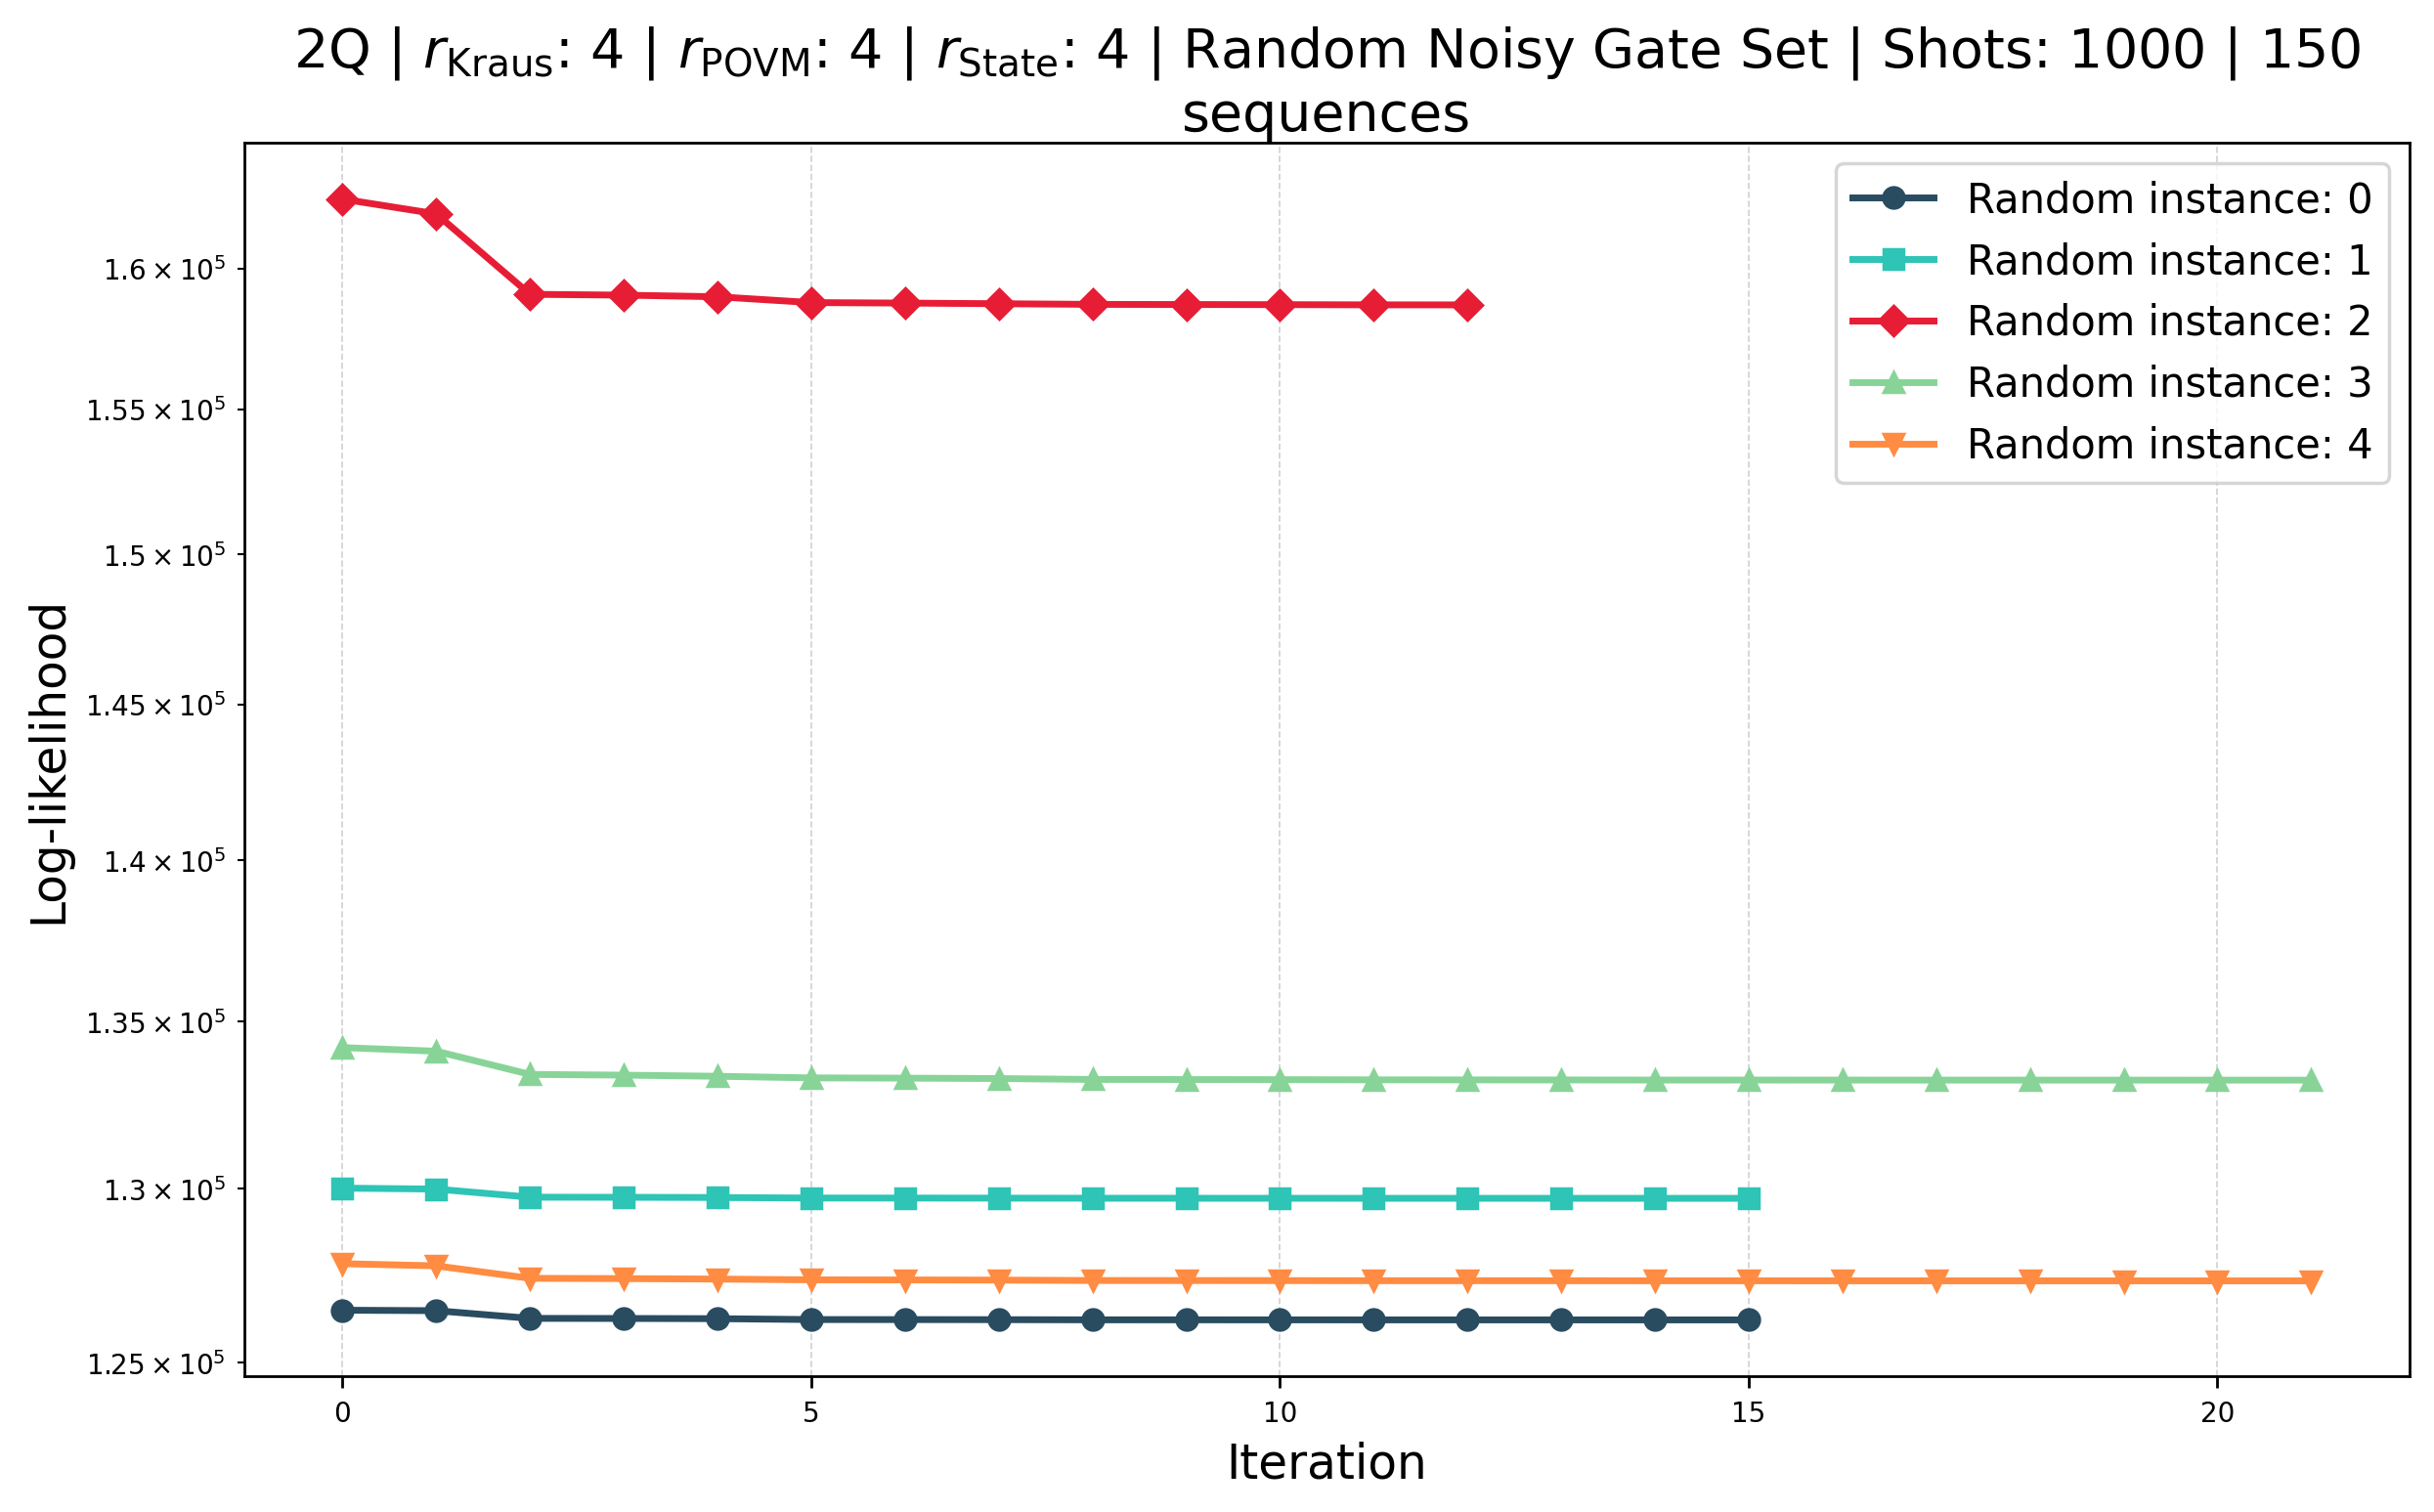

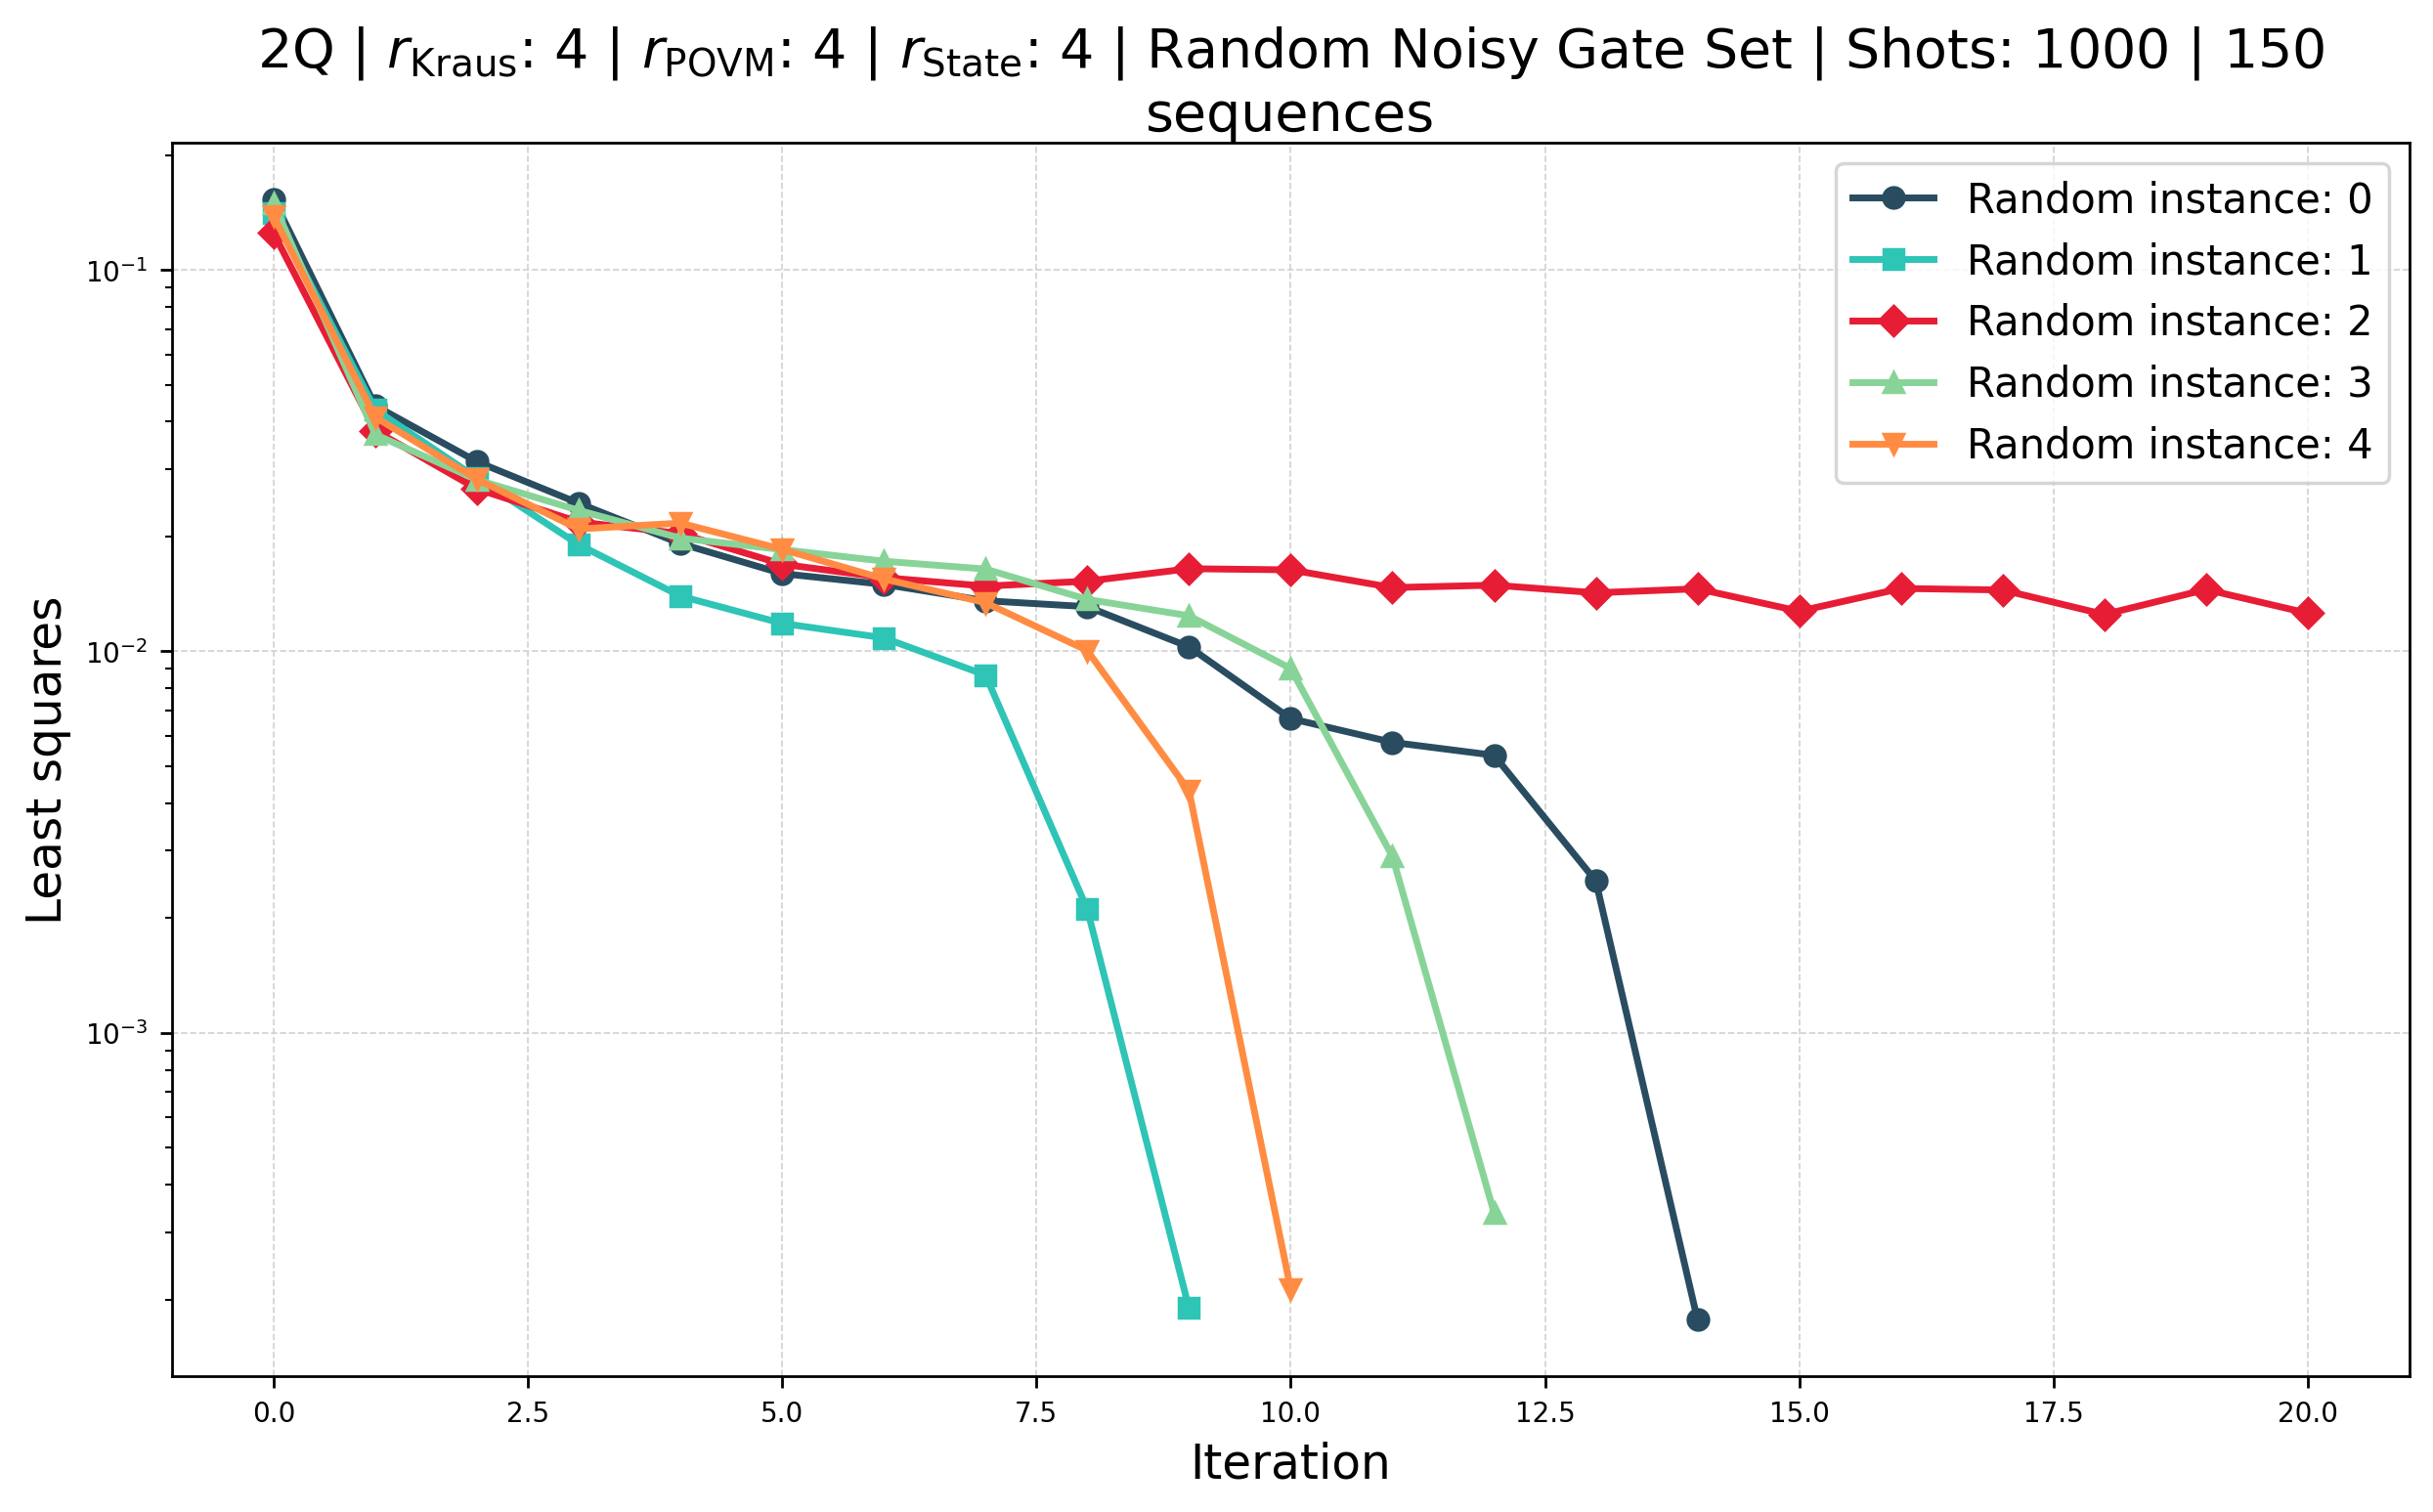

In [ ]:
sequences_test = 150

final_results_test = get_all_realizations_for_key(final_results_100_150, str(sequences_test))

costs_test_final = [res["cost_fn_history"]["main"] for res in final_results_test]
labels_random_inits = [f"Random instance: {i}" for i in range(len(final_results_test))]

title = title_init + f" | {sequences_test} sequences"

plot_cost_function(costs_test_final[:], title=title, labels=labels_random_inits[:], ylabel="Log-likelihood")

partial_results_test = get_all_realizations_for_key(partial_results_100_150, str(sequences_test))

costs_test_partial = [res["cost_fn_history"]["main"] for res in partial_results_test]

plot_cost_function(costs_test_partial[:], title=title, labels=labels_random_inits[:], ylabel="Least squares")

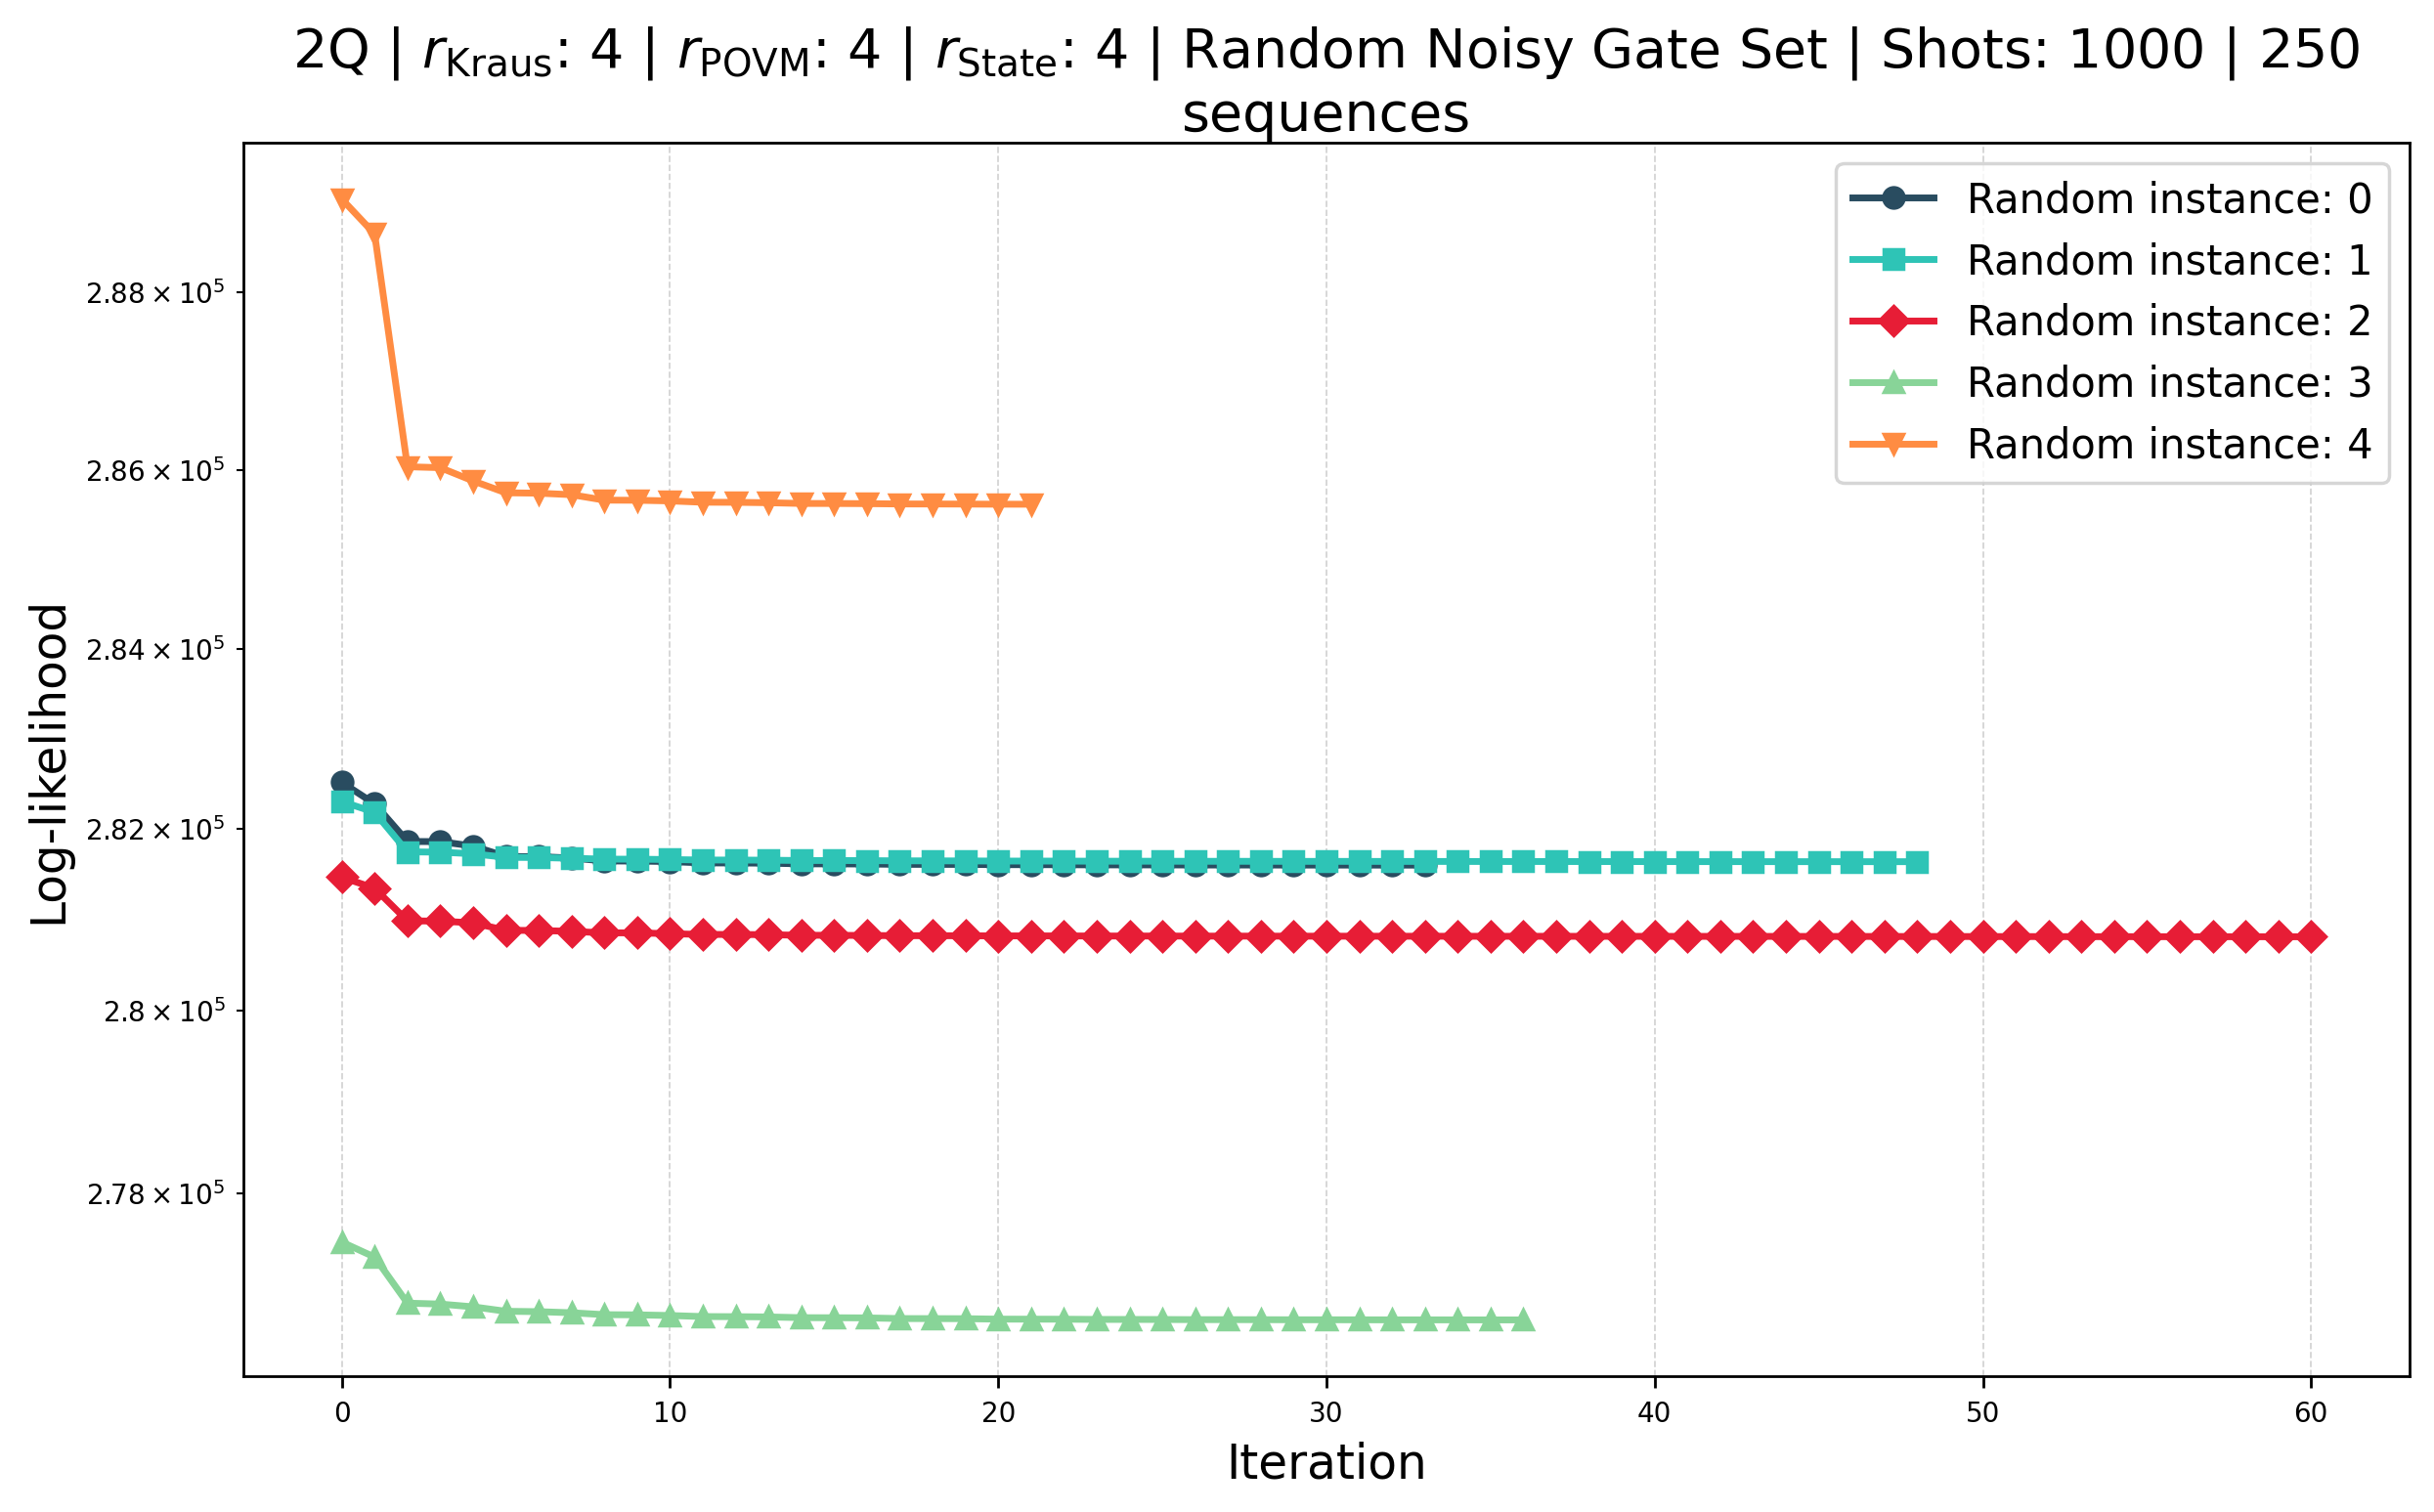

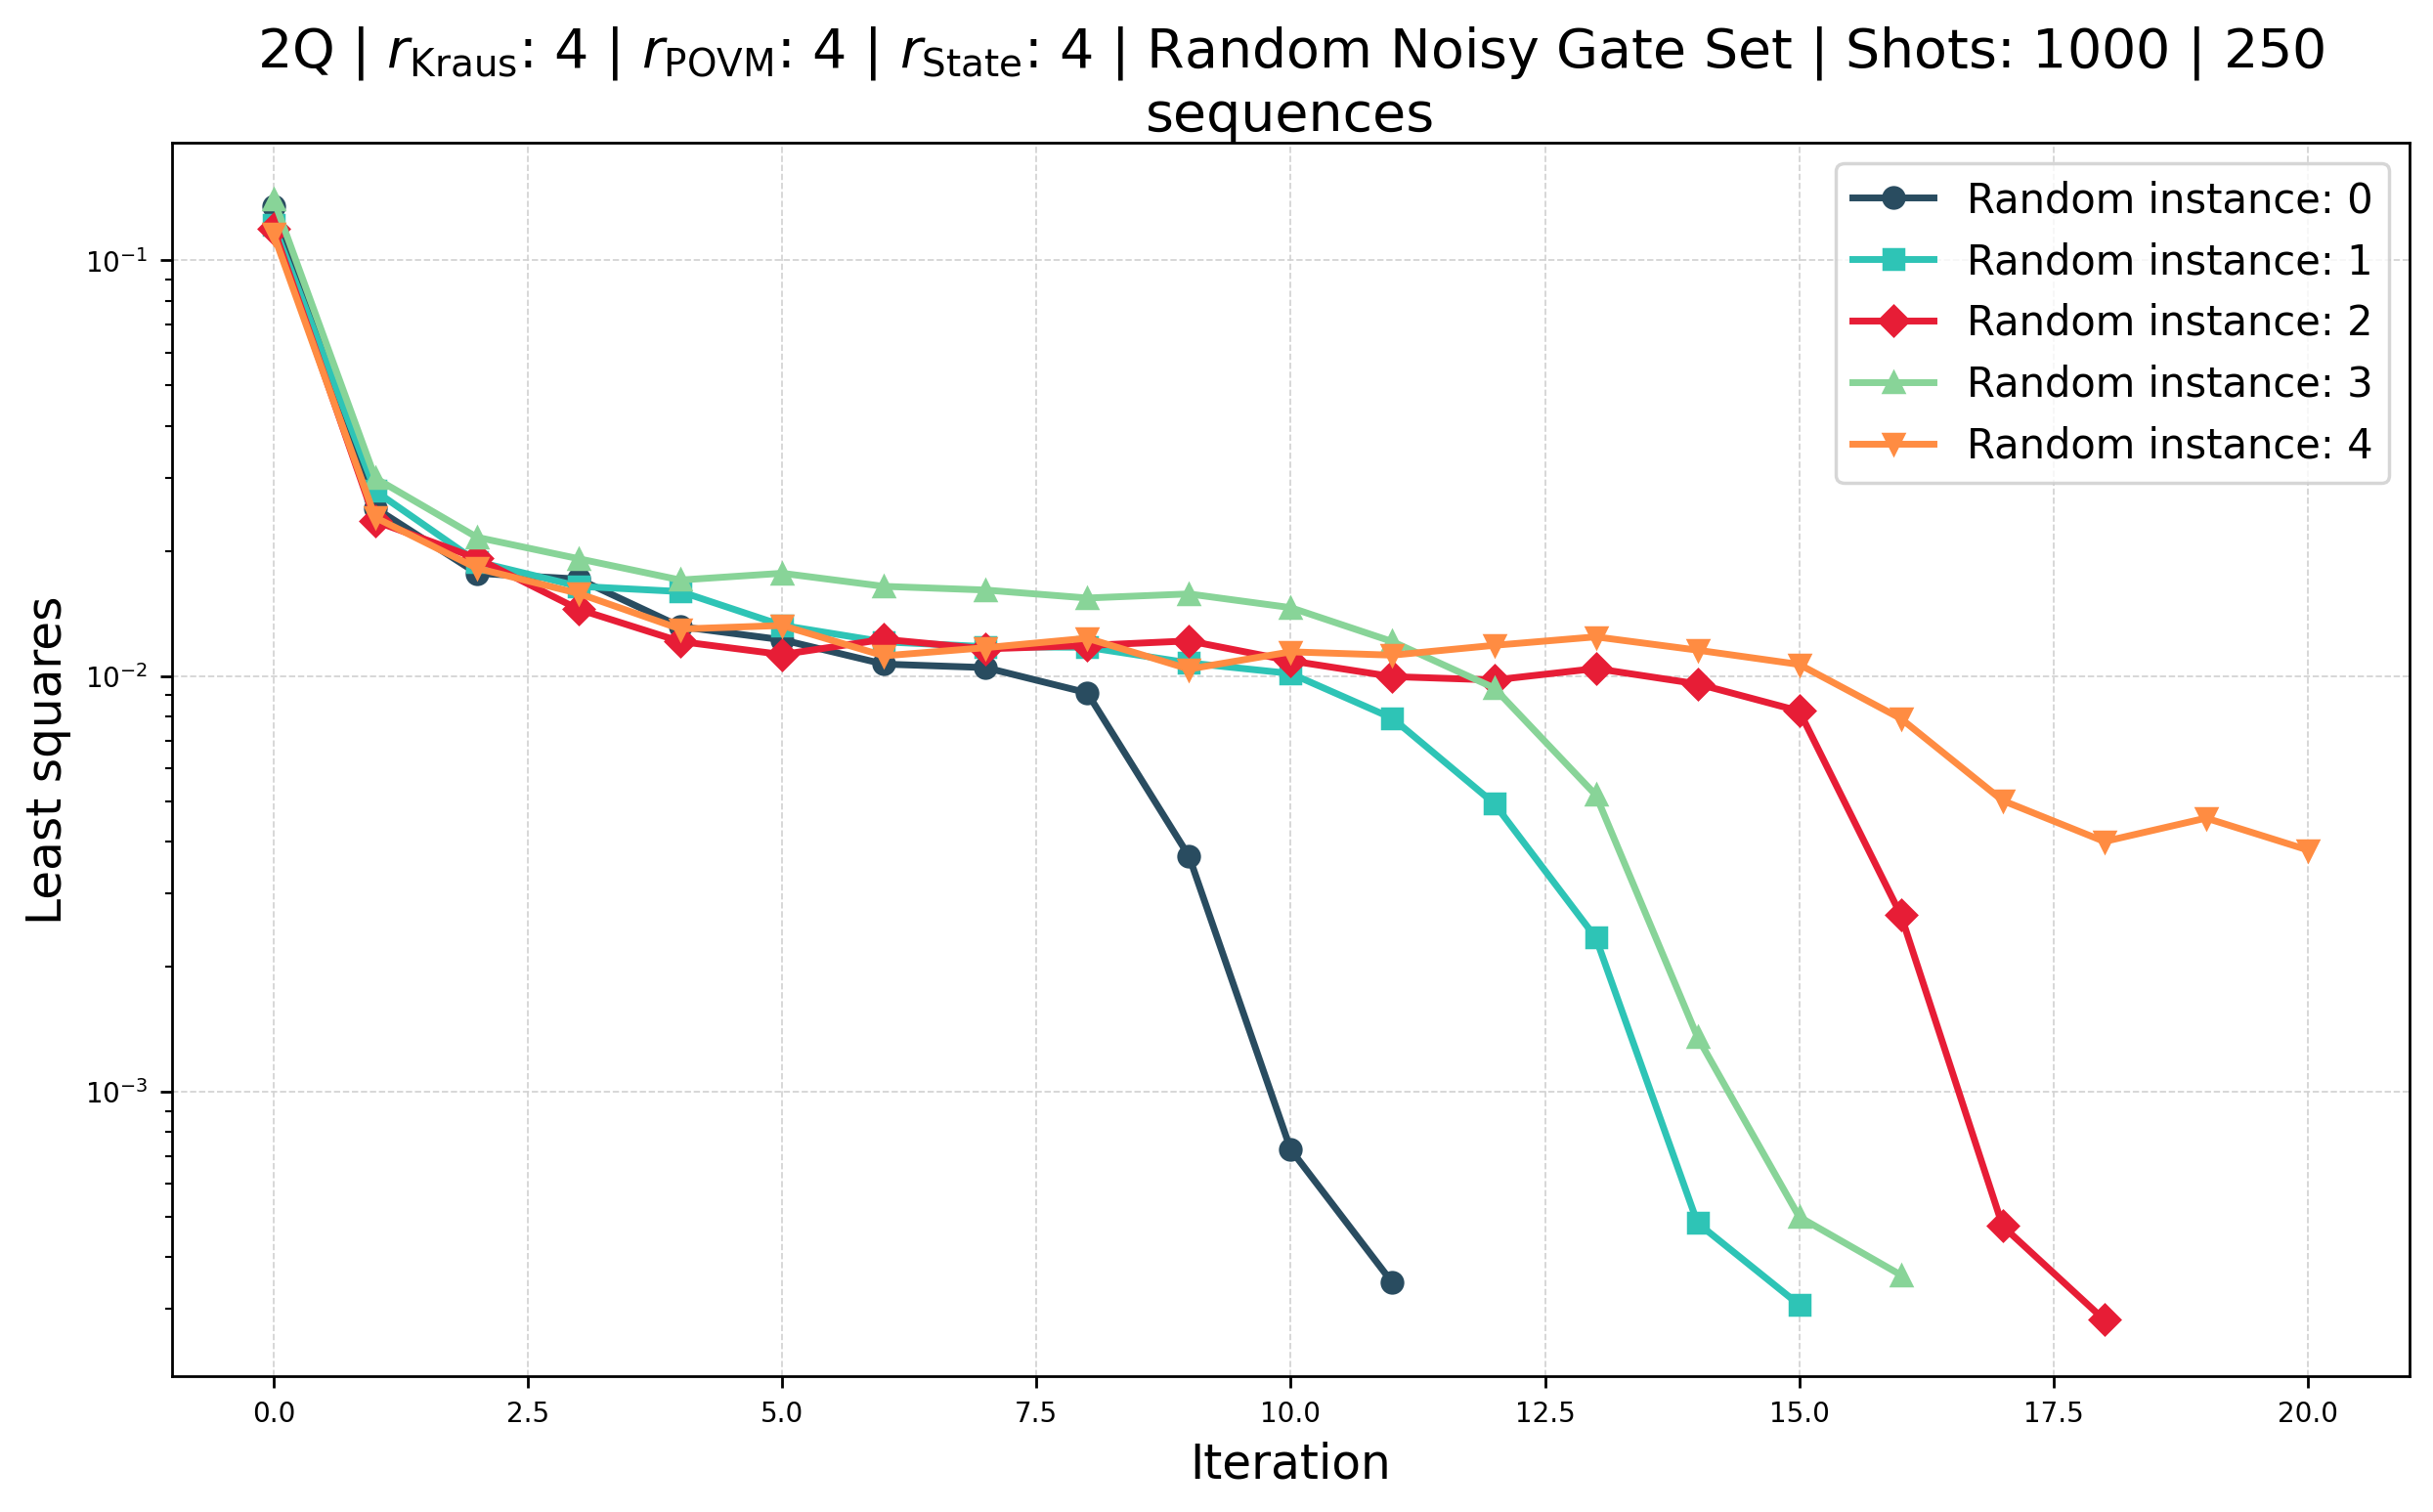

In [43]:
sequences_test = 250

final_results_test = get_all_realizations_for_key(final_results_210_250, str(sequences_test))

costs_test_final = [res["cost_fn_history"]["main"] for res in final_results_test]
labels_random_inits = [f"Random instance: {i}" for i in range(len(final_results_test))]

title = title_init + f" | {sequences_test} sequences"

plot_cost_function(costs_test_final[:], title=title, labels=labels_random_inits[:], ylabel="Log-likelihood")

partial_results_test = get_all_realizations_for_key(partial_results_210_250, str(sequences_test))

costs_test_partial = [res["cost_fn_history"]["main"] for res in partial_results_test]

plot_cost_function(costs_test_partial[:], title=title, labels=labels_random_inits[:], ylabel="Least squares")

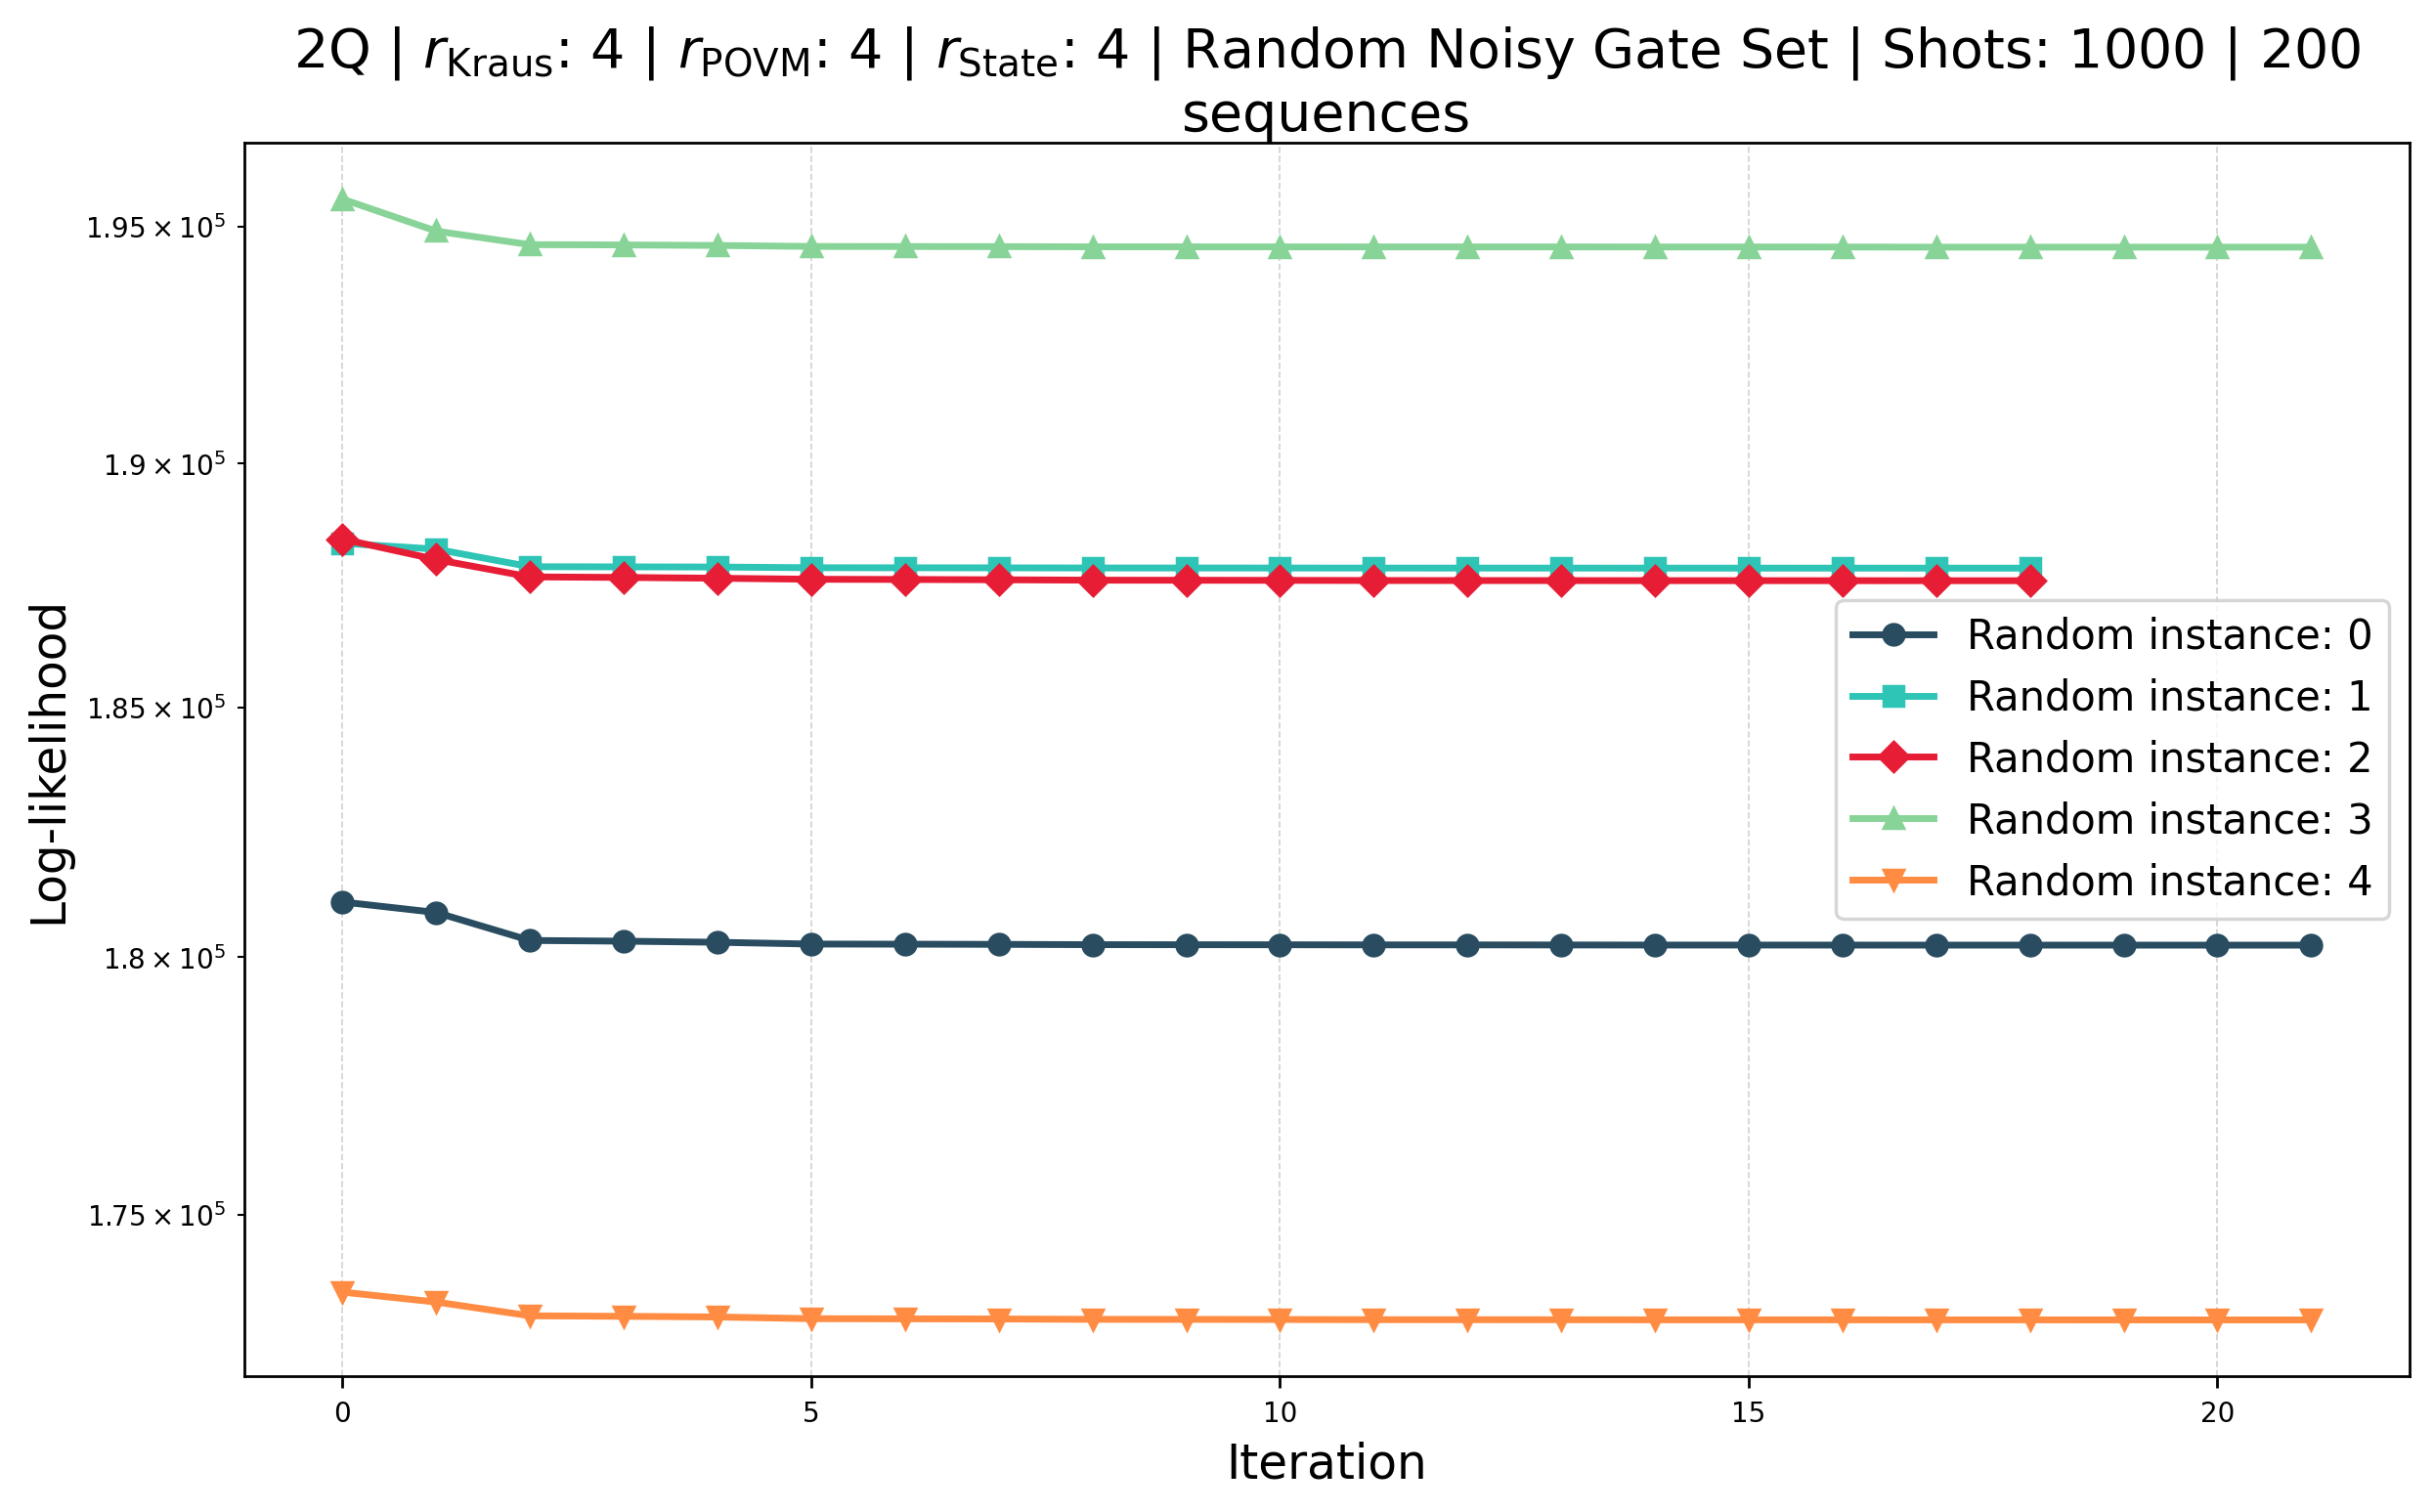

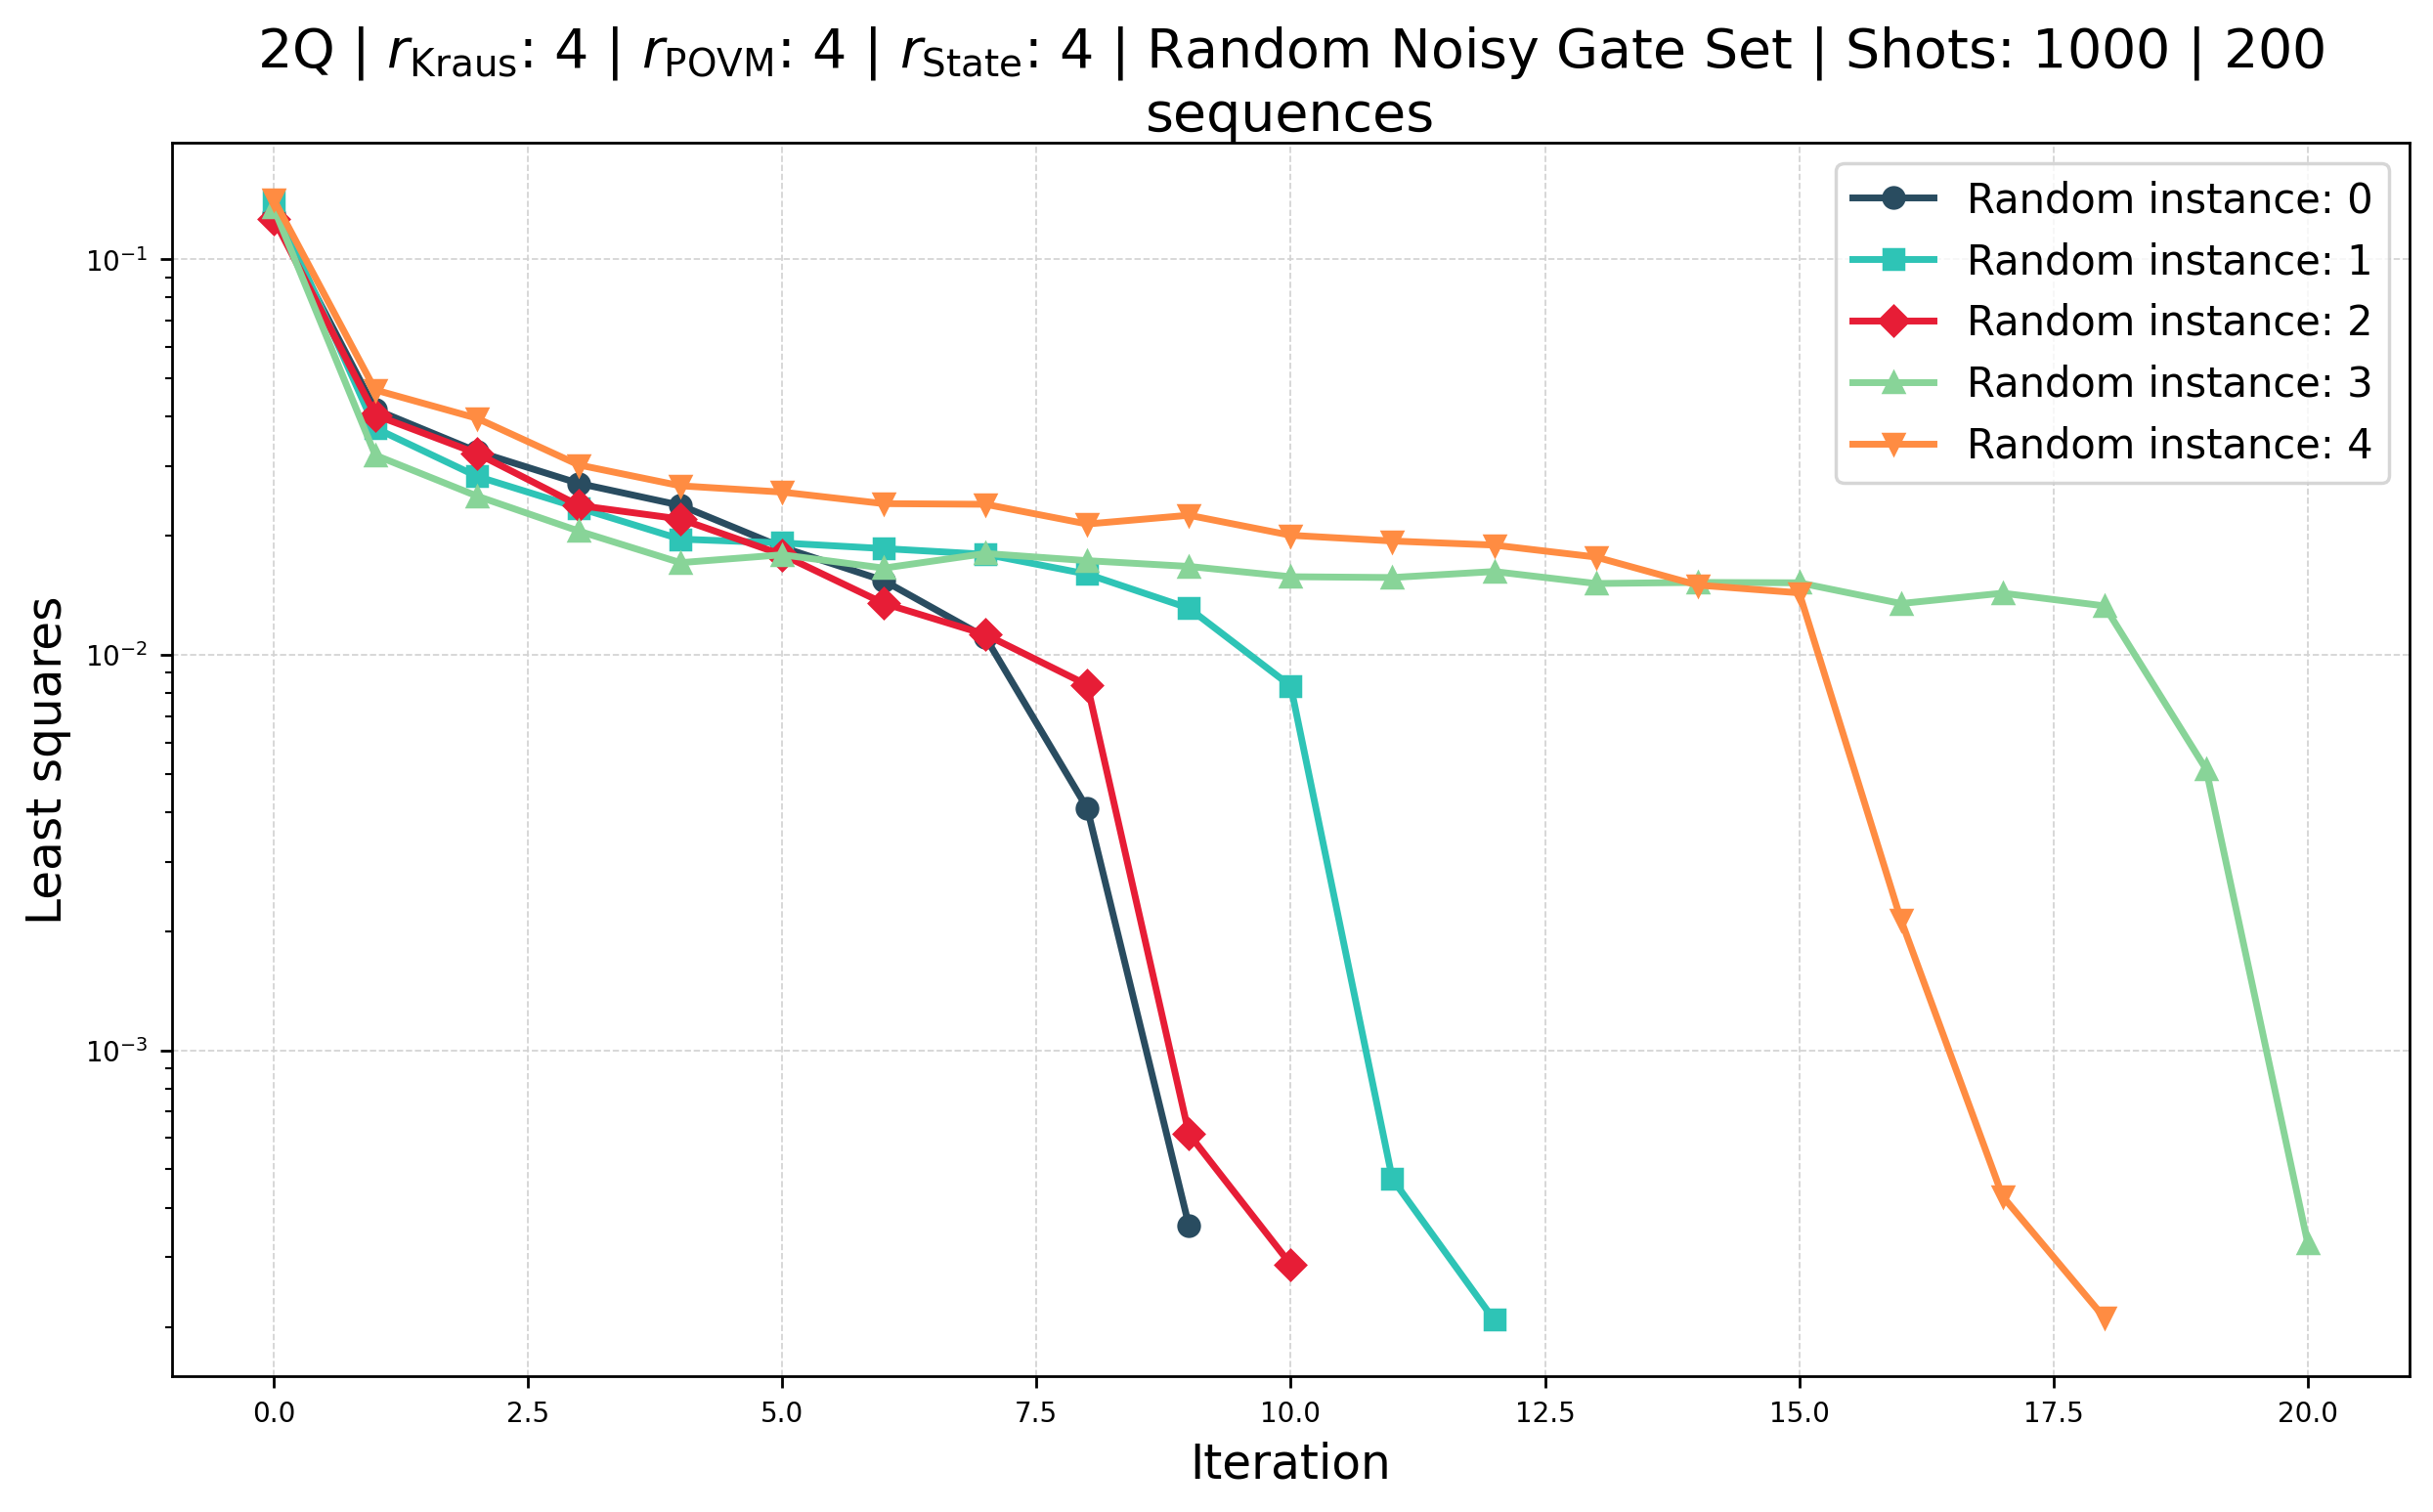

In [50]:
sequences_test = 200

final_results_test = get_all_realizations_for_key(final_results_200_250, str(sequences_test))

costs_test_final = [res["cost_fn_history"]["main"] for res in final_results_test]
labels_random_inits = [f"Random instance: {i}" for i in range(len(final_results_test))]

title = title_init + f" | {sequences_test} sequences"

plot_cost_function(costs_test_final[:], title=title, labels=labels_random_inits[:], ylabel="Log-likelihood")

partial_results_test = get_all_realizations_for_key(partial_results_200_250, str(sequences_test))

costs_test_partial = [res["cost_fn_history"]["main"] for res in partial_results_test]

plot_cost_function(costs_test_partial[:], title=title, labels=labels_random_inits[:], ylabel="Least squares")

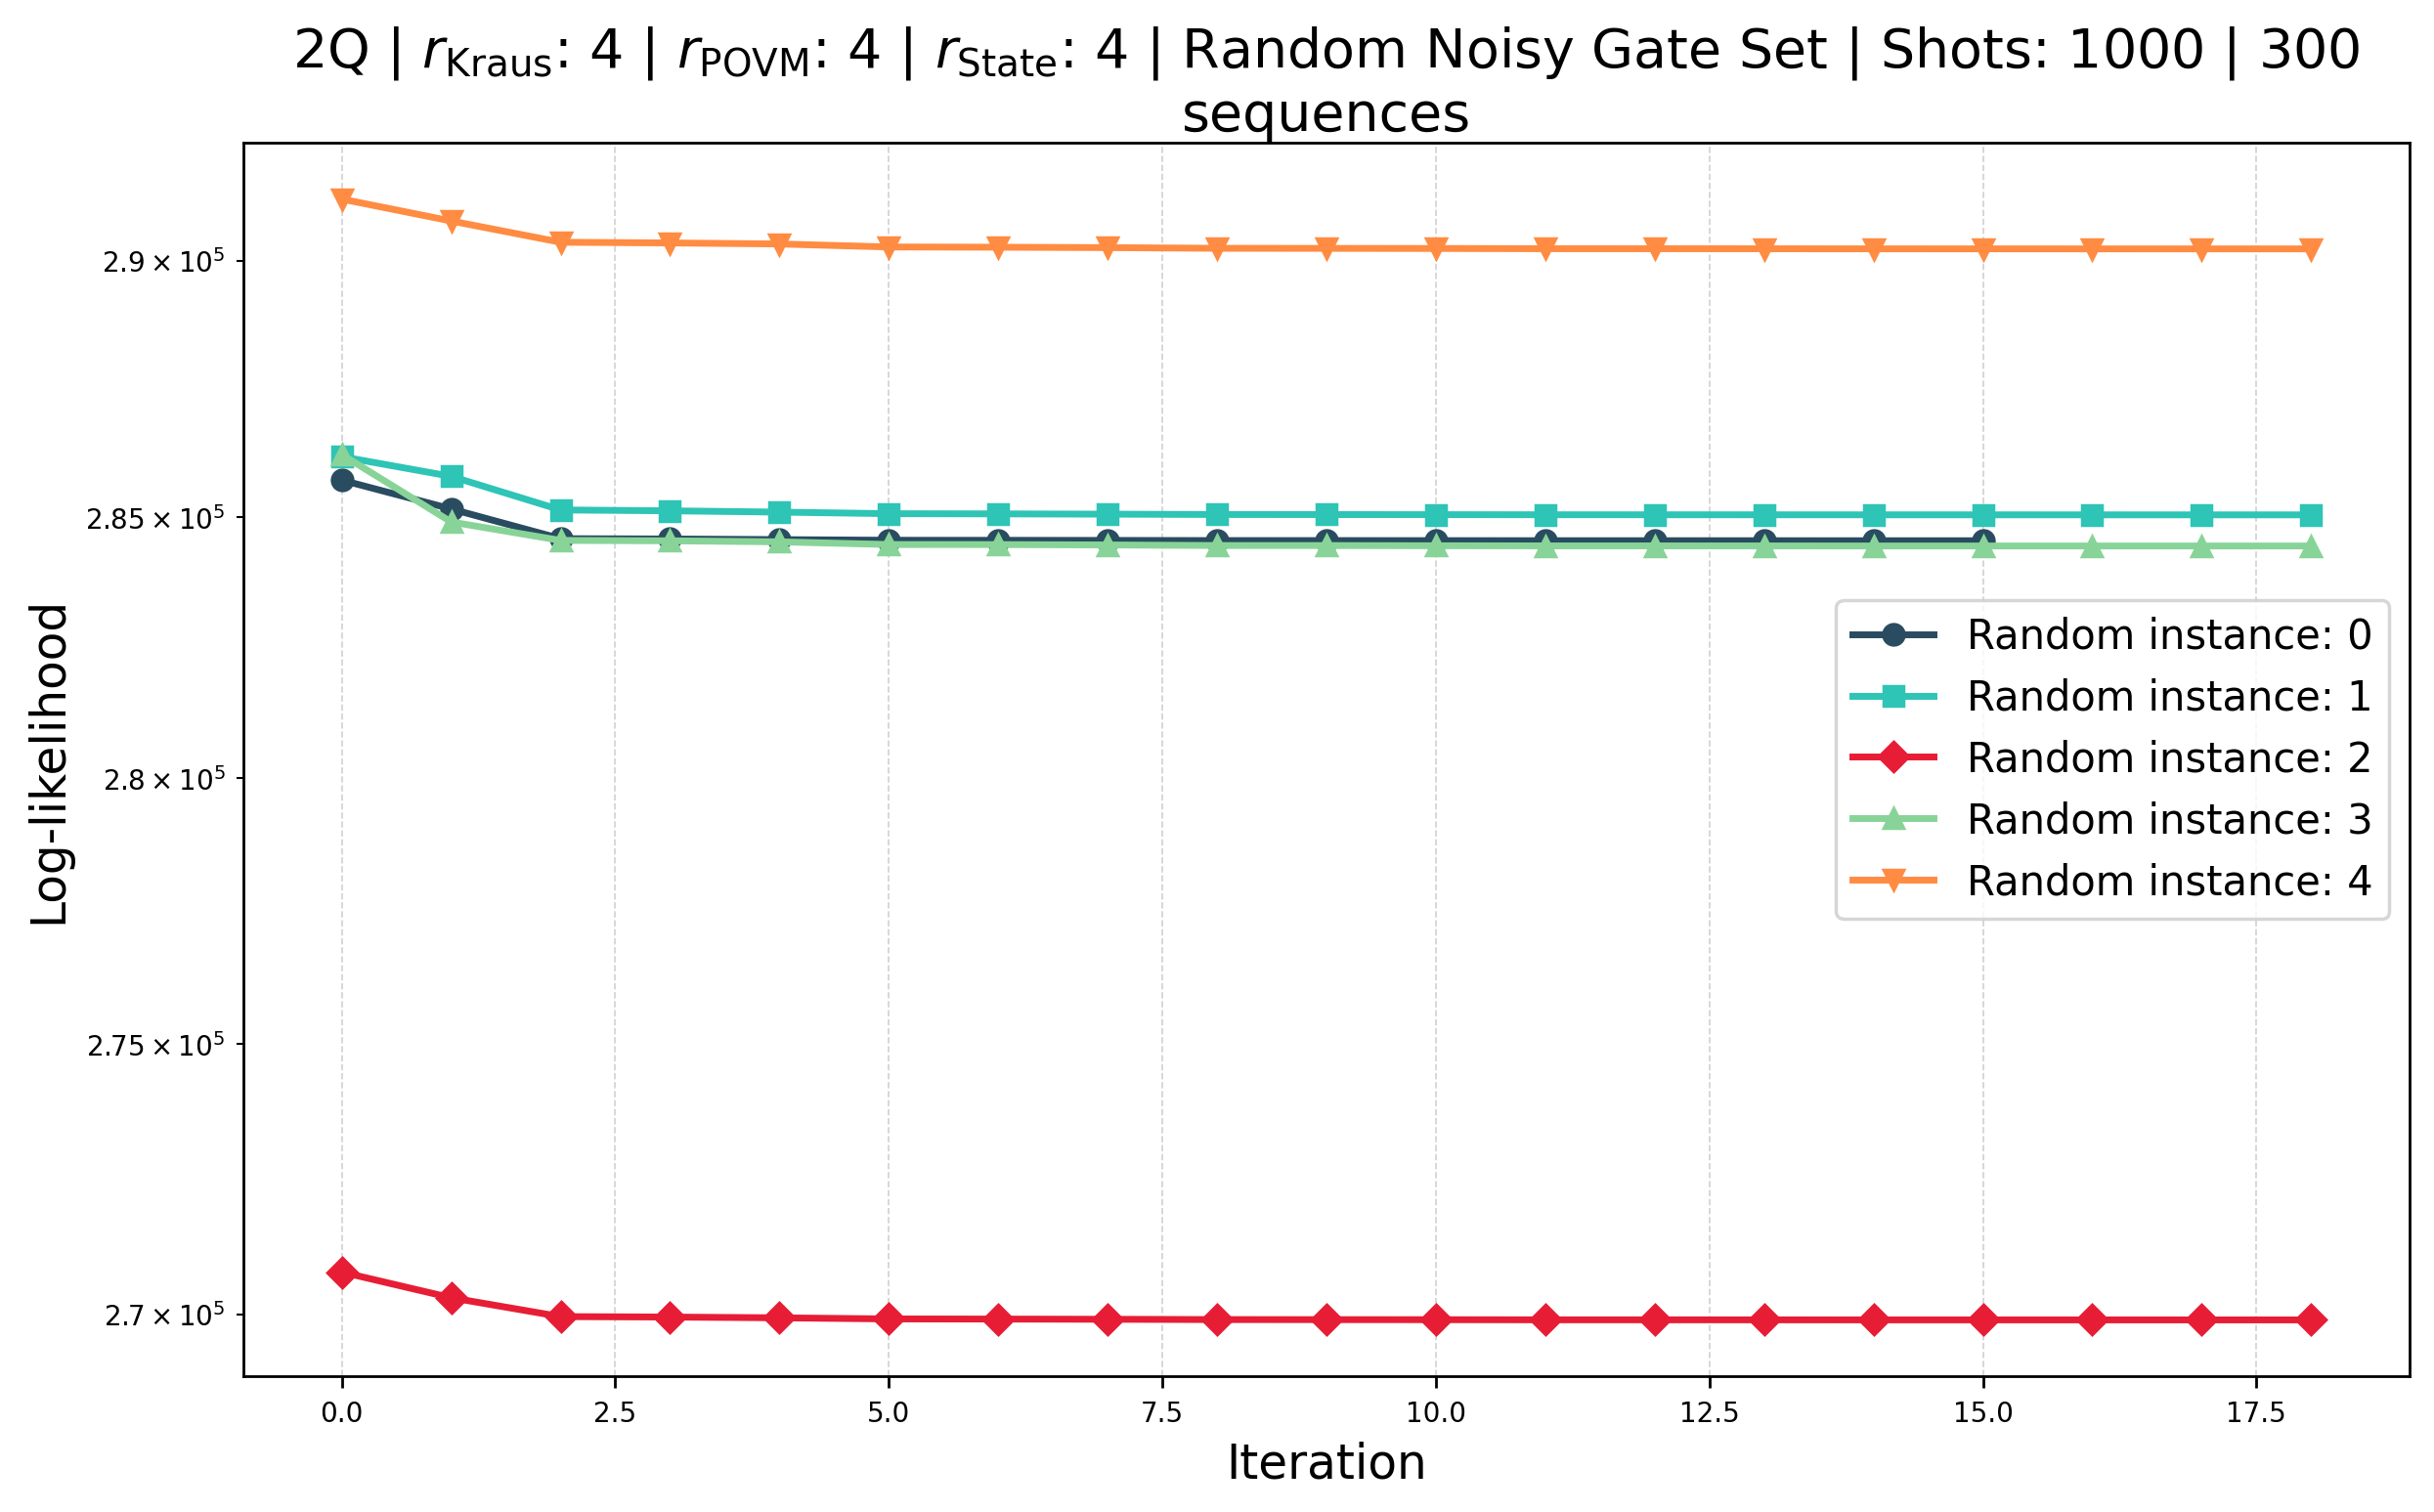

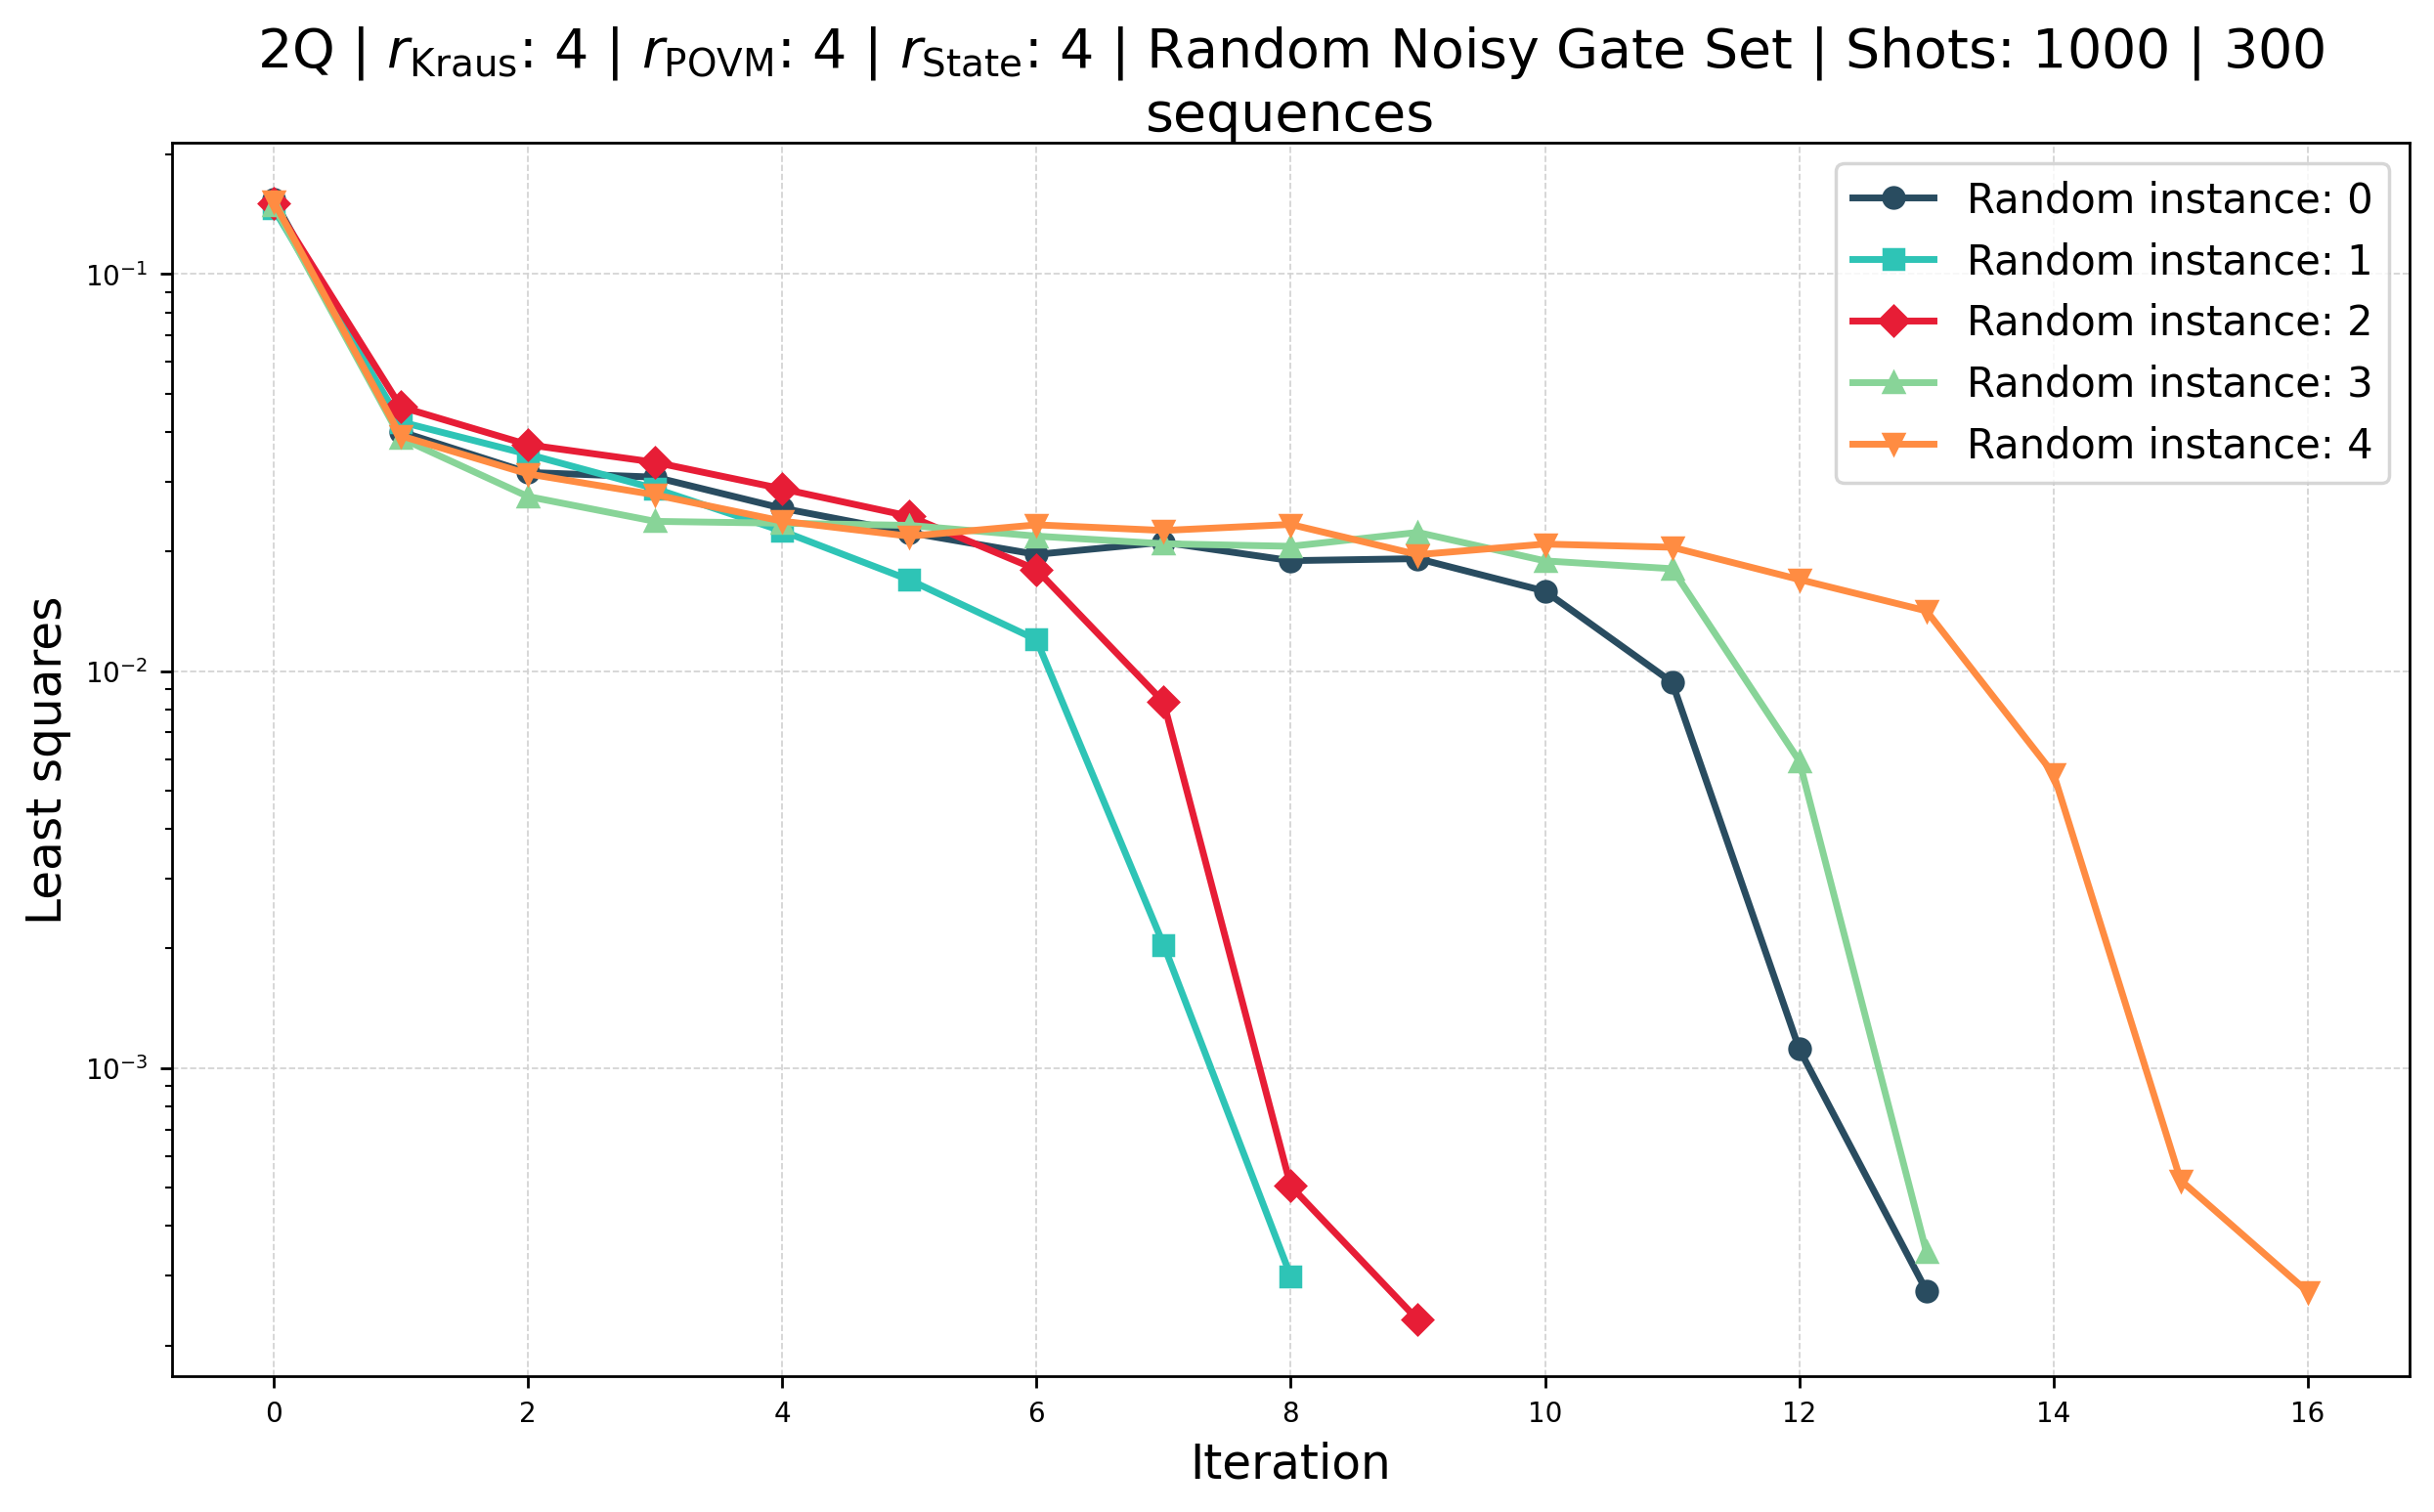

In [36]:
sequences_test = 300

final_results_test = get_all_realizations_for_key(final_results_300_350, str(sequences_test))

costs_test_final = [res["cost_fn_history"]["main"] for res in final_results_test]
labels_random_inits = [f"Random instance: {i}" for i in range(len(final_results_test))]

title = title_init + f" | {sequences_test} sequences"

plot_cost_function(costs_test_final[:], title=title, labels=labels_random_inits[:], ylabel="Log-likelihood")

partial_results_test = get_all_realizations_for_key(partial_results_300_350, str(sequences_test))

costs_test_partial = [res["cost_fn_history"]["main"] for res in partial_results_test]

plot_cost_function(costs_test_partial[:], title=title, labels=labels_random_inits[:], ylabel="Least squares")

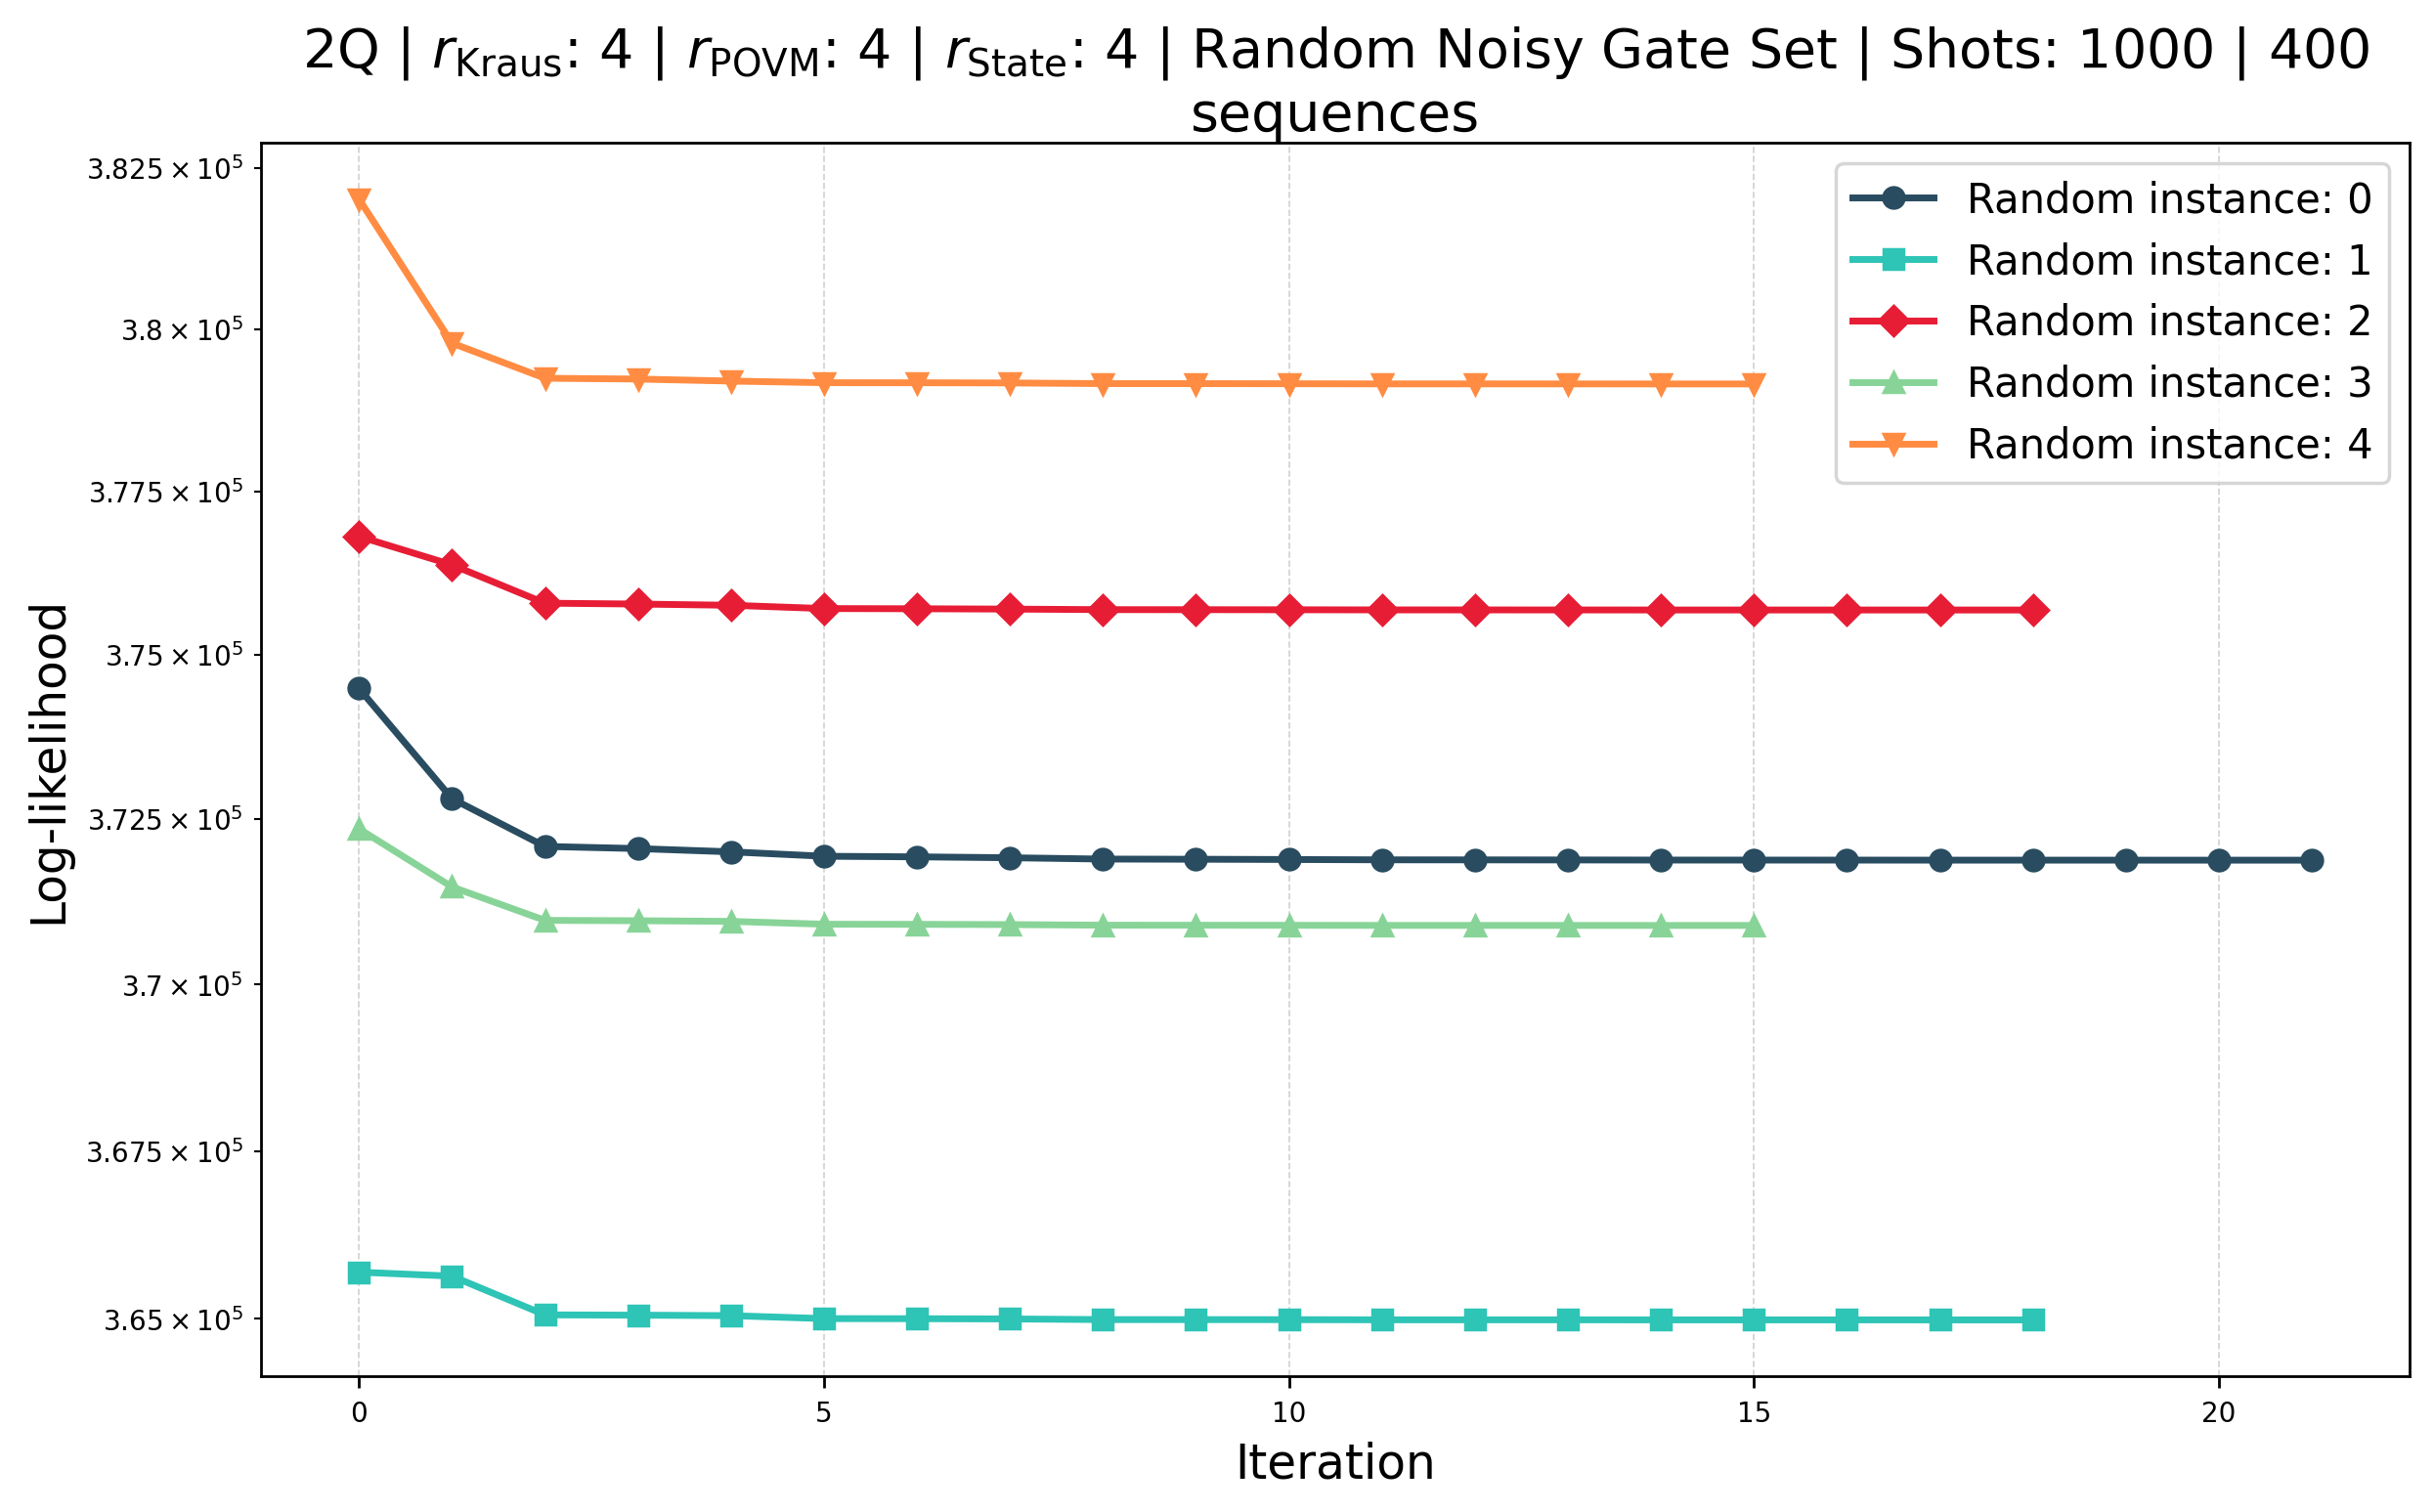

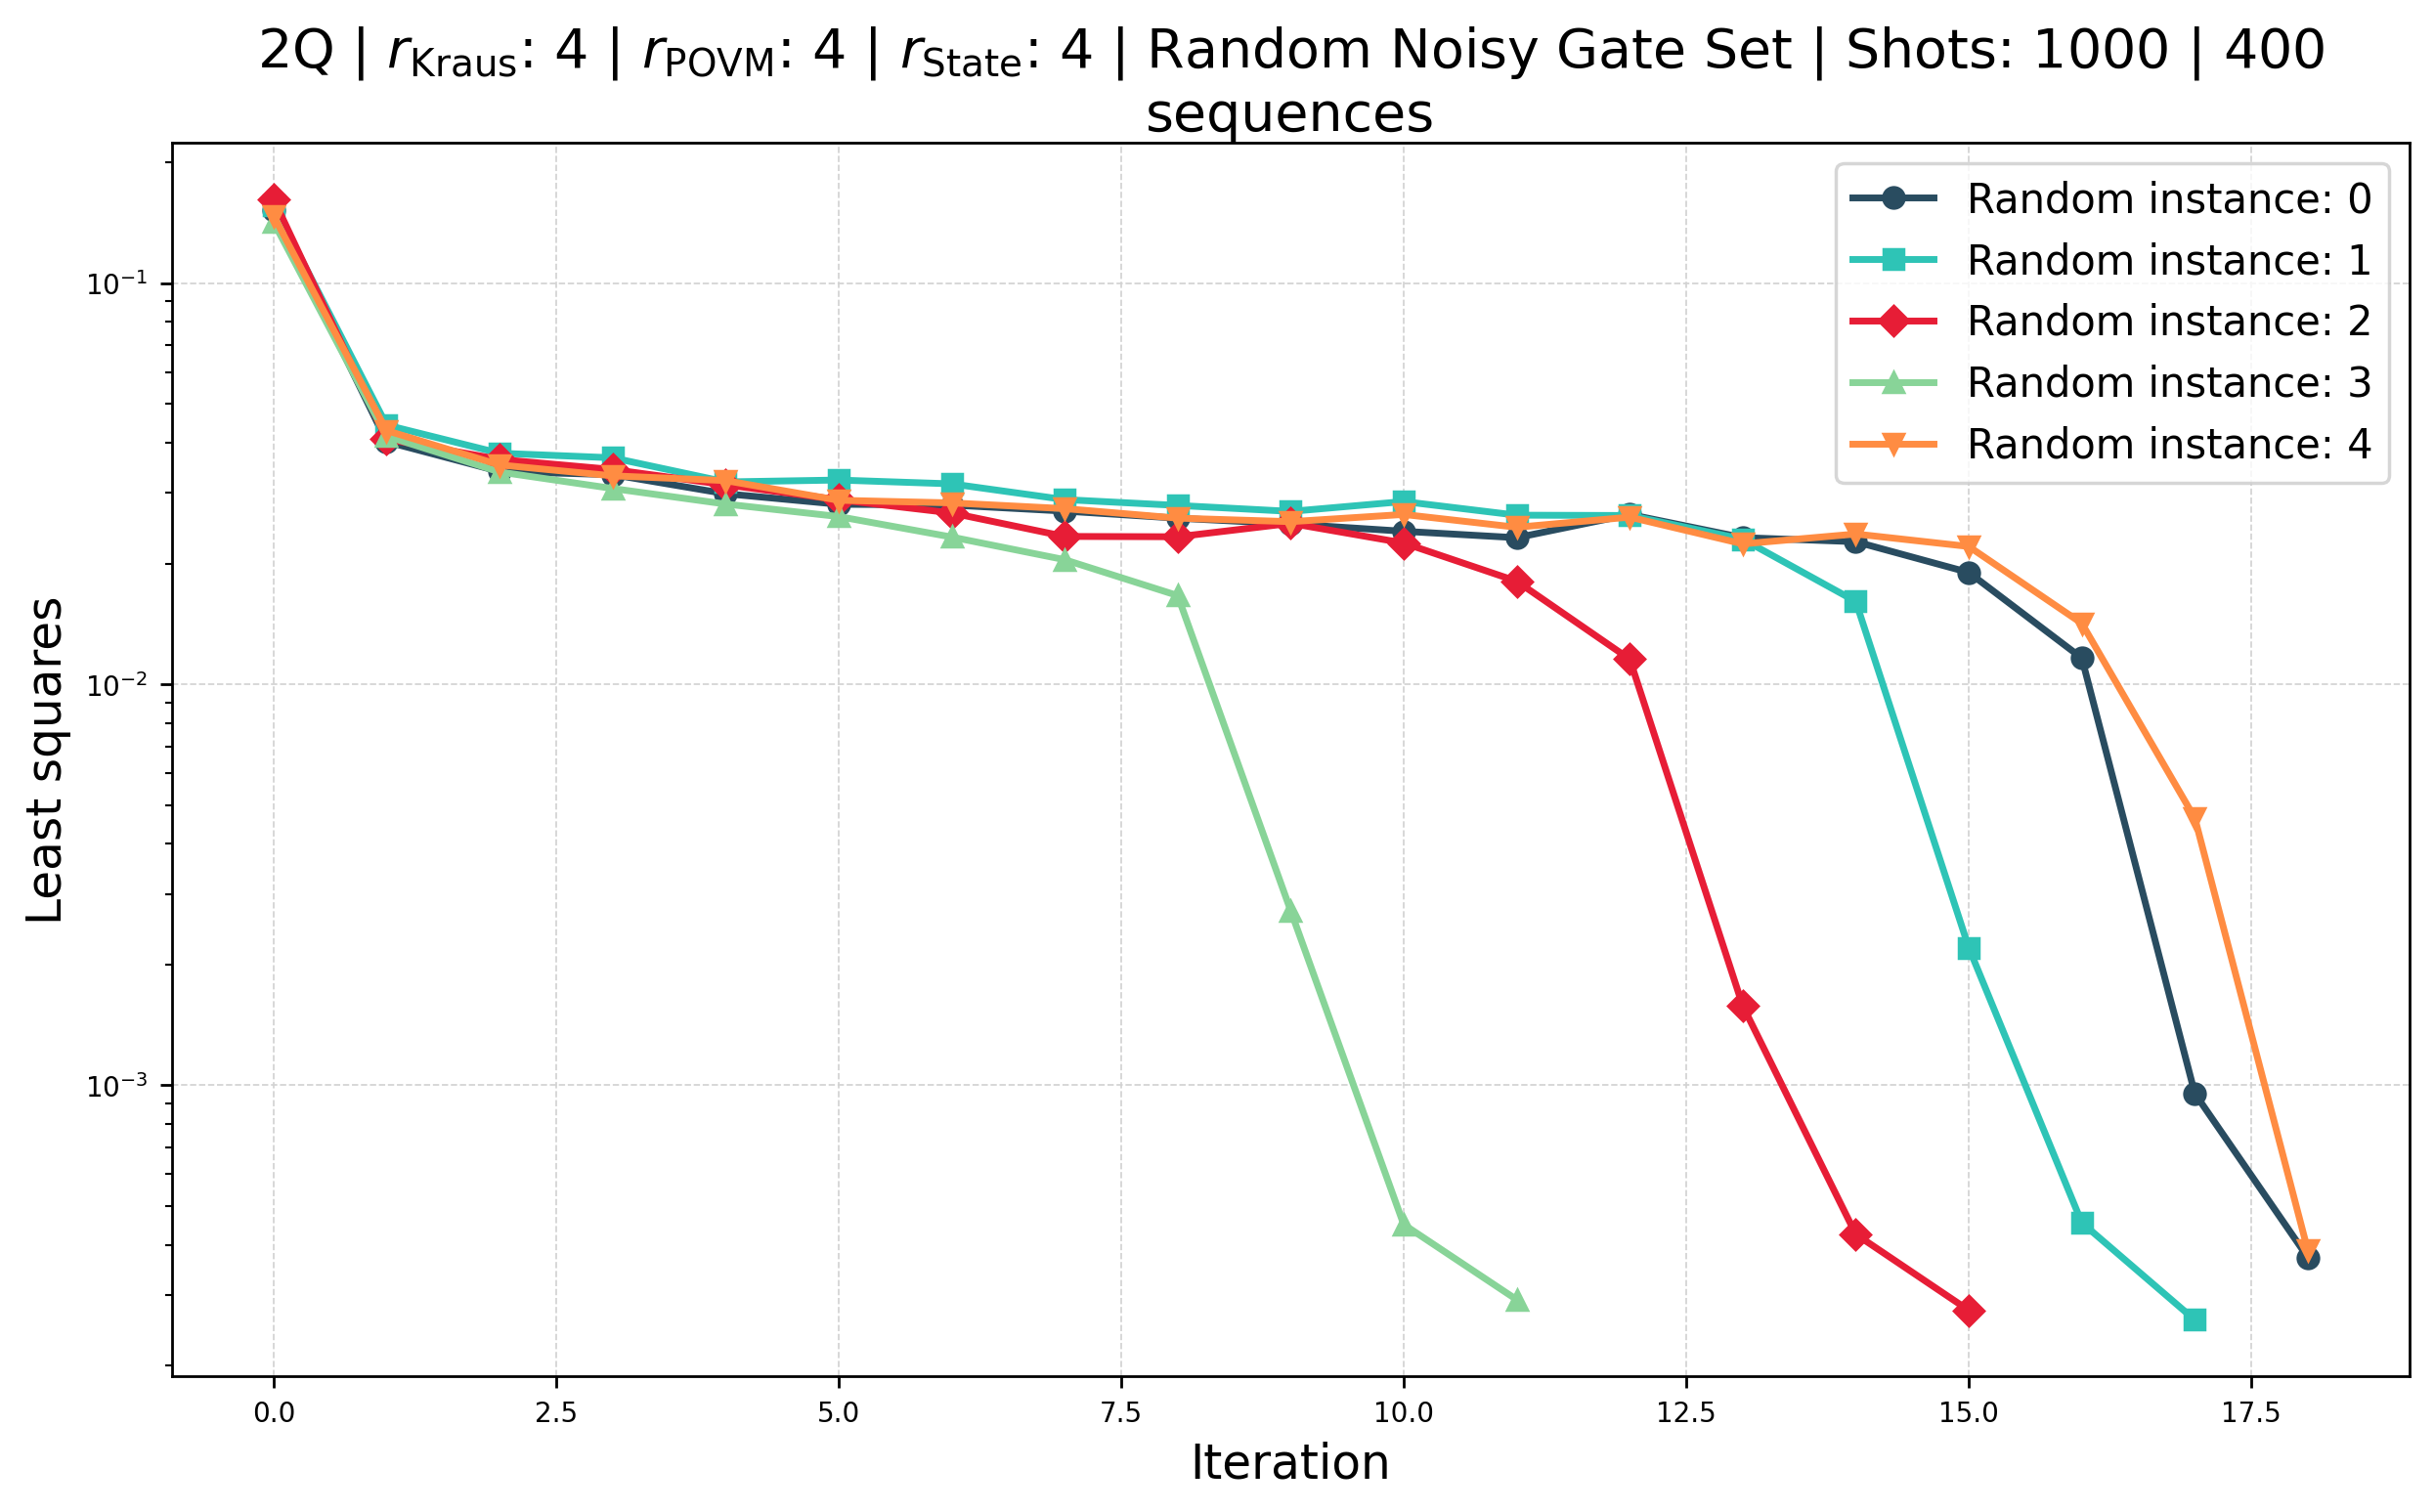

In [33]:
sequences_test = 400

final_results_test = get_all_realizations_for_key(final_results_400_450, str(sequences_test))

costs_test_final = [res["cost_fn_history"]["main"] for res in final_results_test]
labels_random_inits = [f"Random instance: {i}" for i in range(len(final_results_test))]

title = title_init + f" | {sequences_test} sequences"

plot_cost_function(costs_test_final[:], title=title, labels=labels_random_inits[:], ylabel="Log-likelihood")

partial_results_test = get_all_realizations_for_key(partial_results_400_450, str(sequences_test))

costs_test_partial = [res["cost_fn_history"]["main"] for res in partial_results_test]

plot_cost_function(costs_test_partial[:], title=title, labels=labels_random_inits[:], ylabel="Least squares")

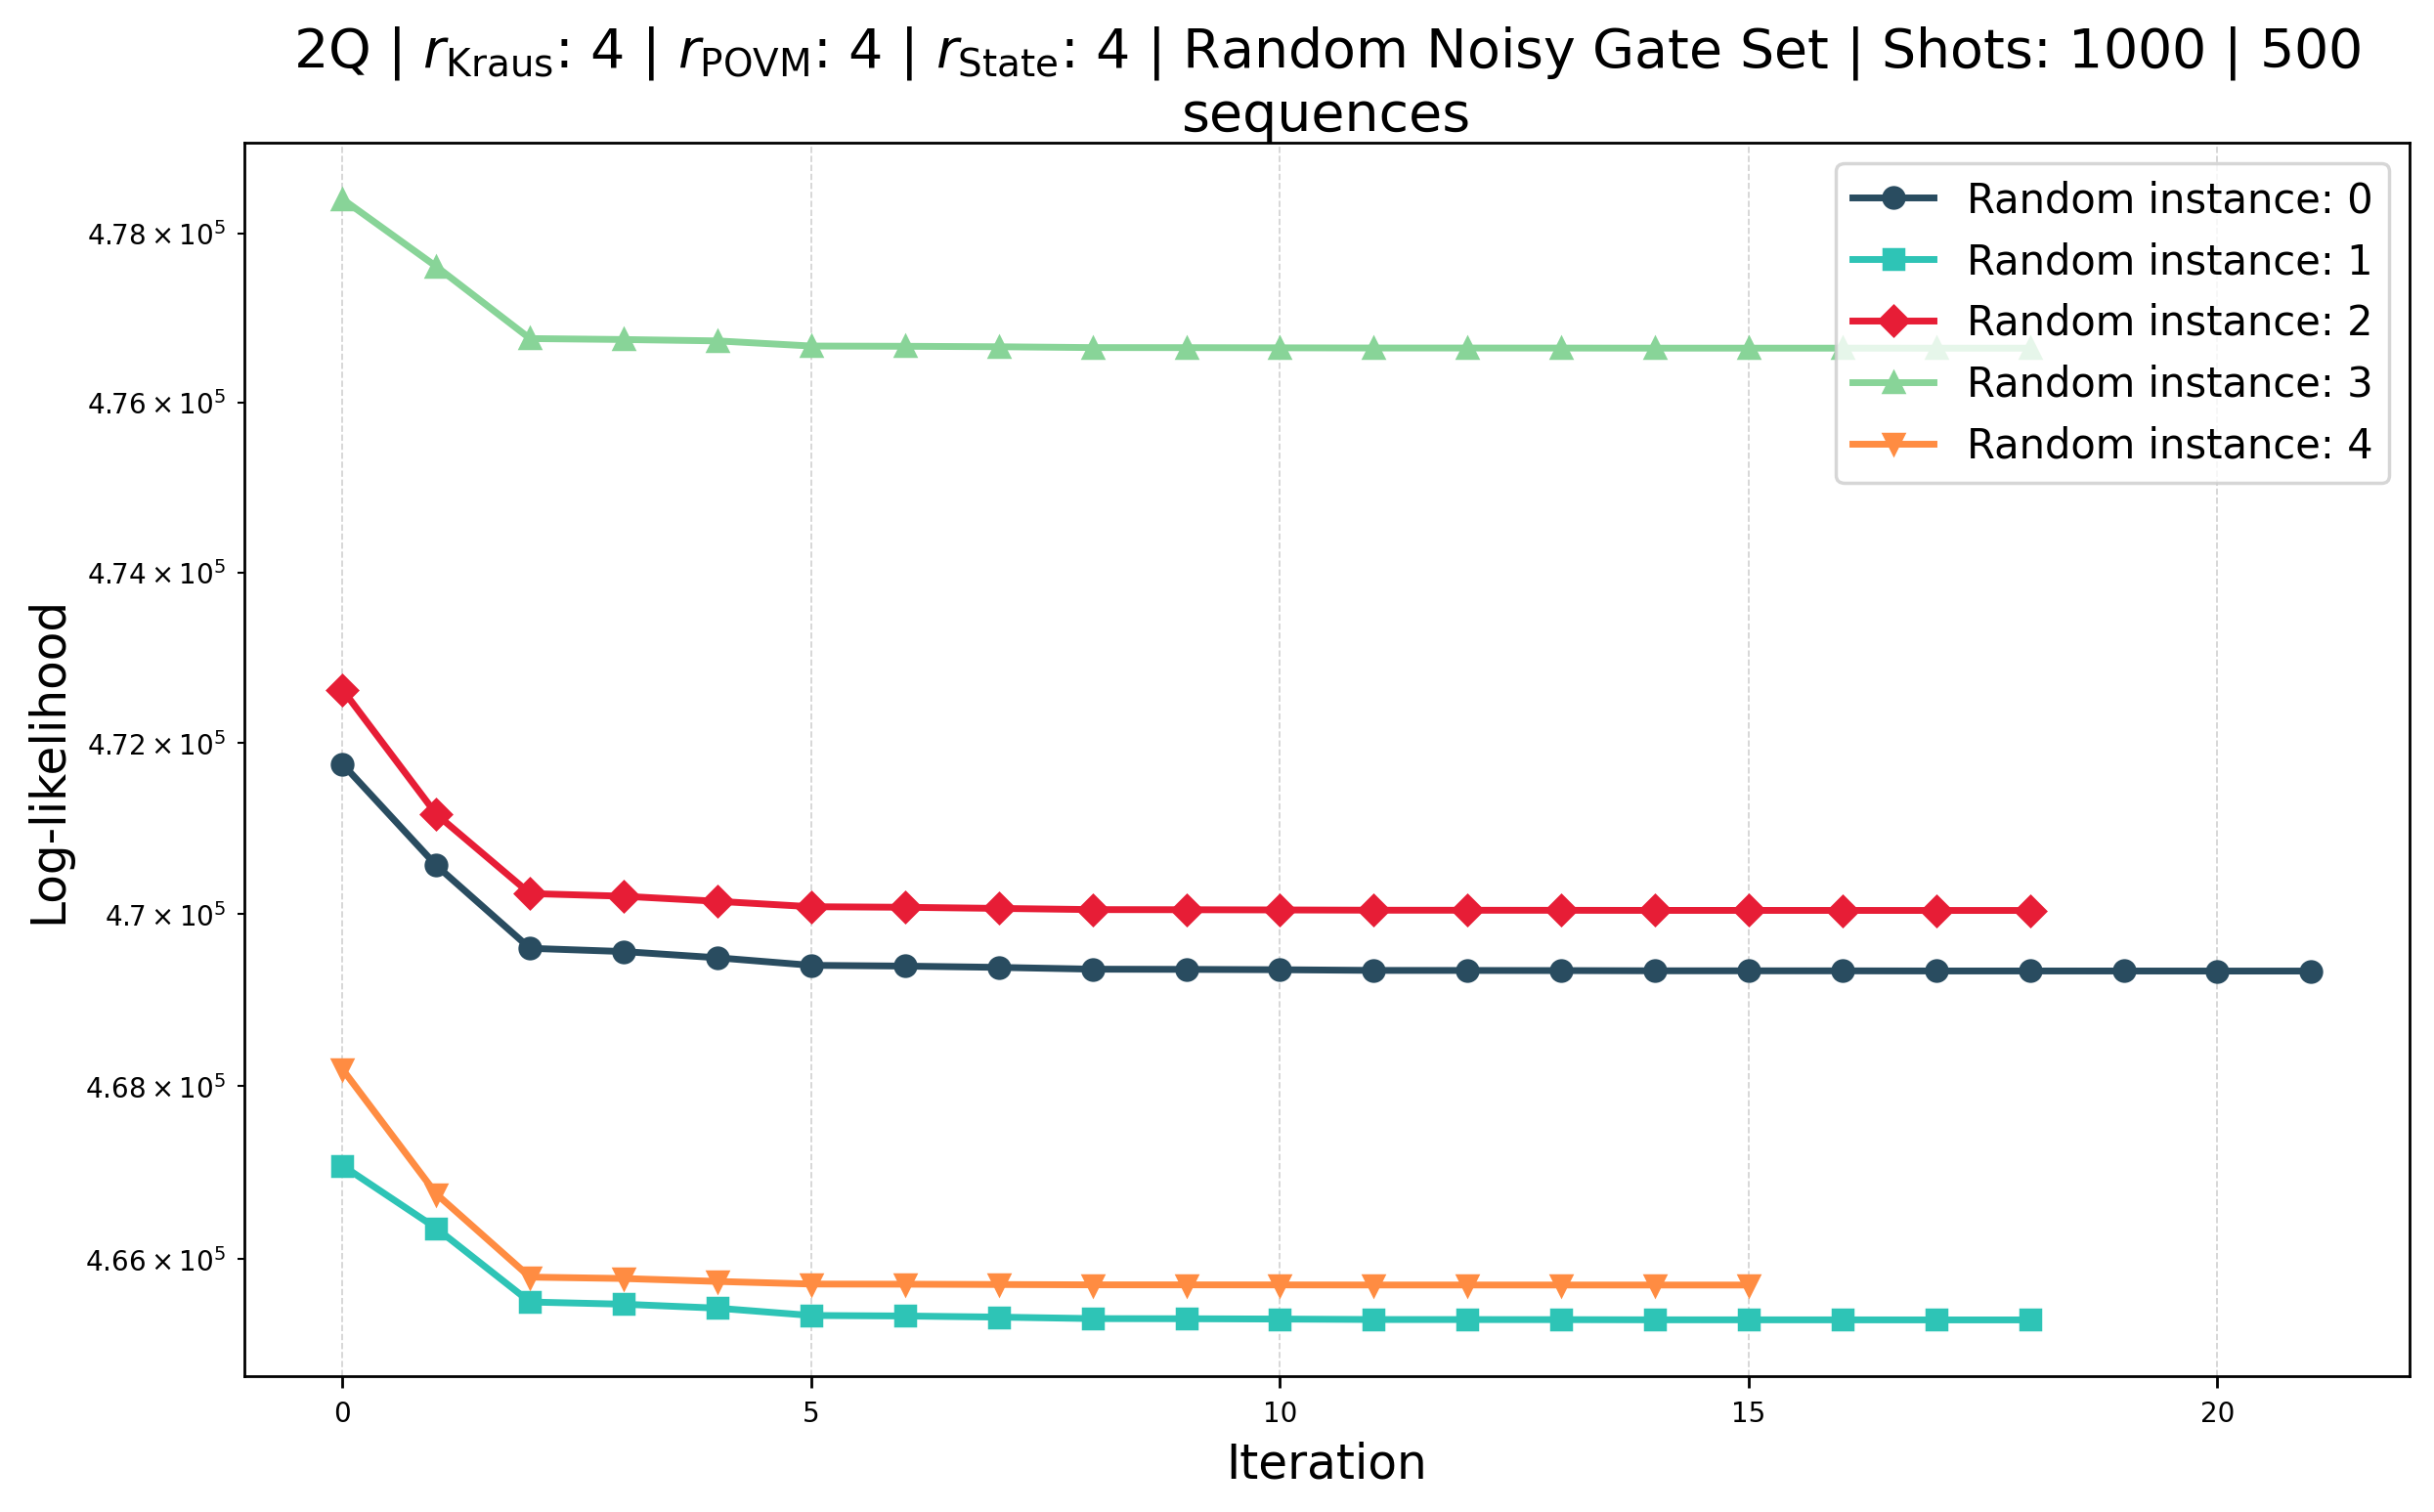

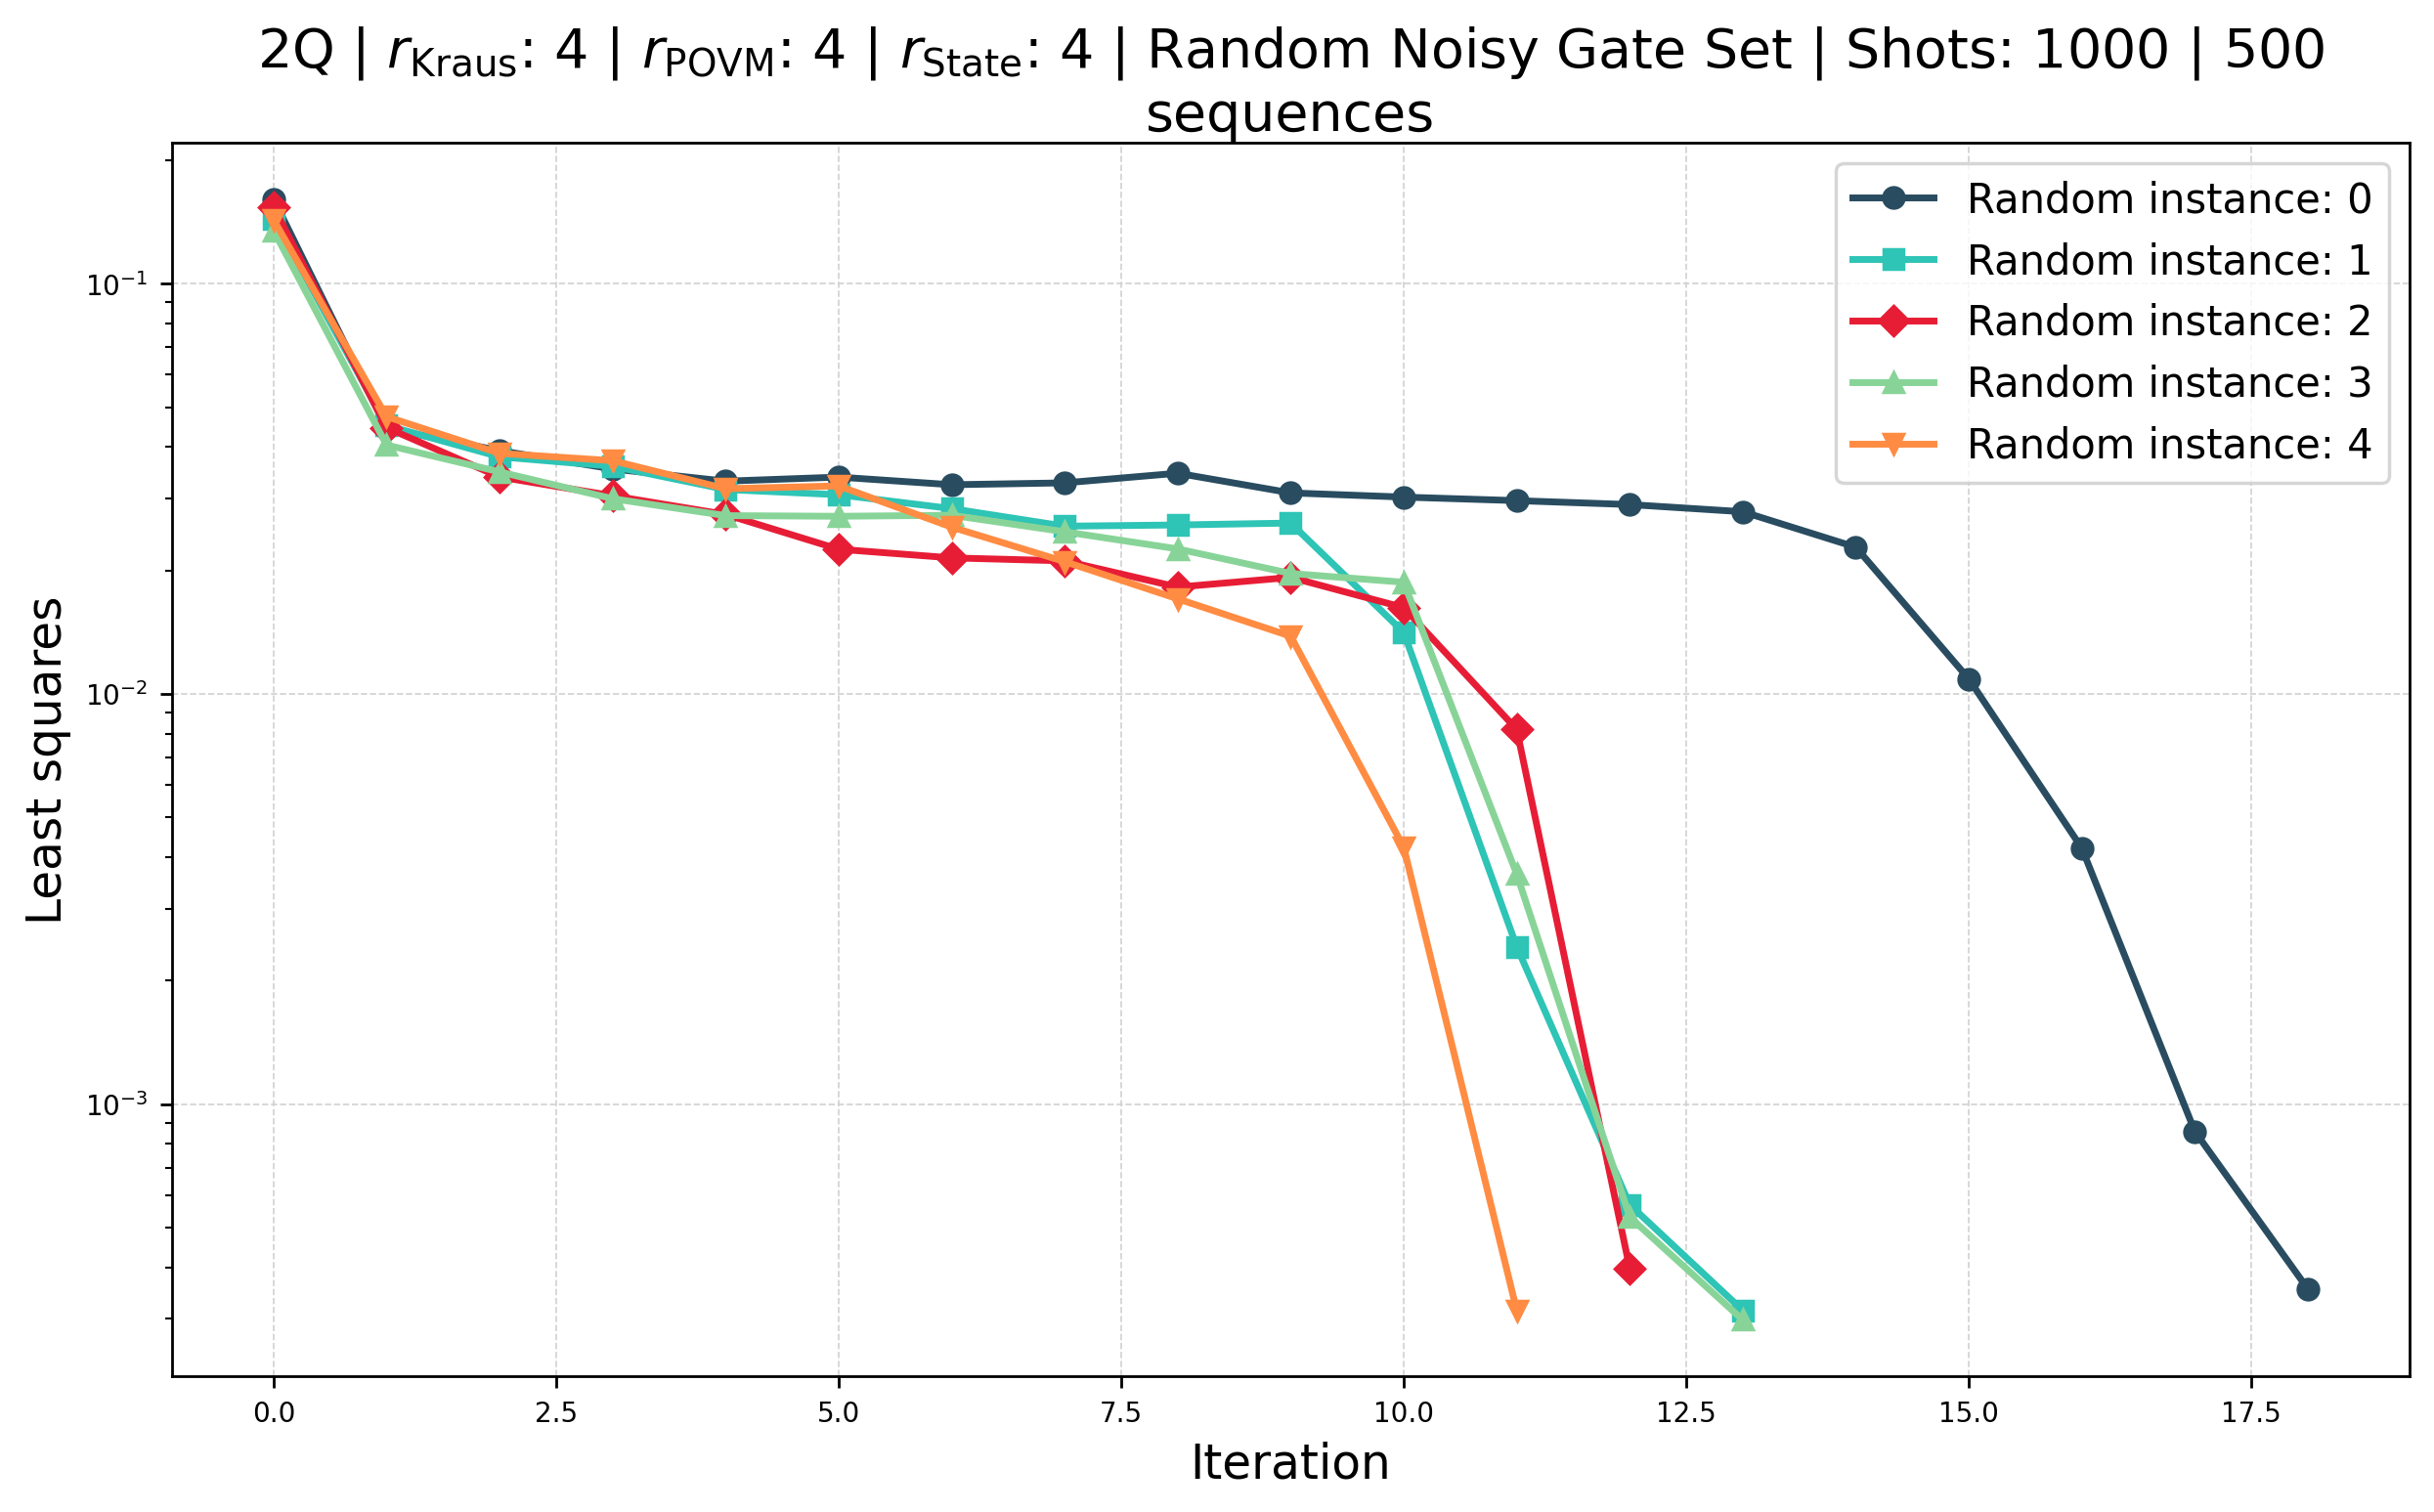

In [30]:
sequences_test = 500

final_results_test = get_all_realizations_for_key(final_results_500_550, str(sequences_test))

costs_test_final = [res["cost_fn_history"]["main"] for res in final_results_test]
labels_random_inits = [f"Random instance: {i}" for i in range(len(final_results_test))]

title = title_init + f" | {sequences_test} sequences"

plot_cost_function(costs_test_final[:], title=title, labels=labels_random_inits[:], ylabel="Log-likelihood")

partial_results_test = get_all_realizations_for_key(partial_results_500_550, str(sequences_test))

costs_test_partial = [res["cost_fn_history"]["main"] for res in partial_results_test]

plot_cost_function(costs_test_partial[:], title=title, labels=labels_random_inits[:], ylabel="Least squares")

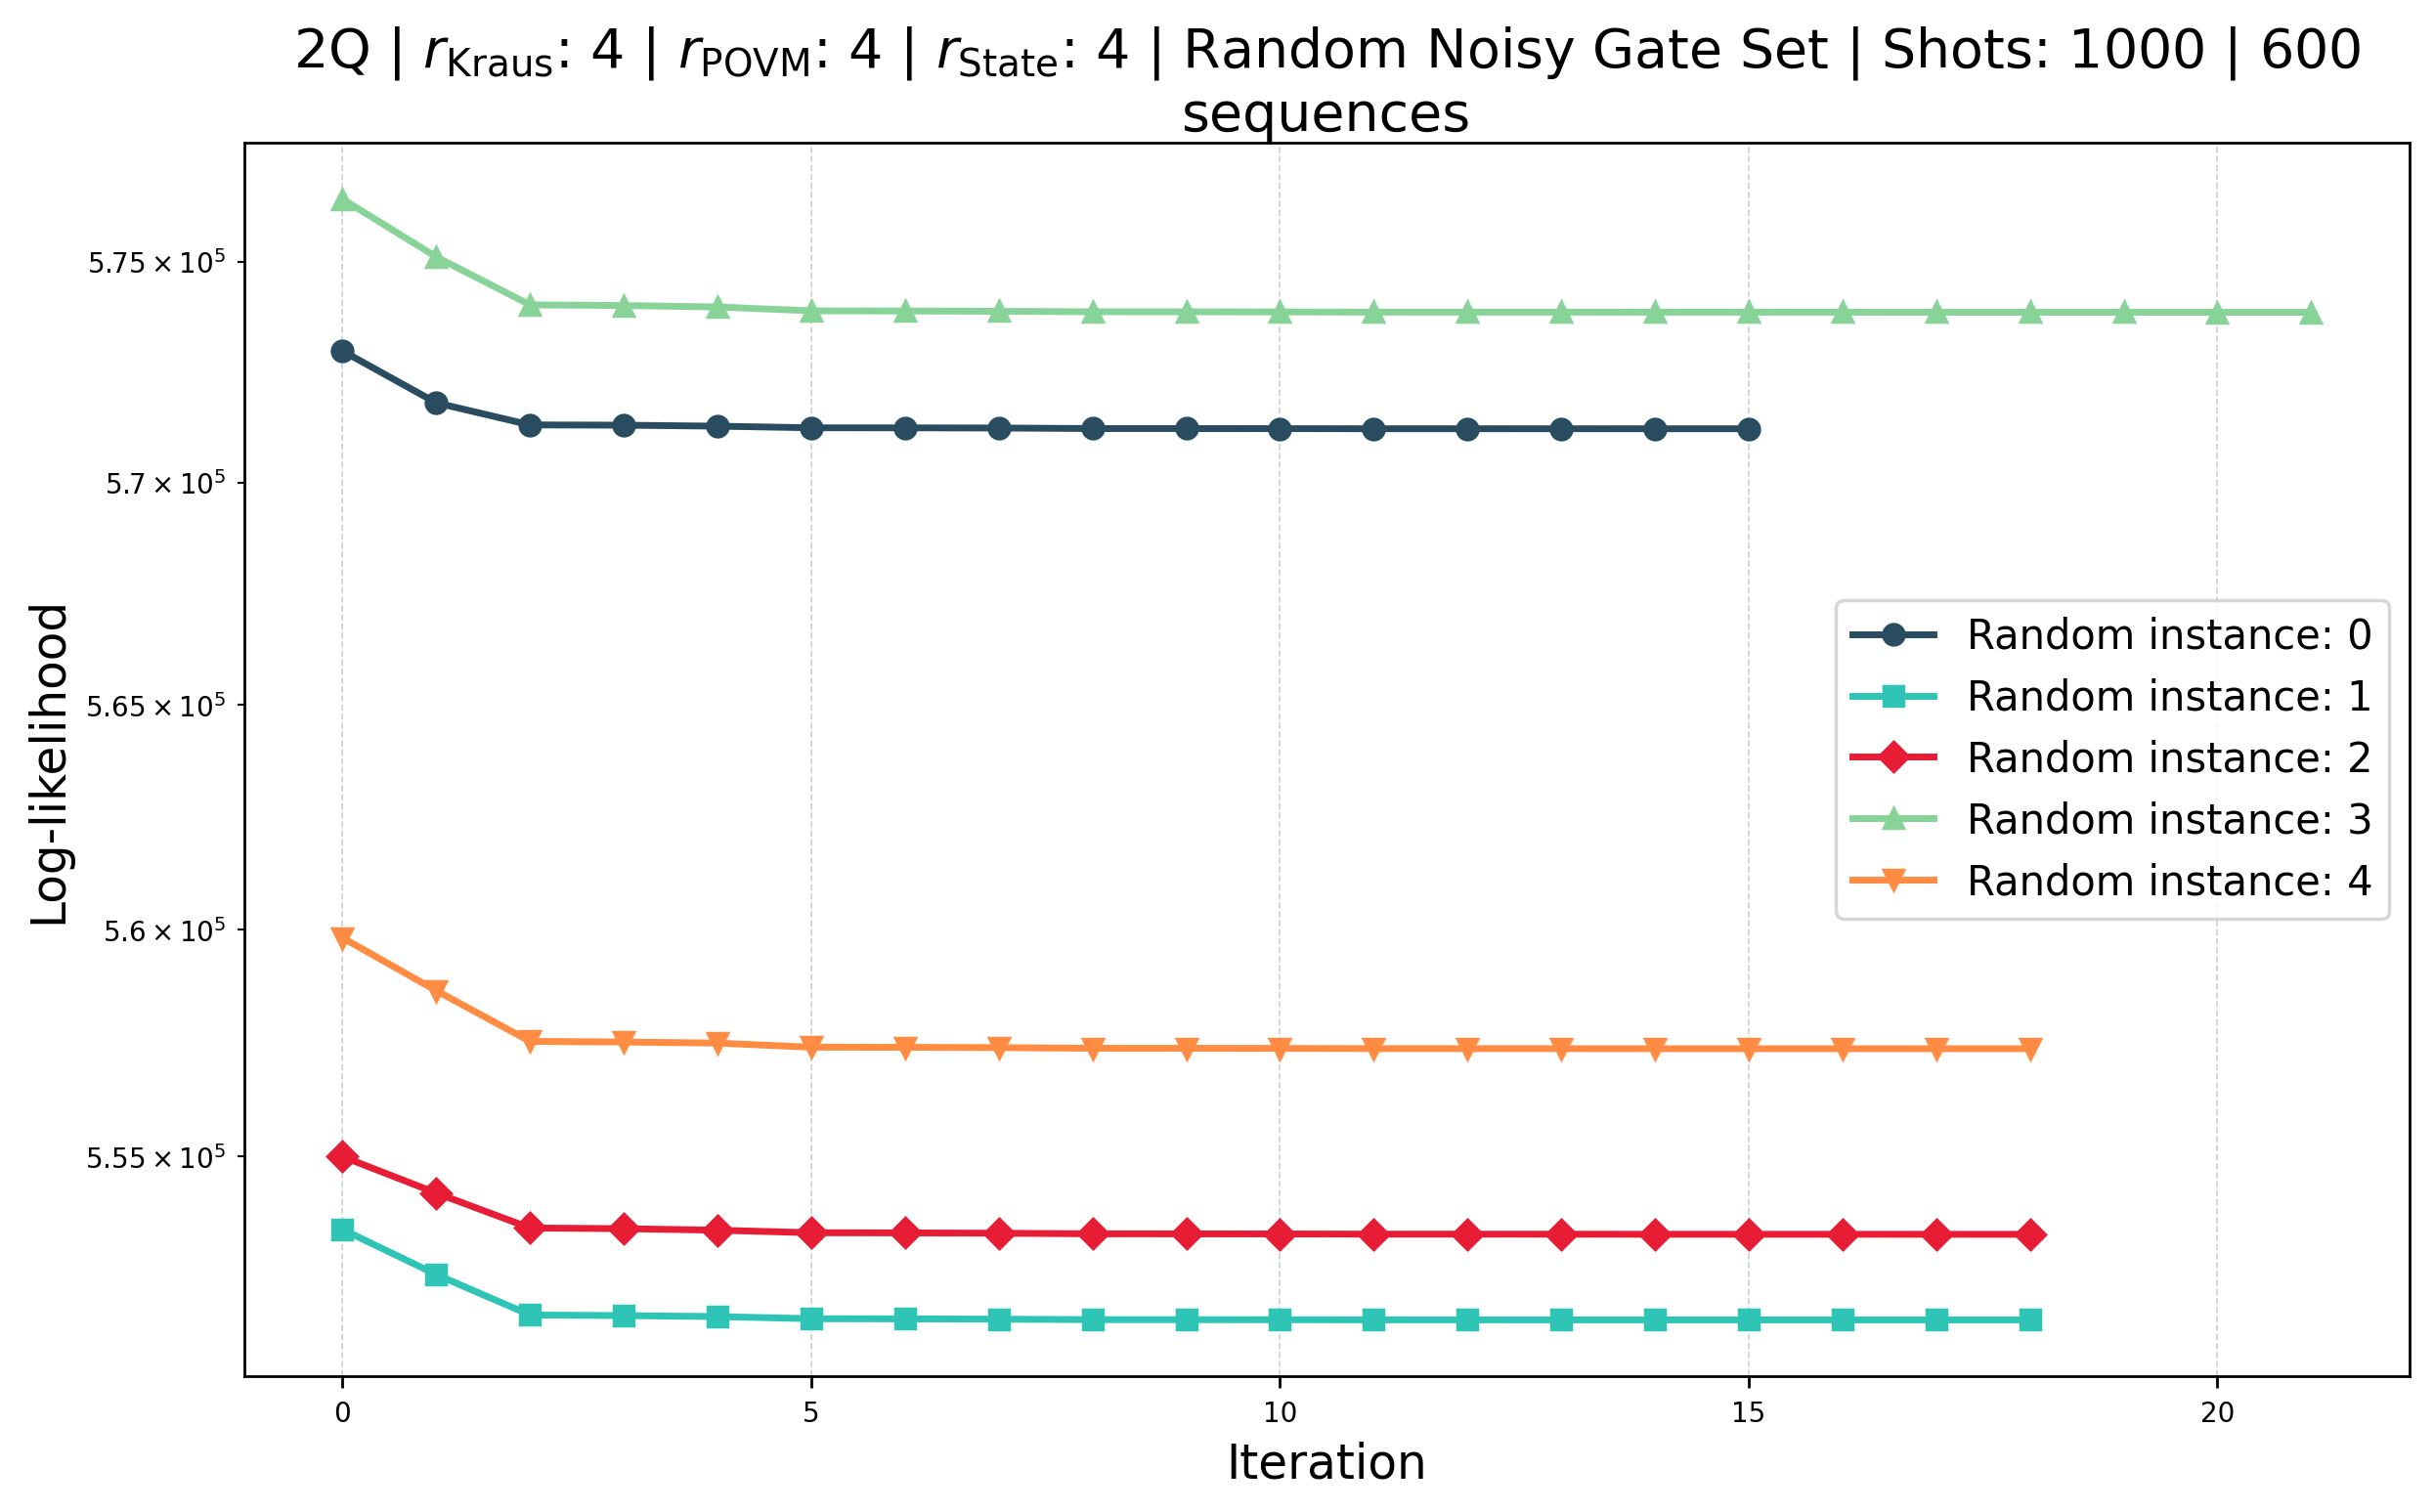

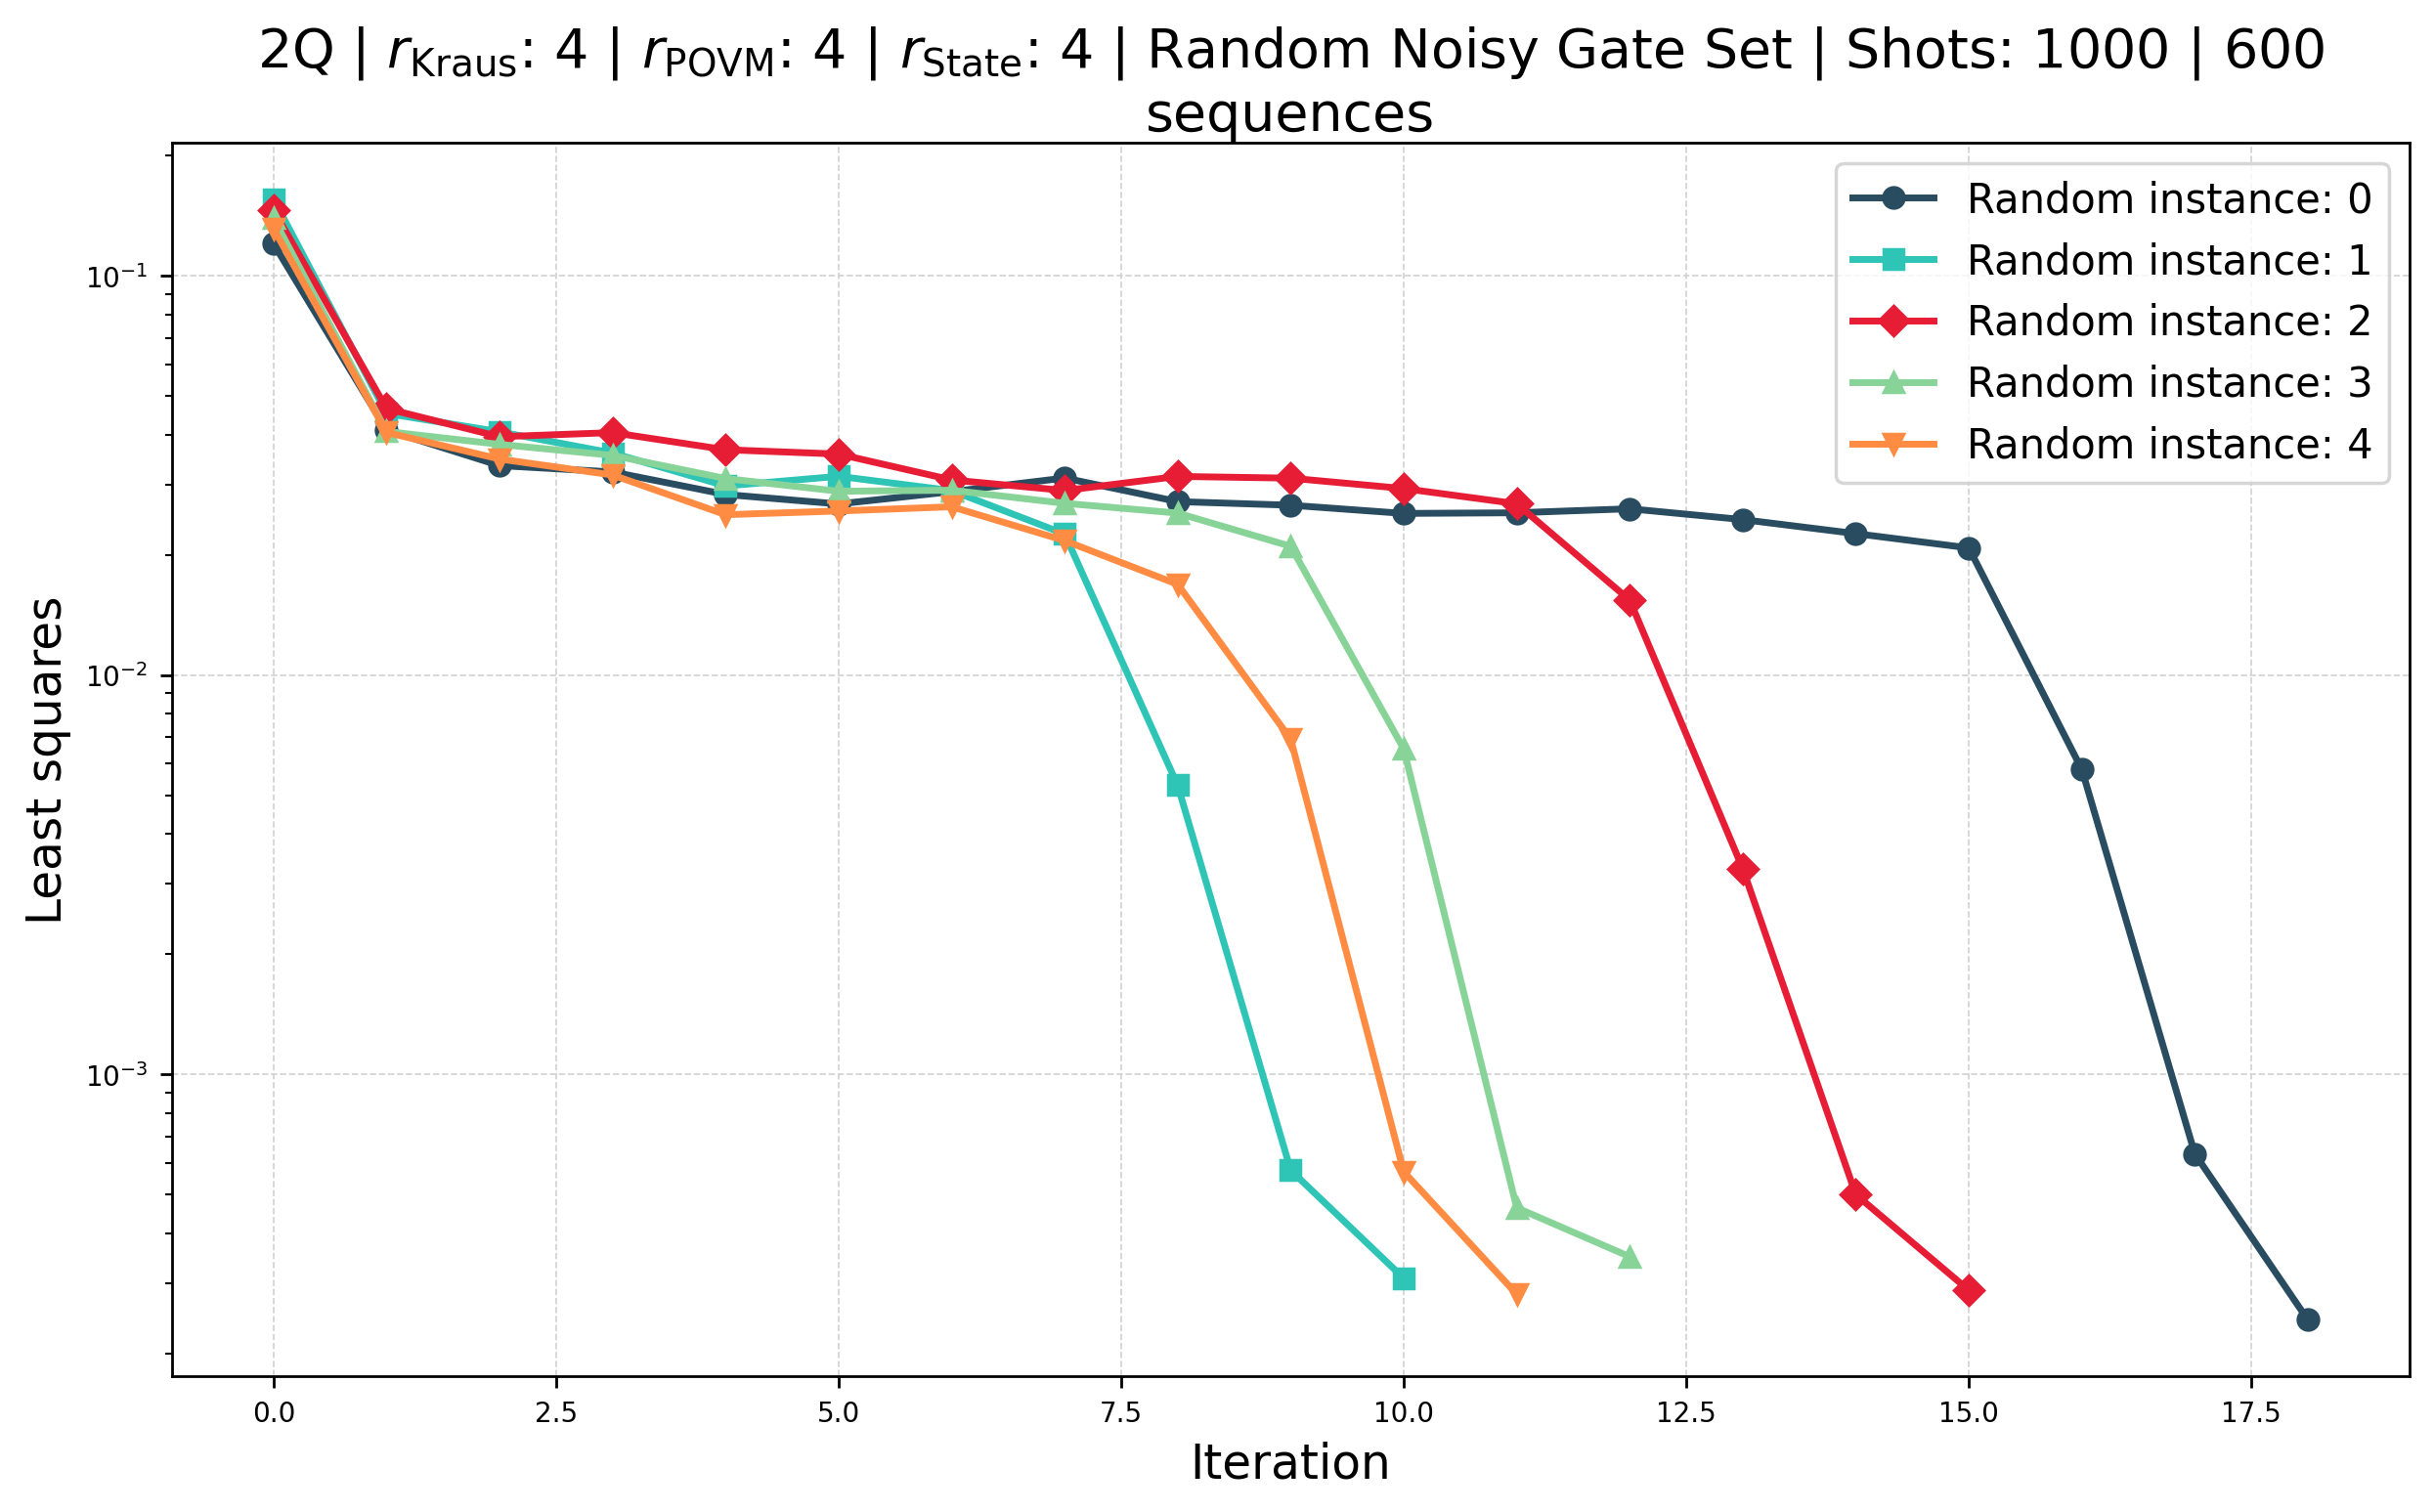

In [27]:
sequences_test = 600

final_results_test = get_all_realizations_for_key(final_results_600_650, str(sequences_test))

costs_test_final = [res["cost_fn_history"]["main"] for res in final_results_test]
labels_random_inits = [f"Random instance: {i}" for i in range(len(final_results_test))]

title = title_init + f" | {sequences_test} sequences"

plot_cost_function(costs_test_final[:], title=title, labels=labels_random_inits[:], ylabel="Log-likelihood")

partial_results_test = get_all_realizations_for_key(partial_results_600_650, str(sequences_test))

costs_test_partial = [res["cost_fn_history"]["main"] for res in partial_results_test]

plot_cost_function(costs_test_partial[:], title=title, labels=labels_random_inits[:], ylabel="Least squares")

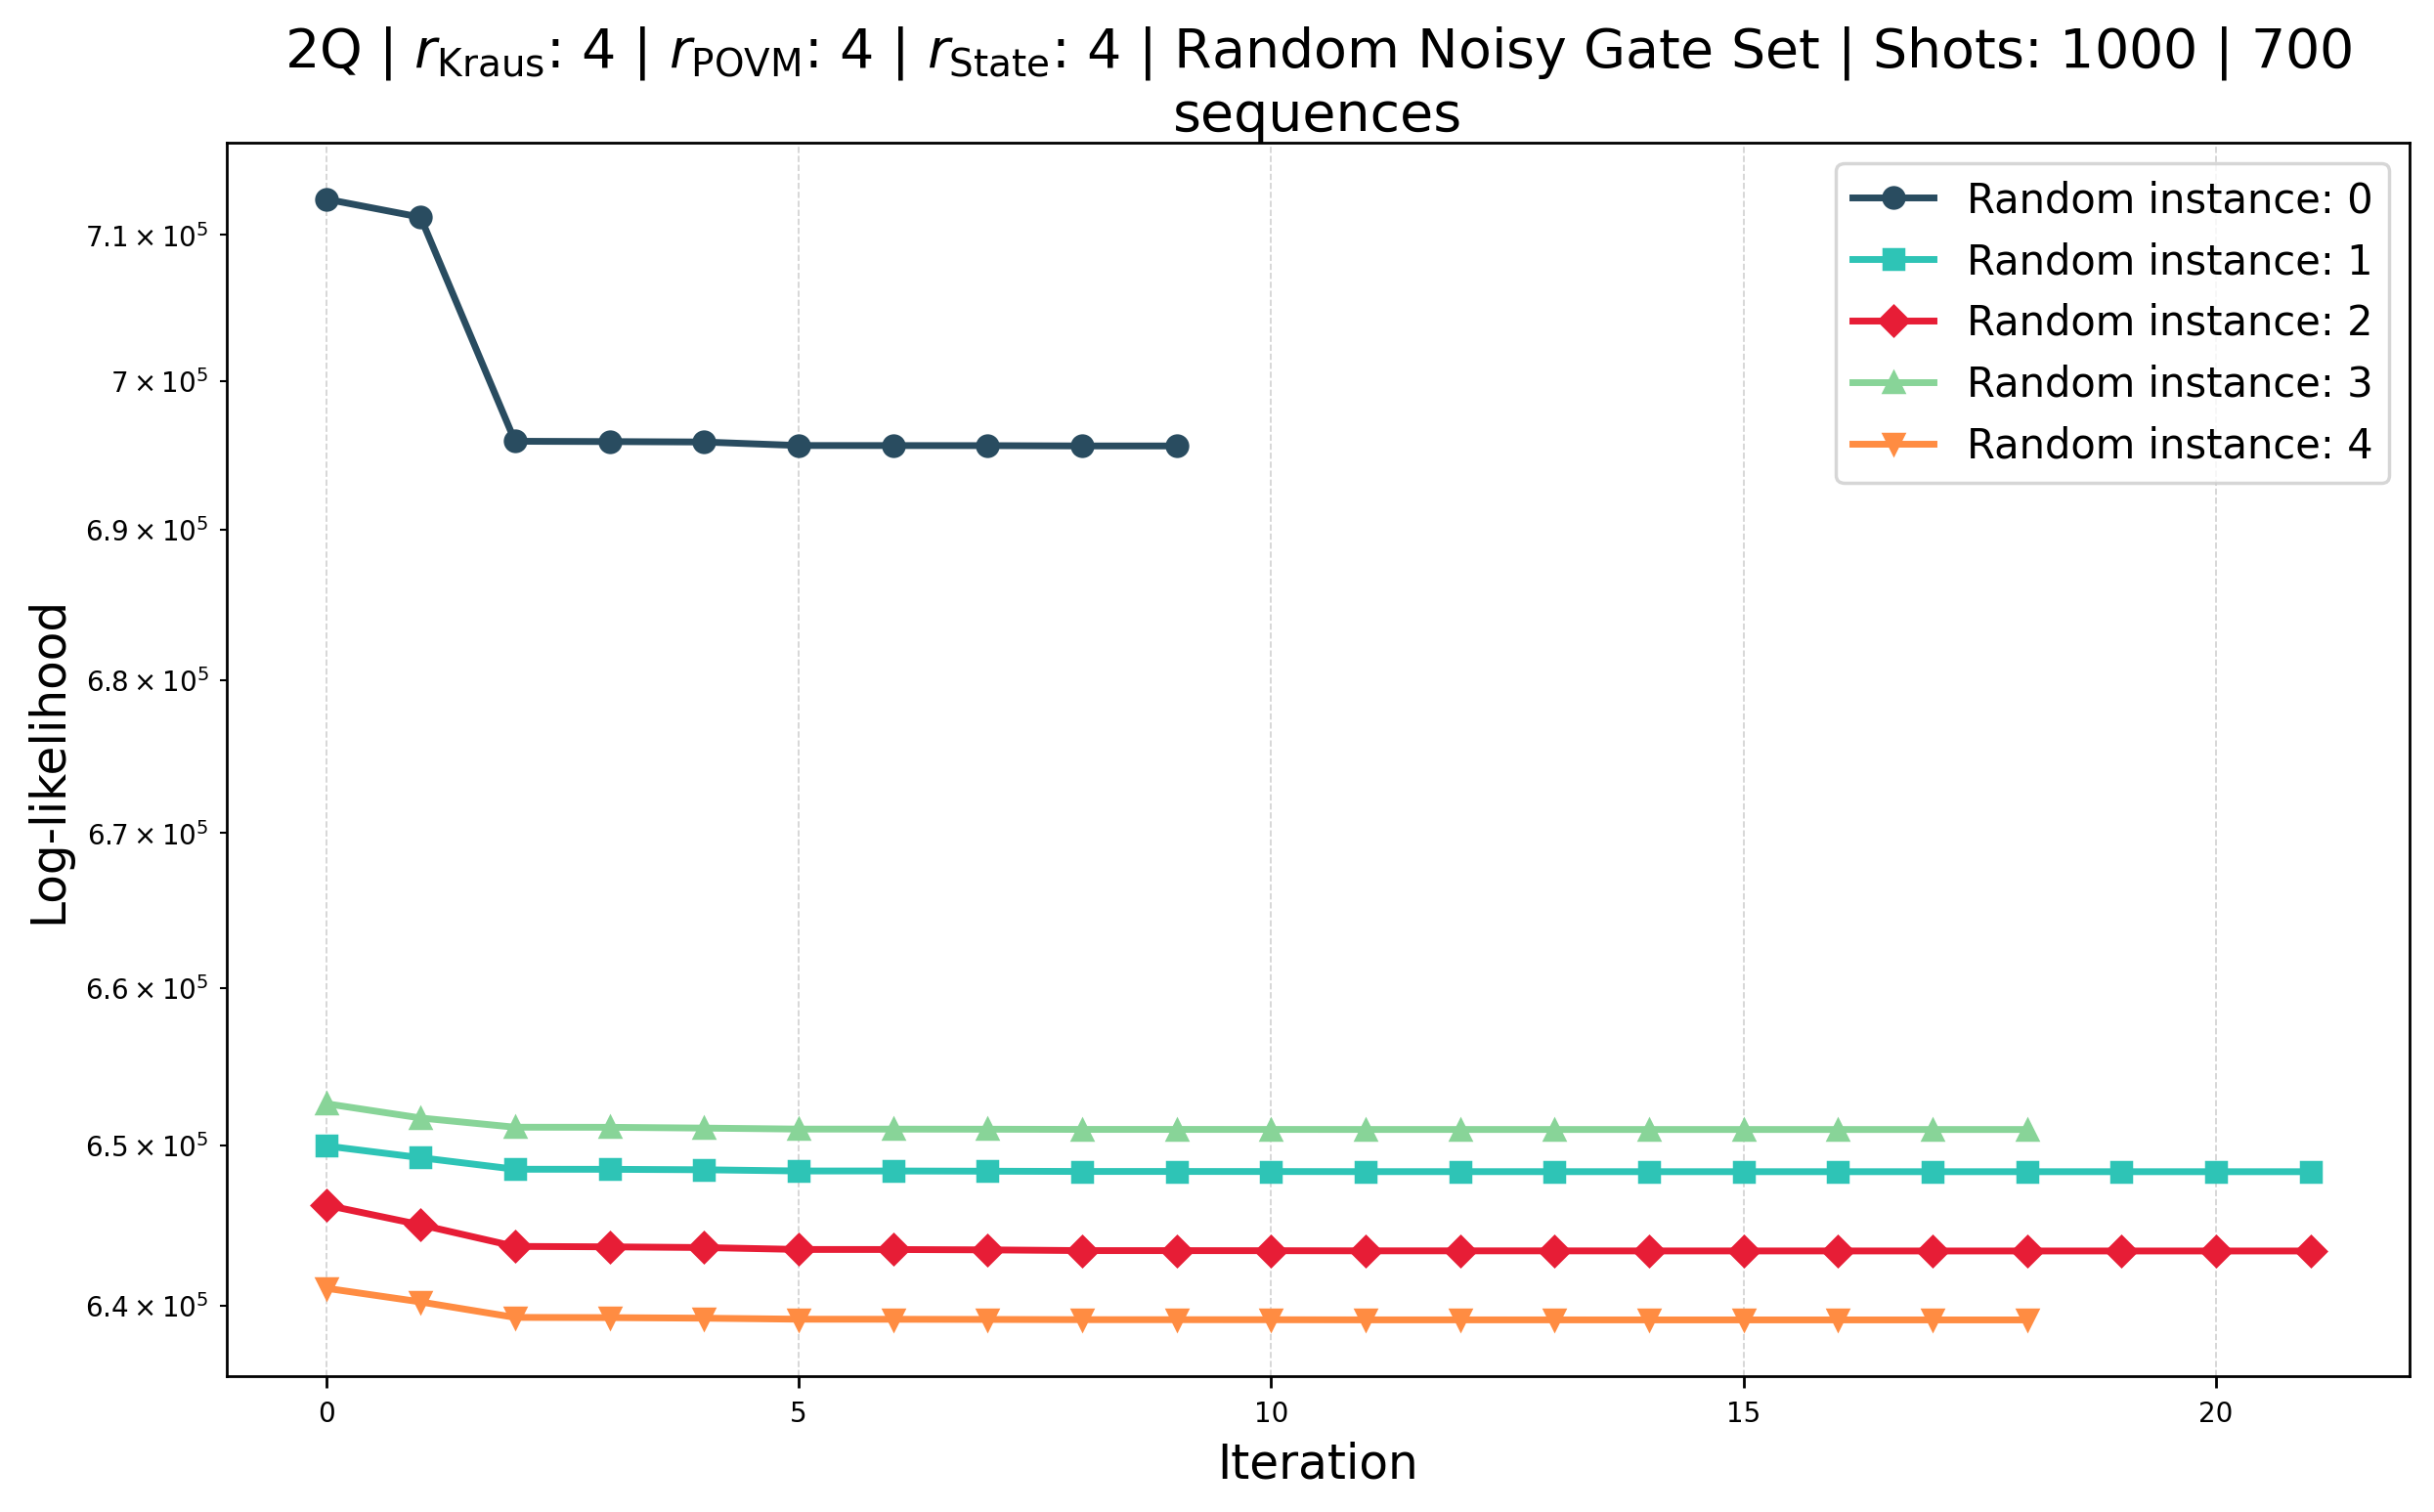

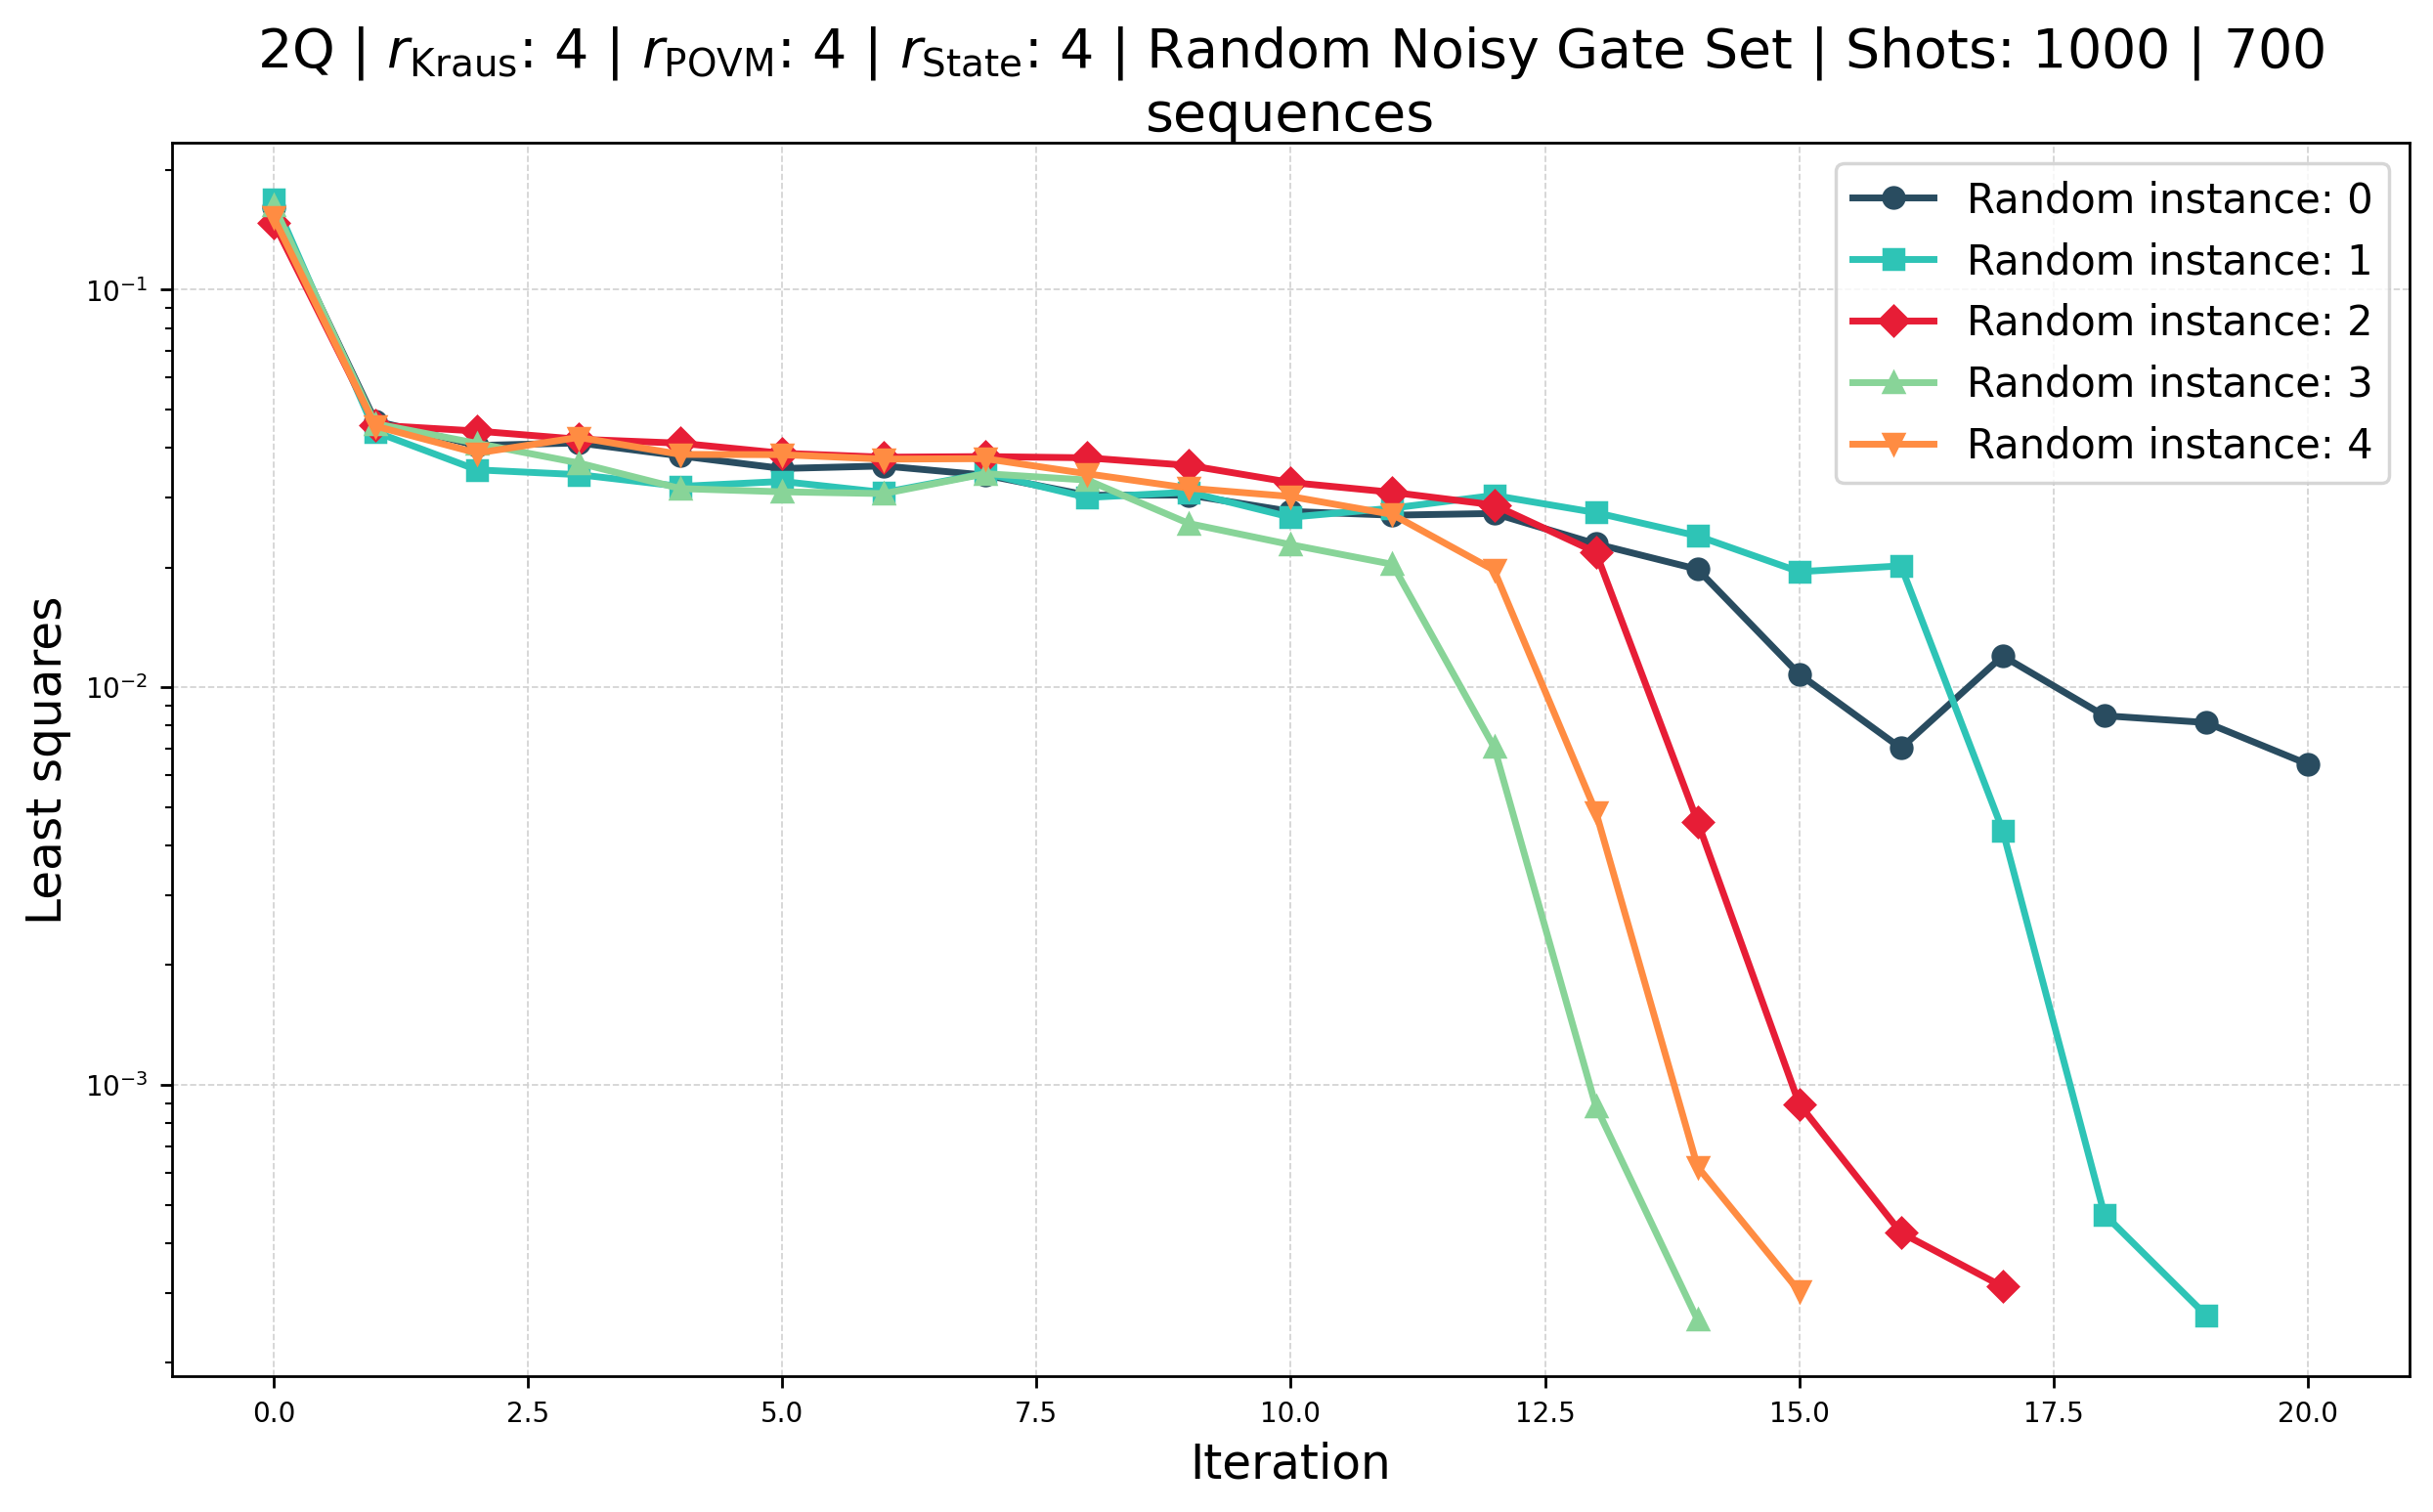

In [19]:
sequences_test = 700

final_results_test = get_all_realizations_for_key(final_results_700, str(sequences_test))

costs_test_final = [res["cost_fn_history"]["main"] for res in final_results_test]
labels_random_inits = [f"Random instance: {i}" for i in range(len(final_results_test))]

title = title_init + f" | {sequences_test} sequences"

plot_cost_function(costs_test_final[:], title=title, labels=labels_random_inits[:], ylabel="Log-likelihood")

partial_results_test = get_all_realizations_for_key(partial_results_700, str(sequences_test))

costs_test_partial = [res["cost_fn_history"]["main"] for res in partial_results_test]

plot_cost_function(costs_test_partial[:], title=title, labels=labels_random_inits[:], ylabel="Least squares")

# MVE

In [10]:
mve_results_100_150, wve_results_100_150 = compute_mve_and_wve_for_all_realizations(
    optimization_results=final_results_100_150,
    true_superops=noisy_gate_set_superop,
    sequence_length=mve_seq_length,
    num_circuits_sampled=num_circuits_sampled,
    num_repetitions=num_random_runs,
    which_data="optimized_operators",
)
mve_results_100_150

[{'100': {'mean': Array(0.26798761, dtype=float64),
   'std': Array(0.00507561, dtype=float64)},
  '150': {'mean': Array(0.02848849, dtype=float64),
   'std': Array(0.00035866, dtype=float64)}},
 {'100': {'mean': Array(0.28832016, dtype=float64),
   'std': Array(0.0032029, dtype=float64)},
  '150': {'mean': Array(0.25006497, dtype=float64),
   'std': Array(0.00466202, dtype=float64)}},
 {'100': {'mean': Array(0.28180119, dtype=float64),
   'std': Array(0.00396764, dtype=float64)},
  '150': {'mean': Array(0.27247886, dtype=float64),
   'std': Array(0.00460493, dtype=float64)}},
 {'100': {'mean': Array(0.26550822, dtype=float64),
   'std': Array(0.00308386, dtype=float64)},
  '150': {'mean': Array(0.02339435, dtype=float64),
   'std': Array(0.0003026, dtype=float64)}},
 {'100': {'mean': Array(0.28352166, dtype=float64),
   'std': Array(0.00561397, dtype=float64)},
  '150': {'mean': Array(0.03002179, dtype=float64),
   'std': Array(0.00027039, dtype=float64)}}]

In [34]:
mve_results_125_175, wve_results_125_175 = compute_mve_and_wve_for_all_realizations(
    optimization_results=final_results_125_175,
    true_superops=noisy_gate_set_superop,
    sequence_length=mve_seq_length,
    num_circuits_sampled=num_circuits_sampled,
    num_repetitions=num_random_runs,
    which_data="optimized_operators",
)
mve_results_125_175

[{'125': {'mean': Array(0.26496661, dtype=float64),
   'std': Array(0.00336791, dtype=float64)},
  '175': {'mean': Array(0.02609914, dtype=float64),
   'std': Array(0.00038678, dtype=float64)}},
 {'125': {'mean': Array(0.24259487, dtype=float64),
   'std': Array(0.00426605, dtype=float64)},
  '175': {'mean': Array(0.25670389, dtype=float64),
   'std': Array(0.00300354, dtype=float64)}},
 {'125': {'mean': Array(0.27878496, dtype=float64),
   'std': Array(0.0038222, dtype=float64)},
  '175': {'mean': Array(0.02444529, dtype=float64),
   'std': Array(0.00031719, dtype=float64)}},
 {'125': {'mean': Array(0.21057902, dtype=float64),
   'std': Array(0.00398081, dtype=float64)},
  '175': {'mean': Array(0.13321344, dtype=float64),
   'std': Array(0.00385008, dtype=float64)}},
 {'125': {'mean': Array(0.27274179, dtype=float64),
   'std': Array(0.00506256, dtype=float64)},
  '175': {'mean': Array(0.13541517, dtype=float64),
   'std': Array(0.00325848, dtype=float64)}}]

In [12]:
mve_results_200_250, wve_results_200_250 = compute_mve_and_wve_for_all_realizations(
    optimization_results=final_results_200_250,
    true_superops=noisy_gate_set_superop,
    sequence_length=mve_seq_length,
    num_circuits_sampled=num_circuits_sampled,
    num_repetitions=num_random_runs,
    which_data="optimized_operators",
)
mve_results_200_250

[{'200': {'mean': Array(0.02262186, dtype=float64),
   'std': Array(0.00022598, dtype=float64)},
  '250': {'mean': Array(0.12942825, dtype=float64),
   'std': Array(0.00276705, dtype=float64)}},
 {'200': {'mean': Array(0.02127041, dtype=float64),
   'std': Array(0.00025212, dtype=float64)},
  '250': {'mean': Array(0.01756235, dtype=float64),
   'std': Array(0.00019517, dtype=float64)}},
 {'200': {'mean': Array(0.02056281, dtype=float64),
   'std': Array(0.00042233, dtype=float64)},
  '250': {'mean': Array(0.01926804, dtype=float64),
   'std': Array(0.000317, dtype=float64)}},
 {'200': {'mean': Array(0.02372869, dtype=float64),
   'std': Array(0.0002488, dtype=float64)},
  '250': {'mean': Array(0.01845793, dtype=float64),
   'std': Array(0.00012838, dtype=float64)}},
 {'200': {'mean': Array(0.02085786, dtype=float64),
   'std': Array(0.00023021, dtype=float64)},
  '250': {'mean': Array(0.0184848, dtype=float64),
   'std': Array(0.00034158, dtype=float64)}}]

In [35]:
mve_results_210_250, wve_results_210_250 = compute_mve_and_wve_for_all_realizations(
    optimization_results=final_results_210_250,
    true_superops=noisy_gate_set_superop,
    sequence_length=mve_seq_length,
    num_circuits_sampled=num_circuits_sampled,
    num_repetitions=num_random_runs,
    which_data="optimized_operators",
)
mve_results_210_250

[{'210': {'mean': Array(0.02096012, dtype=float64),
   'std': Array(0.00026722, dtype=float64)},
  '250': {'mean': Array(0.01805012, dtype=float64),
   'std': Array(0.00014662, dtype=float64)}},
 {'210': {'mean': Array(0.02104398, dtype=float64),
   'std': Array(0.00024332, dtype=float64)},
  '250': {'mean': Array(0.01889887, dtype=float64),
   'std': Array(0.00018677, dtype=float64)}},
 {'210': {'mean': Array(0.02047983, dtype=float64),
   'std': Array(0.00023918, dtype=float64)},
  '250': {'mean': Array(0.01917535, dtype=float64),
   'std': Array(0.00018818, dtype=float64)}},
 {'210': {'mean': Array(0.02204899, dtype=float64),
   'std': Array(0.00028433, dtype=float64)},
  '250': {'mean': Array(0.01950065, dtype=float64),
   'std': Array(0.00022135, dtype=float64)}},
 {'210': {'mean': Array(0.13350882, dtype=float64),
   'std': Array(0.00171184, dtype=float64)},
  '250': {'mean': Array(0.11798569, dtype=float64),
   'std': Array(0.00205822, dtype=float64)}}]

In [18]:
mve_results_300_350, wve_results_300_350 = compute_mve_and_wve_for_all_realizations(
    optimization_results=final_results_300_350,
    true_superops=noisy_gate_set_superop,
    sequence_length=mve_seq_length,
    num_circuits_sampled=num_circuits_sampled,
    num_repetitions=num_random_runs,
    which_data="optimized_operators",
)
mve_results_300_350

[{'300': {'mean': Array(0.01669829, dtype=float64),
   'std': Array(0.00024377, dtype=float64)},
  '350': {'mean': Array(0.01656504, dtype=float64),
   'std': Array(0.00016061, dtype=float64)}},
 {'300': {'mean': Array(0.01782827, dtype=float64),
   'std': Array(0.00024508, dtype=float64)},
  '350': {'mean': Array(0.01535567, dtype=float64),
   'std': Array(0.00011302, dtype=float64)}},
 {'300': {'mean': Array(0.01662879, dtype=float64),
   'std': Array(0.00023883, dtype=float64)},
  '350': {'mean': Array(0.01523241, dtype=float64),
   'std': Array(0.00017316, dtype=float64)}},
 {'300': {'mean': Array(0.01749875, dtype=float64),
   'std': Array(0.00011863, dtype=float64)},
  '350': {'mean': Array(0.0160805, dtype=float64),
   'std': Array(0.00025581, dtype=float64)}},
 {'300': {'mean': Array(0.01724051, dtype=float64),
   'std': Array(0.00015693, dtype=float64)},
  '350': {'mean': Array(0.01566236, dtype=float64),
   'std': Array(0.00019173, dtype=float64)}}]

In [19]:
mve_results_400_450, wve_results_400_450 = compute_mve_and_wve_for_all_realizations(
    optimization_results=final_results_400_450,
    true_superops=noisy_gate_set_superop,
    sequence_length=mve_seq_length,
    num_circuits_sampled=num_circuits_sampled,
    num_repetitions=num_random_runs,
    which_data="optimized_operators",
)
mve_results_400_450

[{'400': {'mean': Array(0.01466063, dtype=float64),
   'std': Array(0.00013033, dtype=float64)},
  '450': {'mean': Array(0.01385136, dtype=float64),
   'std': Array(0.00020902, dtype=float64)}},
 {'400': {'mean': Array(0.01501002, dtype=float64),
   'std': Array(0.00022963, dtype=float64)},
  '450': {'mean': Array(0.01374723, dtype=float64),
   'std': Array(0.00024128, dtype=float64)}},
 {'400': {'mean': Array(0.01538406, dtype=float64),
   'std': Array(0.00023279, dtype=float64)},
  '450': {'mean': Array(0.01299042, dtype=float64),
   'std': Array(0.00023822, dtype=float64)}},
 {'400': {'mean': Array(0.01355514, dtype=float64),
   'std': Array(0.00018883, dtype=float64)},
  '450': {'mean': Array(0.01338573, dtype=float64),
   'std': Array(0.000188, dtype=float64)}},
 {'400': {'mean': Array(0.0141447, dtype=float64),
   'std': Array(0.00017096, dtype=float64)},
  '450': {'mean': Array(0.0133495, dtype=float64),
   'std': Array(0.00017213, dtype=float64)}}]

In [26]:
mve_results_500_550, wve_results_500_550 = compute_mve_and_wve_for_all_realizations(
    optimization_results=final_results_500_550,
    true_superops=noisy_gate_set_superop,
    sequence_length=mve_seq_length,
    num_circuits_sampled=num_circuits_sampled,
    num_repetitions=num_random_runs,
    which_data="optimized_operators",
)
mve_results_500_550

[{'500': {'mean': Array(0.01256469, dtype=float64),
   'std': Array(0.00017581, dtype=float64)},
  '550': {'mean': Array(0.01240912, dtype=float64),
   'std': Array(0.00018861, dtype=float64)}},
 {'500': {'mean': Array(0.01215185, dtype=float64),
   'std': Array(0.00017437, dtype=float64)},
  '550': {'mean': Array(0.0125944, dtype=float64),
   'std': Array(0.00019607, dtype=float64)}},
 {'500': {'mean': Array(0.01374306, dtype=float64),
   'std': Array(0.00013091, dtype=float64)},
  '550': {'mean': Array(0.01168441, dtype=float64),
   'std': Array(0.00012234, dtype=float64)}},
 {'500': {'mean': Array(0.01214572, dtype=float64),
   'std': Array(0.00016122, dtype=float64)},
  '550': {'mean': Array(0.01226783, dtype=float64),
   'std': Array(0.00010983, dtype=float64)}},
 {'500': {'mean': Array(0.01340215, dtype=float64),
   'std': Array(0.00013968, dtype=float64)},
  '550': {'mean': Array(0.01276847, dtype=float64),
   'std': Array(0.00012358, dtype=float64)}}]

In [27]:
mve_results_600_650, wve_results_600_650 = compute_mve_and_wve_for_all_realizations(
    optimization_results=final_results_600_650,
    true_superops=noisy_gate_set_superop,
    sequence_length=mve_seq_length,
    num_circuits_sampled=num_circuits_sampled,
    num_repetitions=num_random_runs,
    which_data="optimized_operators",
)
mve_results_600_650

[{'600': {'mean': Array(0.01201587, dtype=float64),
   'std': Array(0.00012902, dtype=float64)},
  '650': {'mean': Array(0.01136475, dtype=float64),
   'std': Array(9.14406915e-05, dtype=float64)}},
 {'600': {'mean': Array(0.01210077, dtype=float64),
   'std': Array(0.00010128, dtype=float64)},
  '650': {'mean': Array(0.01172546, dtype=float64),
   'std': Array(0.00014596, dtype=float64)}},
 {'600': {'mean': Array(0.01279171, dtype=float64),
   'std': Array(0.00015485, dtype=float64)},
  '650': {'mean': Array(0.01130237, dtype=float64),
   'std': Array(0.00014526, dtype=float64)}},
 {'600': {'mean': Array(0.01240374, dtype=float64),
   'std': Array(0.00022653, dtype=float64)},
  '650': {'mean': Array(0.01123502, dtype=float64),
   'std': Array(0.00016145, dtype=float64)}},
 {'600': {'mean': Array(0.01168689, dtype=float64),
   'std': Array(0.00015005, dtype=float64)},
  '650': {'mean': Array(0.01122344, dtype=float64),
   'std': Array(0.00013678, dtype=float64)}}]

In [36]:
mve_results_700, wve_results_large_700 = compute_mve_and_wve_for_all_realizations(
    optimization_results=final_results_700,
    true_superops=noisy_gate_set_superop,
    sequence_length=mve_seq_length,
    num_circuits_sampled=num_circuits_sampled,
    num_repetitions=num_random_runs,
    which_data="optimized_operators",
)
mve_results_700

[{'700': {'mean': Array(0.01003288, dtype=float64),
   'std': Array(0.00016559, dtype=float64)}},
 {'700': {'mean': Array(0.0117541, dtype=float64),
   'std': Array(0.00012011, dtype=float64)}},
 {'700': {'mean': Array(0.01096518, dtype=float64),
   'std': Array(0.00011155, dtype=float64)}},
 {'700': {'mean': Array(0.01103892, dtype=float64),
   'std': Array(0.00012371, dtype=float64)}},
 {'700': {'mean': Array(0.0106808, dtype=float64),
   'std': Array(0.0001034, dtype=float64)}}]

In [37]:
mve_results_200_250

[{'200': {'mean': Array(0.02262186, dtype=float64),
   'std': Array(0.00022598, dtype=float64)},
  '250': {'mean': Array(0.12942825, dtype=float64),
   'std': Array(0.00276705, dtype=float64)}},
 {'200': {'mean': Array(0.02127041, dtype=float64),
   'std': Array(0.00025212, dtype=float64)},
  '250': {'mean': Array(0.01756235, dtype=float64),
   'std': Array(0.00019517, dtype=float64)}},
 {'200': {'mean': Array(0.02056281, dtype=float64),
   'std': Array(0.00042233, dtype=float64)},
  '250': {'mean': Array(0.01926804, dtype=float64),
   'std': Array(0.000317, dtype=float64)}},
 {'200': {'mean': Array(0.02372869, dtype=float64),
   'std': Array(0.0002488, dtype=float64)},
  '250': {'mean': Array(0.01845793, dtype=float64),
   'std': Array(0.00012838, dtype=float64)}},
 {'200': {'mean': Array(0.02085786, dtype=float64),
   'std': Array(0.00023021, dtype=float64)},
  '250': {'mean': Array(0.0184848, dtype=float64),
   'std': Array(0.00034158, dtype=float64)}}]

In [44]:
mve_results_200 = [{str(200):realization} for realization in get_all_realizations_for_key(mve_results_200_250, str(200))]

wve_results_200 = [{str(200):realization} for realization in get_all_realizations_for_key(wve_results_200_250, str(200))]

In [41]:
mve_combined = combine_error_results(mve_results_100_150, mve_results_125_175, mve_results_200, mve_results_210_250, mve_results_300_350, mve_results_400_450, mve_results_500_550, mve_results_600_650, mve_results_700)
mean_mve_results_combined = compute_avg_and_std_along_keys(list_of_errors=mve_combined)
mean_mve_results_combined

{'100': {'mean': Array(0.27742777, dtype=float64),
  'std': Array(0.0090122, dtype=float64)},
 '125': {'mean': Array(0.25393345, dtype=float64),
  'std': Array(0.02490483, dtype=float64)},
 '150': {'mean': Array(0.12088969, dtype=float64),
  'std': Array(0.1148615, dtype=float64)},
 '175': {'mean': Array(0.11517539, dtype=float64),
  'std': Array(0.08594401, dtype=float64)},
 '200': {'mean': Array(0.02180833, dtype=float64),
  'std': Array(0.00119111, dtype=float64)},
 '210': {'mean': Array(0.04360835, dtype=float64),
  'std': Array(0.04495314, dtype=float64)},
 '250': {'mean': Array(0.03872214, dtype=float64),
  'std': Array(0.0396347, dtype=float64)},
 '300': {'mean': Array(0.01717892, dtype=float64),
  'std': Array(0.00046074, dtype=float64)},
 '350': {'mean': Array(0.0157792, dtype=float64),
  'std': Array(0.00048997, dtype=float64)},
 '400': {'mean': Array(0.01455091, dtype=float64),
  'std': Array(0.00064398, dtype=float64)},
 '450': {'mean': Array(0.01346485, dtype=float64),
  '

In [45]:
wve_combined = combine_error_results(wve_results_100_150, wve_results_125_175, wve_results_200, wve_results_210_250, wve_results_300_350, wve_results_400_450, wve_results_500_550, wve_results_600_650, wve_results_large_700)
mean_wve_results_combined = compute_avg_and_std_along_keys(list_of_errors=wve_combined)
mean_wve_results_combined

{'100': {'mean': Array(0.71182394, dtype=float64),
  'std': Array(0.01036802, dtype=float64)},
 '125': {'mean': Array(0.67932542, dtype=float64),
  'std': Array(0.02597486, dtype=float64)},
 '150': {'mean': Array(0.32039455, dtype=float64),
  'std': Array(0.2904662, dtype=float64)},
 '175': {'mean': Array(0.43908279, dtype=float64),
  'std': Array(0.2951459, dtype=float64)},
 '200': {'mean': Array(0.06476169, dtype=float64),
  'std': Array(0.00304633, dtype=float64)},
 '210': {'mean': Array(0.18823211, dtype=float64),
  'std': Array(0.25022191, dtype=float64)},
 '250': {'mean': Array(0.1804864, dtype=float64),
  'std': Array(0.24611485, dtype=float64)},
 '300': {'mean': Array(0.05073866, dtype=float64),
  'std': Array(0.00179704, dtype=float64)},
 '350': {'mean': Array(0.04872963, dtype=float64),
  'std': Array(0.00199335, dtype=float64)},
 '400': {'mean': Array(0.04310673, dtype=float64),
  'std': Array(0.00346002, dtype=float64)},
 '450': {'mean': Array(0.04090446, dtype=float64),
  

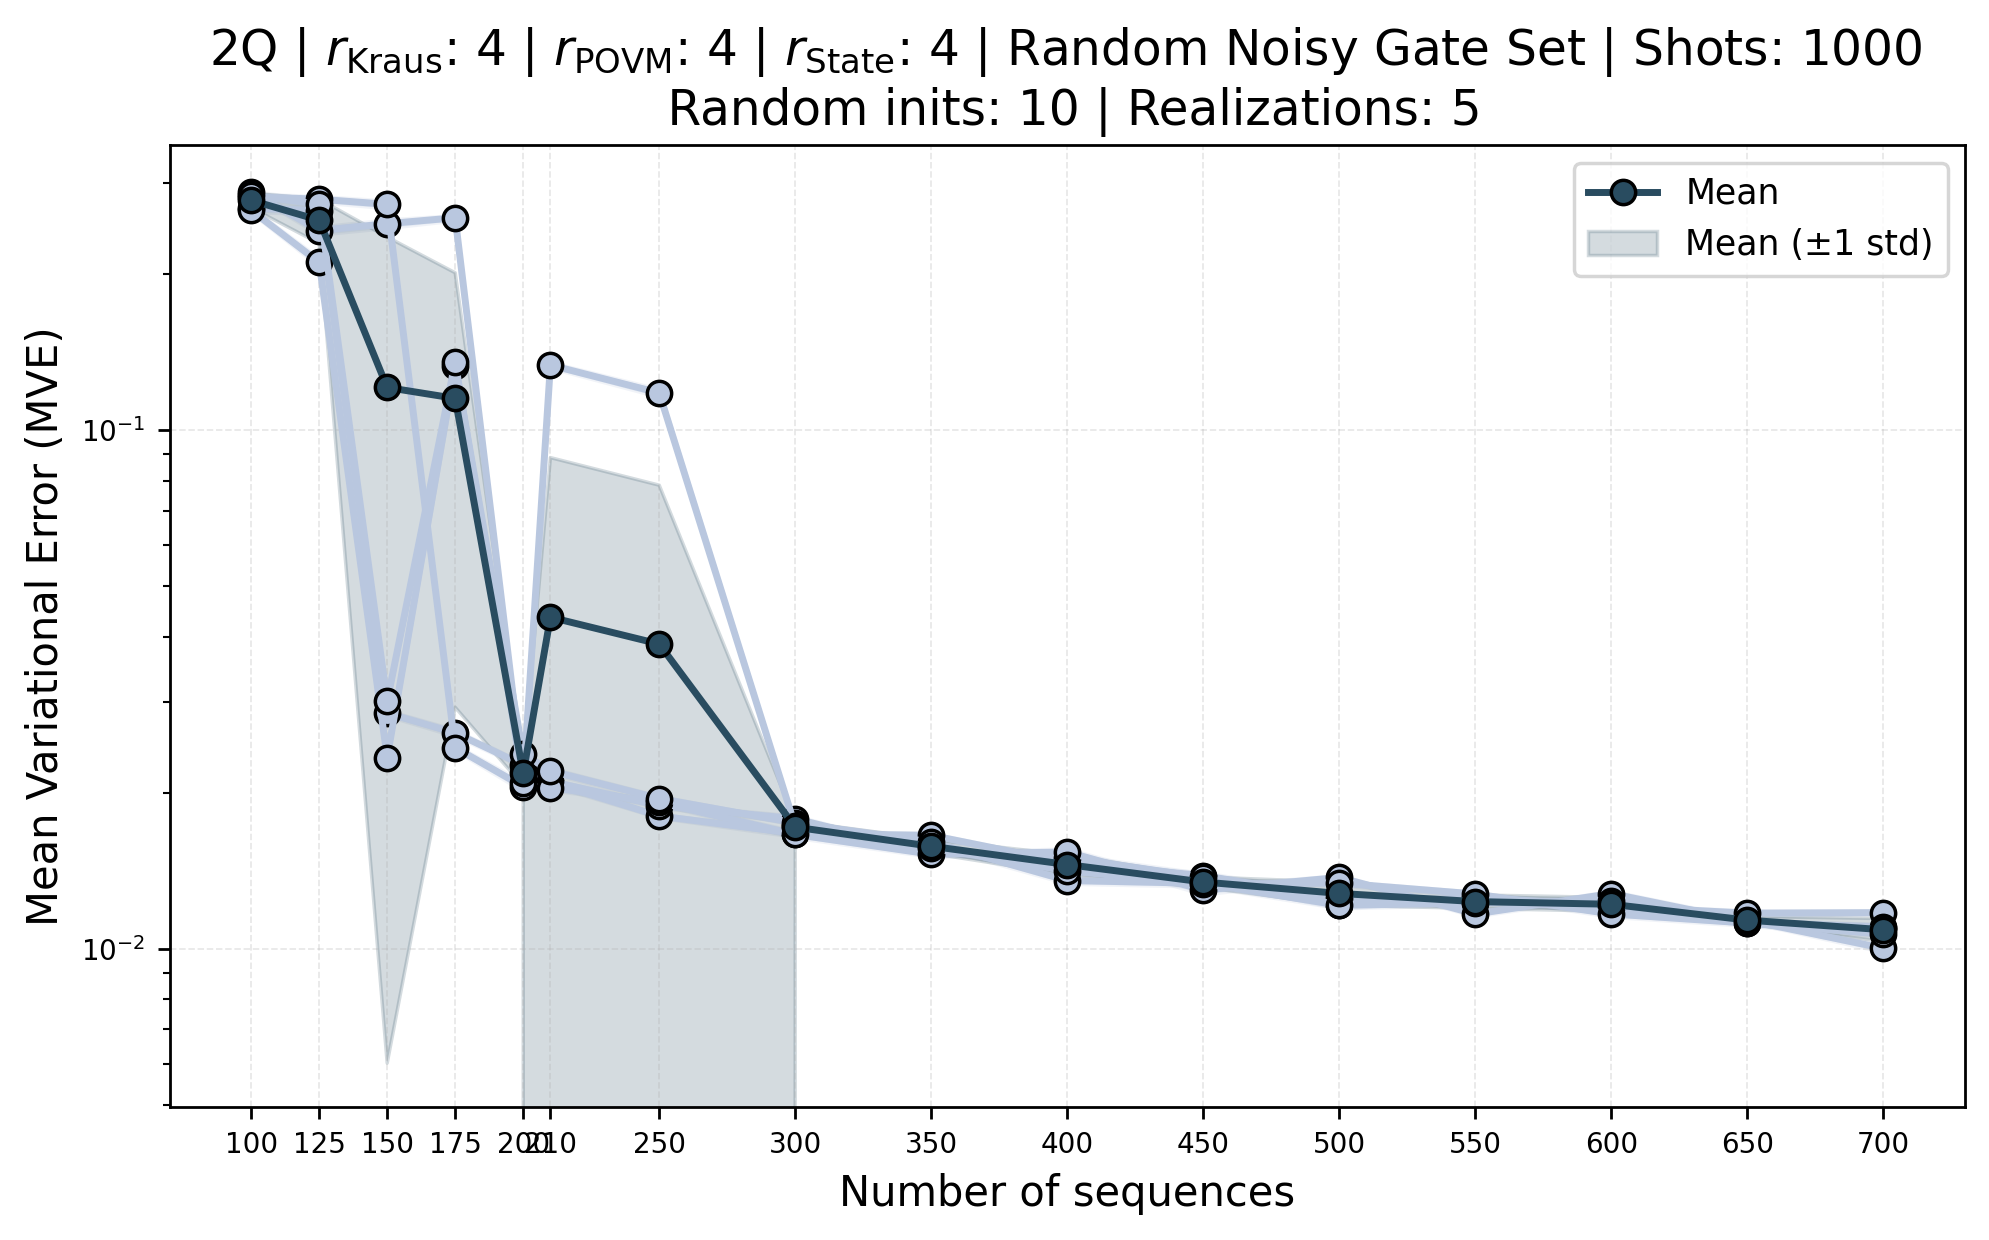

In [ ]:
fig_all_mve = plot_many_mean_std_vs_x(
    data=mve_combined,
    title=title_mve,
    ylabel=f"Mean Variational Error (MVE)",
    use_log_scale="y",
    main_curve=mean_mve_results_combined,
    main_curve_label="Mean",
    # main_curve=result_1000_seq_dict,
    # main_curve_label="1000 Sequences (target init)",
    show=False,
)

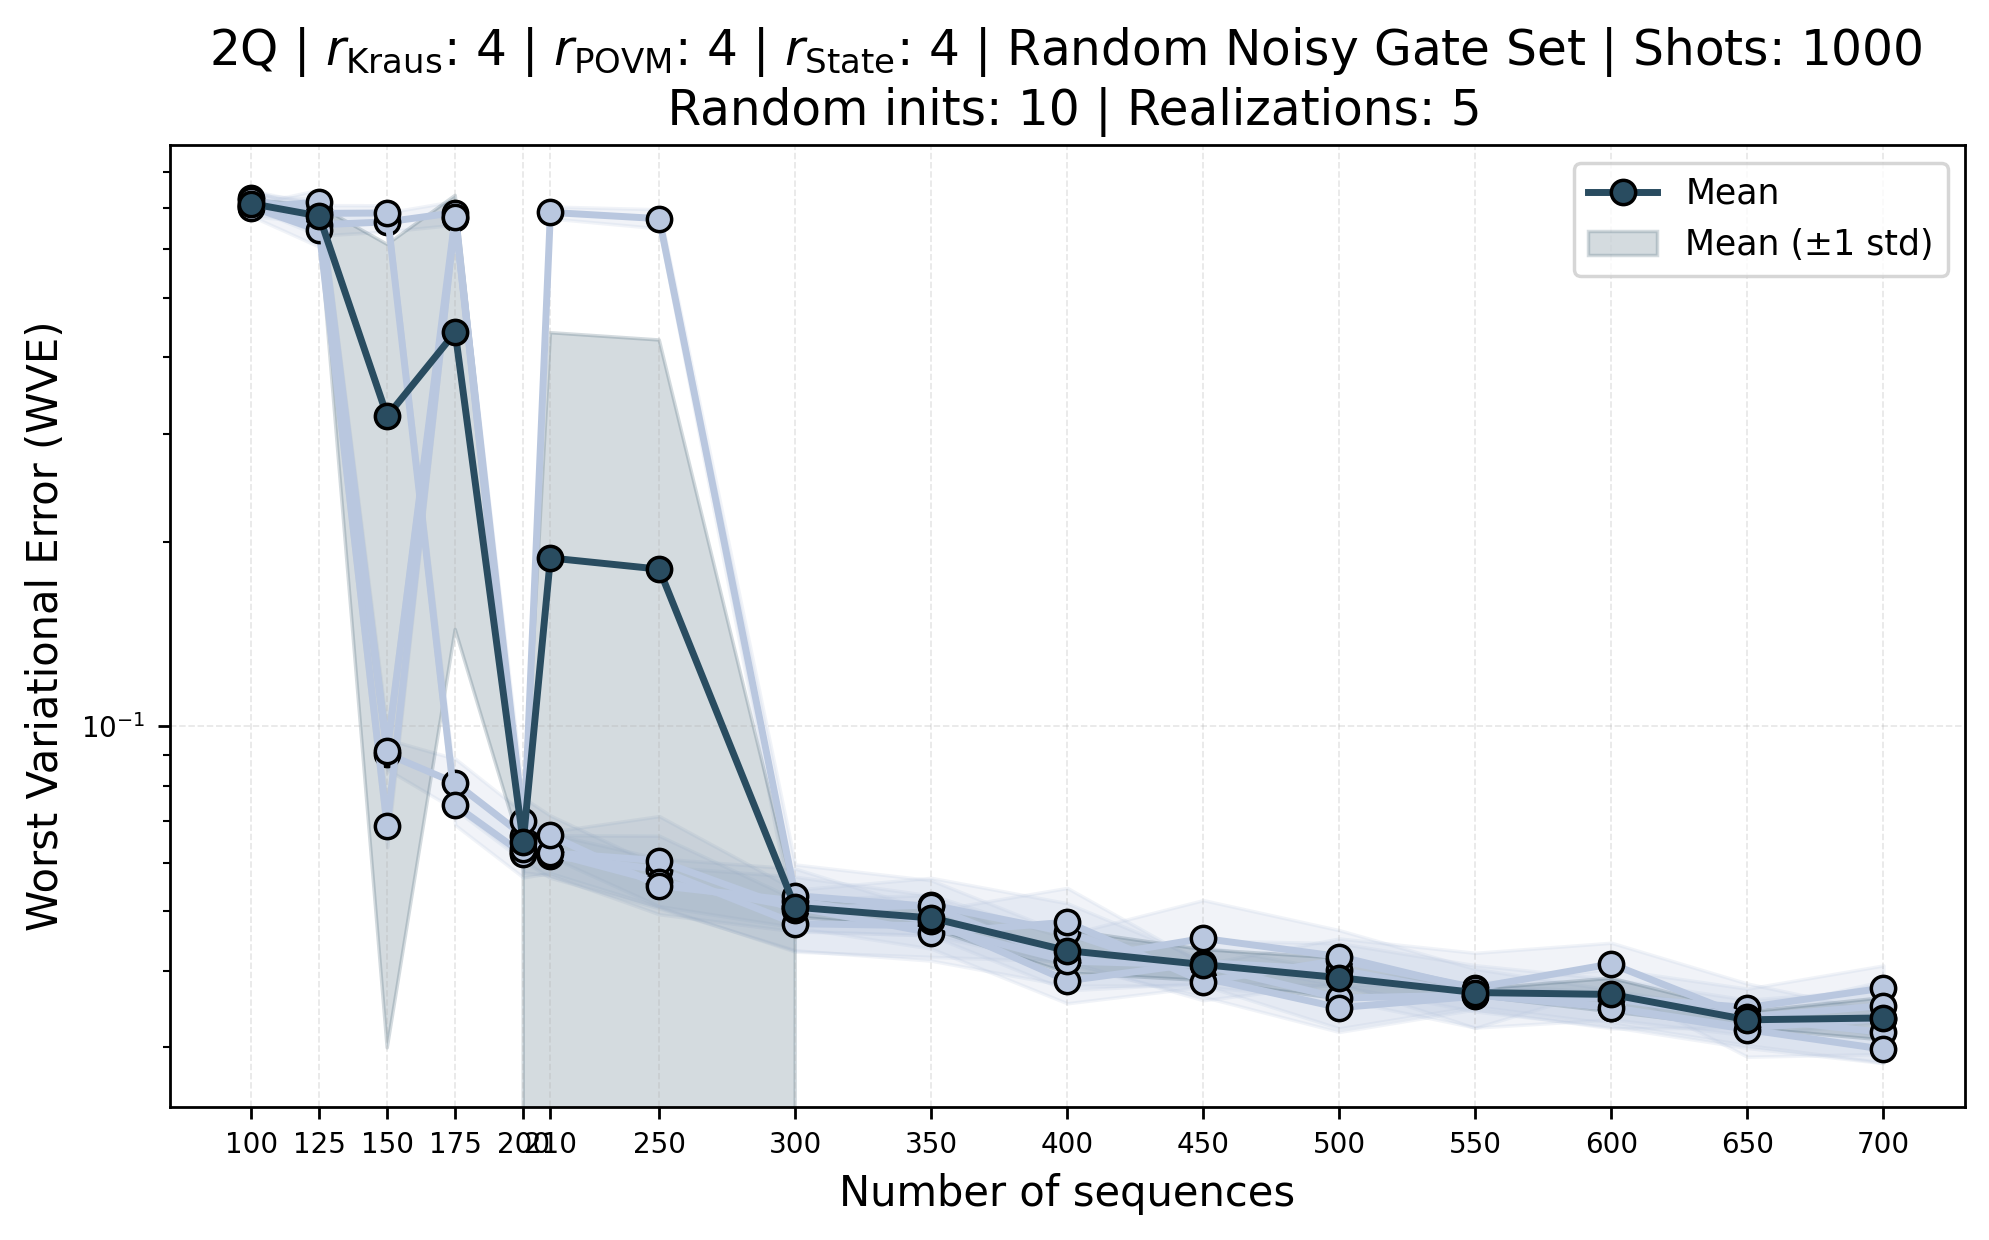

In [46]:
fig_all_wve = plot_many_mean_std_vs_x(
    data=wve_combined,
    title=title_mve,
    ylabel=f"Worst Variational Error (WVE)",
    use_log_scale="y",
    main_curve=mean_wve_results_combined,
    main_curve_label="Mean",
    # main_curve=result_1000_seq_dict,
    # main_curve_label="1000 Sequences (target init)",
    show=False,
)